# TOPIC 10 – ĐO LƯỜNG RỦI RO DANH MỤC VN30 BẰNG DCC-GARCH
## Notebook tích hợp toàn bộ: Thành viên 1 → 5 (chạy bằng **Restart Kernel → Run All**)

| Phần | Thành viên | Nội dung | Kết quả chính (biến trong bộ nhớ → file) |
|---|---|---|---|
| 0 | – | Cấu hình đường dẫn, hằng số dùng chung | `BASE_DIR`, `INPUT_DIR`, `OUTPUT_DIR` |
| 1 | Trang | Làm sạch dữ liệu, log return, Stylized Facts | `prices`, `log_ret` → `TV1_Data_EDA/` |
| 2 | Như | GARCH / GJR-GARCH × Normal / Student-t, chọn mô hình, phần dư | `std_resid`, `cond_vol`, `mu_vec` → `TV2_GARCH/` |
| 3 | Lâm | DCC-GARCH, so sánh CCC & Static, tương quan động | `R_t`, `H_t`, `H_fcst` → `TV3_DCC/` |
| 4 | Quỳnh | VaR, ES (Normal, Student-t, Historical), Backtesting, Basel | `var_es`, `bt_table` → `TV4_VaR_Backtest/` |
| 5 | Thủy Nguyên | Euler Risk Contribution, Stress Testing, kiểm tra tích hợp, khuyến nghị | `TV5_Euler_Stress/` |

**Cấu trúc thư mục:** `bản demo/` gồm `input/` (5 file `FPT.xlsx`, `HPG.xlsx`, `MWG.xlsx`, `VCB.xlsx`, `VHM.xlsx`),
`ouput/` (kết quả: `ouput/TV1_Data_EDA/` … `ouput/TV5_Euler_Stress/`), `code/` (notebook này).
Đường dẫn khai báo ở ô 0.2 (`PROJECT_PATH`, `OUTPUT_PATH`) – đổi máy thì chỉ sửa 2 dòng đó.

**Thư viện:** numpy, pandas, scipy, matplotlib, openpyxl (bắt buộc); statsmodels (dùng cho ADF/KPSS nếu đã cài – nếu chưa có,
notebook tự dùng bản viết tay, kết luận giống nhau). Mọi mô hình GARCH / DCC được **viết tay bằng scipy.optimize (MLE)**
để công thức hiện rõ trong code, không phụ thuộc thư viện `arch`.

**Quy tắc 3 tầng** (theo outline nhóm) được ghi trong ô markdown trước mỗi khối code:
Tầng 1 – công thức & ý nghĩa kinh tế · Tầng 2 – input / output / thư viện · Tầng 3 – cách đọc kết quả.

In [1]:
# ===================== 0.1 THƯ VIỆN =====================
import os                     # đọc biến môi trường
import re                     # biểu thức chính quy: tách dòng cổ tức / chia tách trong file Yahoo
import warnings               # tắt cảnh báo không cần thiết
import datetime as dt         # kiểu ngày tháng
from itertools import combinations   # tạo các cặp cổ phiếu
from pathlib import Path      # thao tác đường dẫn an toàn trên Windows

import numpy as np            # tính toán ma trận
import pandas as pd           # bảng dữ liệu
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats                     # phân phối Normal / t / chi-bình phương, JB
from scipy.optimize import minimize         # tối đa hoá hàm hợp lý (MLE)
from scipy.signal import lfilter            # lọc tuyến tính nhanh cho phương trình GARCH
from scipy.special import gammaln           # log Gamma cho mật độ Student-t

try:                                        # statsmodels: chỉ dùng cho ADF / KPSS (nếu có)
    from statsmodels.tsa.stattools import adfuller, kpss
    from statsmodels.tools.sm_exceptions import InterpolationWarning
    HAS_SM = True
except ImportError:
    HAS_SM = False

try:                                        # display() có sẵn trong Jupyter; chạy file .py thì thay bằng print
    display
except NameError:
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100
print("statsmodels có sẵn:", HAS_SM)

statsmodels có sẵn: True


In [2]:
# ===================== 0.2 CẤU HÌNH DÙNG CHUNG CHO CẢ 5 THÀNH VIÊN =====================
# >>> ĐƯỜNG DẪN – sửa 2 dòng này nếu đổi máy / đổi thư mục <<<
PROJECT_PATH = r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo"          # thư mục dự án (chứa input/, ouput/, code/)
OUTPUT_PATH = r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput"    # nơi lưu toàn bộ kết quả


def find_base_dir() -> Path:
    """Tìm thư mục dự án: biến môi trường PROJECT_DIR -> PROJECT_PATH -> thư mục cha của code/."""
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env)
    if Path(PROJECT_PATH).exists():
        return Path(PROJECT_PATH)
    cwd = Path.cwd()
    return cwd.parent if cwd.name.lower() == "code" else cwd


def pick_dir(base: Path, names) -> Path:
    """Chọn thư mục con đã tồn tại (chấp nhận Input/input)."""
    return next((base / n for n in names if (base / n).exists()), base / names[0])


BASE_DIR = find_base_dir()
INPUT_DIR = pick_dir(BASE_DIR, ["input", "Input"])
if not list(INPUT_DIR.glob("*.xlsx")):                  # dự phòng: thư mục Input cũ của Project midterm
    old_in = Path(r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Input")
    if list(old_in.glob("*.xlsx")):
        INPUT_DIR = old_in
# Output: biến môi trường OUTPUT_DIR -> OUTPUT_PATH (nếu ổ D: tồn tại) -> BASE_DIR/ouput
OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR") or
                  (OUTPUT_PATH if Path(OUTPUT_PATH).anchor and Path(Path(OUTPUT_PATH).anchor).exists()
                   else BASE_DIR / "ouput"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ROOT_OUT = OUTPUT_DIR                                    # mỗi thành viên một thư mục con trong ouput/
OUT = {k: ROOT_OUT / v for k, v in {"TV1": "TV1_Data_EDA", "TV2": "TV2_GARCH", "TV3": "TV3_DCC",
                                     "TV4": "TV4_VaR_Backtest", "TV5": "TV5_Euler_Stress"}.items()}
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- Hằng số dùng chung ----
TICKERS_ORDER = ["FPT", "HPG", "MWG", "VCB", "VHM"]    # thứ tự hiển thị (mã khác trong Input vẫn được đọc)
ALPHA = 0.05                 # mức ý nghĩa của mọi kiểm định
LB_LAGS = [5, 10, 20]        # số trễ Ljung-Box
TRADING_DAYS = 252           # số phiên / năm để năm hoá
SCALE = 100.0                # ước lượng GARCH trên lợi suất % (r × 100) cho ổn định số học
SELECT_BY = "BIC"            # tiêu chí chọn mô hình GARCH: "AIC" hoặc "BIC"
PAIRS = [("VCB", "VHM"), ("HPG", "FPT")]               # cặp tương quan động theo đề
VAR_LEVELS = [0.95, 0.99]    # mức tin cậy VaR
HS_WINDOW = 250              # cửa sổ Historical Simulation (≈ 1 năm)
BASEL_WINDOW = 250           # cửa sổ Basel Traffic Light (250 phiên gần nhất)
VIOL_MODEL = "Normal"        # >>> MÔ HÌNH ĐÁNH DẤU VI PHẠM TRÊN MỌI HÌNH & DIỄN GIẢI TV4: "Normal" hoặc "t" <<<
VIOL_OOS = {"Normal": "DCC-N", "t": "DCC-t"}[VIOL_MODEL]   # tên tương ứng trong phần ngoài mẫu
EULER_CL = 0.99              # mức tin cậy dùng cho phân bổ rủi ro Euler
STRESS = {                   # giai đoạn khủng hoảng theo đề (TV5)
    "Covid-19 (02–04/2020)": ("2020-02-01", "2020-04-30"),
    "Trái phiếu & lãi suất (04–11/2022)": ("2022-04-01", "2022-11-30"),
}


STRESS_COLORS = ["tab:red", "tab:orange"]   # mỗi giai đoạn một màu để phân biệt Covid-19 với Trái phiếu & lãi suất


def shade_stress(ax, alpha=0.12, label=True, xlim=None):
    """Tô màu từng giai đoạn khủng hoảng (mỗi giai đoạn một màu, chú thích theo tên giai đoạn).
    xlim=(đầu, cuối): bỏ qua giai đoạn nằm hoàn toàn ngoài khoảng này (tránh kéo giãn trục thời gian)."""
    for (name, (s, e)), c in zip(STRESS.items(), STRESS_COLORS):
        s, e = pd.Timestamp(s), pd.Timestamp(e)
        if xlim is not None and (e < xlim[0] or s > xlim[1]):
            continue
        ax.axvspan(s, e, color=c, alpha=alpha, label=(name if label else None))


def grid_axes(n, ncol=2, h=3.2, w=13, **kw):
    """Tạo lưới ô vẽ cho n mã, ẩn các ô thừa."""
    ncol = min(ncol, n)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w, h * nrow), squeeze=False, **kw)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


print("BASE_DIR  :", BASE_DIR)
print("INPUT_DIR :", INPUT_DIR, "| tồn tại:", INPUT_DIR.exists())
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR  : D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo
INPUT_DIR : D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\input | tồn tại: True
OUTPUT_DIR: D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput


---
# THÀNH VIÊN 1: DATA PIPELINE & KHÁM PHÁ DỮ LIỆU (EDA & STYLIZED FACTS)
## 1.1 – 1.2 Thu thập & làm sạch dữ liệu
5 cổ phiếu VN30 đại diện 5 ngành: **VCB** (ngân hàng), **HPG** (thép), **FPT** (công nghệ), **MWG** (bán lẻ), **VHM** (bất động sản),
giai đoạn 2019–2024 (bao trùm Covid-19 và khủng hoảng trái phiếu 2022), tải từ Yahoo Finance.

**Tầng 1 – Ý nghĩa:**
- *Adjusted Close* đã điều chỉnh chia tách cổ phiếu và cổ tức ⇒ lợi suất tính từ Adj Close là lợi suất **tổng** thực nhận của nhà đầu tư,
  không bị "rơi giá" giả vào ngày giao dịch không hưởng quyền. Hệ số điều chỉnh $f_t = \text{Adj Close}_t / \text{Close}_t$.
- *Ngày nghỉ lễ / Tết*: file Yahoo vẫn có dòng cho ngày nghỉ với Volume = 0 (hoặc "-") ⇒ không phải phiên giao dịch thật, phải loại bỏ,
  nếu không sẽ sinh ra nhiều lợi suất = 0 giả làm méo phương sai và tự tương quan. Ngoài ngày lễ, Yahoo còn **thiếu dữ liệu** một số
  ngày giao dịch bình thường; notebook đối chiếu với lịch nghỉ HOSE (`VN_HOLIDAYS`) để tách hai loại này (`non_trading_days.csv`).
- *Calendar alignment*: mô hình đa biến (DCC) cần ma trận lợi suất **cùng ngày** cho cả 5 mã ⇒ dựng lịch chuẩn chung, mã nào tạm ngừng
  giao dịch thì giữ giá phiên trước (forward-fill, tối đa 10 phiên).

**Tầng 2 – Input / Output:** Input: 5 file `.xlsx` trong `Input/` (tiêu đề cột kiểu Yahoo, số có dấu phẩy nghìn, chen dòng
"Dividend" / "Stock Splits"). Output: `prices` (DataFrame Adj Close đã căn lịch, T × 5), `clean_by_ticker/*.csv`, `cleaning_report.txt`.

**Tầng 3 – Cách đọc:** nhật ký in ra số dòng sự kiện đã tách, số ngày nghỉ lễ và số ngày thiếu dữ liệu, số phiên điền giá cho từng mã,
và bảng các ngày lợi suất vượt biên độ ±7% của HOSE kèm nguyên nhân (lợi suất dồn qua kỳ nghỉ hoặc qua ngày thiếu dữ liệu).
Toàn bộ nhật ký được ghi vào `cleaning_report.txt`; bảng ngoại lai lưu ở `outliers_check.csv`.

In [3]:
# ===================== 1.1 ĐỌC DỮ LIỆU THÔ =====================
REQUIRED_COLS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
FFILL_LIMIT = 10          # tối đa số phiên liên tiếp được điền giá khi cổ phiếu tạm ngừng giao dịch
GAP_THRESHOLD_DAYS = 4    # 2 phiên thật cách nhau > 4 ngày lịch => ghi nhận kỳ nghỉ dài
PRICE_LIMIT = 0.07        # biên độ dao động giá ngày của HOSE (±7%)
EVENTS = {}               # sự kiện cổ tức / chia tách tách ra từ file Yahoo
REPORT = []               # nhật ký làm sạch -> cleaning_report.txt


def log(msg=""):
    print(msg)
    REPORT.append(str(msg))


def _map_col(col):
    """Chuẩn hoá tên cột: 'Adj Close     Adjusted close price...' -> 'Adj Close'."""
    c = str(col).strip().lower()
    for key, name in [("adj", "Adj Close"), ("date", "Date"), ("open", "Open"), ("high", "High"),
                      ("low", "Low"), ("close", "Close"), ("volume", "Volume")]:
        if c.startswith(key):
            return name
    return col


def _to_number(s: pd.Series) -> pd.Series:
    """Đọc số an toàn: '1,234.56', '1.234,56', '-', '#N/A' ... -> float (ô không phải số -> NaN)."""
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce")

    def conv(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        t = str(v).strip().replace("\u00a0", "").replace(" ", "")
        if t in ("", "-", "--", "#N/A", "N/A", "NA", "nan", "None"):
            return np.nan
        if "," in t and "." in t:                    # dấu xuất hiện sau cùng là dấu thập phân
            t = t.replace(".", "").replace(",", ".") if t.rfind(",") > t.rfind(".") else t.replace(",", "")
        elif "," in t:
            t = t.replace(",", "") if re.fullmatch(r"-?\d{1,3}(,\d{3})+", t) else t.replace(",", ".")
        elif t.count(".") > 1:
            t = t.replace(".", "")
        try:
            return float(t)
        except ValueError:
            return np.nan
    return s.map(conv).astype(float)


def _parse_dates(s: pd.Series, swap: bool) -> pd.Series:
    """Đọc cột ngày hỗn hợp (datetime thật + chuỗi dd/mm/yyyy). swap=True: đảo ngày<->tháng cho ô Excel đã tự đổi sai."""
    out = []
    for v in s:
        if pd.isna(v):
            out.append(pd.NaT)
        elif isinstance(v, (pd.Timestamp, dt.datetime, dt.date)):
            ts = pd.Timestamp(v)
            if swap and ts.day <= 12:
                ts = pd.Timestamp(year=ts.year, month=ts.day, day=ts.month)
            out.append(ts)
        else:
            txt = str(v).strip()
            iso = re.match(r"^\d{4}-\d{2}-\d{2}", txt) is not None
            out.append(pd.to_datetime(txt, dayfirst=not iso, errors="coerce"))
    return pd.Series(pd.to_datetime(out), index=s.index)


def parse_dates(s: pd.Series, name: str) -> pd.Series:
    """Thử 2 cách đọc ngày, chọn cách cho chuỗi đúng thứ tự thời gian và ít ngày trùng nhất."""
    def score(d):
        diff = d.dropna().diff().dropna()
        order = int(min((diff < pd.Timedelta(0)).sum(), (diff > pd.Timedelta(0)).sum()))
        return order + int(d.dropna().duplicated().sum())
    cands = {False: _parse_dates(s, False)}
    if any(isinstance(v, (pd.Timestamp, dt.datetime, dt.date)) for v in s):
        cands[True] = _parse_dates(s, True)
    best = min(cands, key=lambda k: score(cands[k]))
    if best:
        log(f"  - {name}: phát hiện ngày bị Excel đảo ngày/tháng -> đã sửa")
    return cands[best]


def load_stock(path: Path) -> pd.DataFrame:
    """Đọc 1 file Excel -> DataFrame index = Date, các cột số chuẩn hoá; tách dòng sự kiện cổ tức/chia tách."""
    tk = path.stem.upper()
    df = pd.read_excel(path, sheet_name=0)
    df.columns = [_map_col(c) for c in df.columns]
    missing = [c for c in ["Date"] + REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name}: thiếu cột {missing}")
    df = df[["Date"] + REQUIRED_COLS].copy()
    raw = df[REQUIRED_COLS].map(lambda v: "" if pd.isna(v) else str(v))   # dạng chuỗi để dò dòng sự kiện
    df["Date"] = parse_dates(df["Date"], tk)

    # Dòng sự kiện: Yahoo chen "790.5 Dividend ..." hoặc "23:20 Stock Splits ..." vào bảng giá
    is_event = raw.apply(lambda c: c.str.contains(r"dividend|stock\s*split", case=False, regex=True)).any(axis=1)
    if is_event.any():
        txt = raw.loc[is_event].apply(lambda r: next((v for v in r if re.search("ividend|plit", str(v))), ""), axis=1)
        m = txt.str.extract(r"^\s*([\d.,:]+)\s*(Dividend|Stock\s*Splits?)", flags=re.I)
        EVENTS[tk] = pd.DataFrame({"Date": df.loc[is_event, "Date"].values, "Ticker": tk,
                                   "Type": m[1].str.title().values, "Value": m[0].values}).drop_duplicates()
        n_div = int((EVENTS[tk]["Type"] == "Dividend").sum())
        log(f"      {tk}: tách {int(is_event.sum())} dòng sự kiện ({n_div} cổ tức, "
            f"{len(EVENTS[tk]) - n_div} chia tách/cổ phiếu thưởng)")
        df = df.loc[~is_event].copy()

    for c in REQUIRED_COLS:
        df[c] = _to_number(df[c])
    n_bad = int(df["Date"].isna().sum())
    df = df.dropna(subset=["Date"])
    df["Date"] = df["Date"].dt.normalize()
    n_dup = int(df["Date"].duplicated().sum())
    df = df.drop_duplicates(subset="Date", keep="last").sort_values("Date").set_index("Date")
    log(f"  - Đọc {path.name}: {len(df)} dòng | {df.index.min().date()} -> {df.index.max().date()} "
        f"| ngày lỗi bỏ: {n_bad} | ngày trùng bỏ: {n_dup}")
    return df


REPORT.clear()
files = sorted(p for p in INPUT_DIR.glob("*.xlsx") if not p.name.startswith("~$"))
if not files:
    raise FileNotFoundError(f"Không tìm thấy file .xlsx trong {INPUT_DIR}")
log("=" * 78); log("ĐỌC DỮ LIỆU"); log("=" * 78)
raw = {p.stem.upper(): load_stock(p) for p in files}
raw = {tk: raw[tk] for tk in [t for t in TICKERS_ORDER if t in raw] + [t for t in raw if t not in TICKERS_ORDER]}

ĐỌC DỮ LIỆU
      FPT: tách 18 dòng sự kiện (12 cổ tức, 6 chia tách/cổ phiếu thưởng)
  - Đọc FPT.xlsx: 1561 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
      HPG: tách 8 dòng sự kiện (3 cổ tức, 5 chia tách/cổ phiếu thưởng)
  - Đọc HPG.xlsx: 1561 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
      MWG: tách 8 dòng sự kiện (6 cổ tức, 2 chia tách/cổ phiếu thưởng)
  - Đọc MWG.xlsx: 1554 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
      VCB: tách 5 dòng sự kiện (3 cổ tức, 2 chia tách/cổ phiếu thưởng)
  - Đọc VCB.xlsx: 1554 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
      VHM: tách 4 dòng sự kiện (3 cổ tức, 1 chia tách/cổ phiếu thưởng)
  - Đọc VHM.xlsx: 1561 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0


In [4]:
# ===================== 1.2a BƯỚC 1 – GIÁ ĐÓNG CỬA ĐIỀU CHỈNH =====================
log(""); log("=" * 78); log("BƯỚC 1: GIÁ ĐÓNG CỬA ĐIỀU CHỈNH (ADJUSTED CLOSE)"); log("=" * 78)
adj = {}
for tk, df in raw.items():
    df = df.copy()
    for c in ["Open", "High", "Low", "Close", "Adj Close"]:
        df.loc[df[c] <= 0, c] = np.nan                     # giá <= 0 không hợp lệ
    df["Adj_Factor"] = df["Adj Close"] / df["Close"]        # hệ số điều chỉnh f_t
    for c in ["Open", "High", "Low"]:
        df[f"Adj_{c}"] = df[c] * df["Adj_Factor"]           # điều chỉnh OHLC theo cùng hệ số
    n_chg = int((df["Adj_Factor"].pct_change().abs() > 1e-4).sum())
    bad_hl = int((df["High"] < df["Low"]).sum())
    log(f"  [{tk}] Adj_Factor: {df['Adj_Factor'].min():.4f} – {df['Adj_Factor'].max():.4f} "
        f"| số ngày hệ số thay đổi (cổ tức/chia tách): {n_chg} | High<Low: {bad_hl}")
    adj[tk] = df


BƯỚC 1: GIÁ ĐÓNG CỬA ĐIỀU CHỈNH (ADJUSTED CLOSE)
  [FPT] Adj_Factor: 0.8212 – 0.9678 | số ngày hệ số thay đổi (cổ tức/chia tách): 12 | High<Low: 0
  [HPG] Adj_Factor: 0.9344 – 0.9820 | số ngày hệ số thay đổi (cổ tức/chia tách): 3 | High<Low: 0
  [MWG] Adj_Factor: 0.9025 – 0.9579 | số ngày hệ số thay đổi (cổ tức/chia tách): 6 | High<Low: 0
  [VCB] Adj_Factor: 0.9634 – 0.9846 | số ngày hệ số thay đổi (cổ tức/chia tách): 3 | High<Low: 0
  [VHM] Adj_Factor: 0.9076 – 0.9630 | số ngày hệ số thay đổi (cổ tức/chia tách): 3 | High<Low: 0


In [5]:
# ===================== 1.2b BƯỚC 2 – NGÀY NGHỈ LỄ, TẾT, KHÔNG GIAO DỊCH =====================
log(""); log("=" * 78); log("BƯỚC 2: NGÀY NGHỈ LỄ, TẾT & NGÀY KHÔNG GIAO DỊCH"); log("=" * 78)
trading = {}
for tk, df in adj.items():
    df = df[df.index.dayofweek < 5].dropna(subset=["Adj Close"]).copy()   # bỏ T7/CN và dòng thiếu giá
    df["Volume"] = df["Volume"].fillna(0)
    df["Is_Traded"] = df["Volume"] > 0                                     # Volume = 0 / "-" => ngày nghỉ
    real = df.index[df["Is_Traded"]].to_series()
    gaps = real.diff().dt.days
    long_gaps = gaps[gaps > GAP_THRESHOLD_DAYS]
    log(f"  [{tk}] dòng Volume=0 (không GD): {int((~df['Is_Traded']).sum())} "
        f"| số kỳ nghỉ dài > {GAP_THRESHOLD_DAYS} ngày: {len(long_gaps)} "
        f"(vd: " + ", ".join(f"{(d - pd.Timedelta(days=int(g))).date()}→{d.date()}"
                             for d, g in long_gaps.head(3).items()) + ")")
    trading[tk] = df


BƯỚC 2: NGÀY NGHỈ LỄ, TẾT & NGÀY KHÔNG GIAO DỊCH
  [FPT] dòng Volume=0 (không GD): 114 | số kỳ nghỉ dài > 4 ngày: 22 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [HPG] dòng Volume=0 (không GD): 116 | số kỳ nghỉ dài > 4 ngày: 22 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [MWG] dòng Volume=0 (không GD): 114 | số kỳ nghỉ dài > 4 ngày: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [VCB] dòng Volume=0 (không GD): 121 | số kỳ nghỉ dài > 4 ngày: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-03→2019-07-17)
  [VHM] dòng Volume=0 (không GD): 127 | số kỳ nghỉ dài > 4 ngày: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-03→2019-07-17)


In [6]:
# ===================== 1.2c BƯỚC 3 – CĂN CHỈNH LỊCH GIAO DỊCH =====================
log(""); log("=" * 78); log("BƯỚC 3: CĂN CHỈNH LỊCH GIAO DỊCH (CALENDAR ALIGNMENT)"); log("=" * 78)
start = max(df.index.min() for df in trading.values())       # giai đoạn chung của cả 5 mã
end = min(df.index.max() for df in trading.values())
traded_days = sorted(set().union(*[set(df.index[df["Is_Traded"]]) for df in trading.values()]))
master = pd.DatetimeIndex(traded_days)
master = master[(master >= start) & (master <= end)]          # lịch chuẩn = ngày có ít nhất 1 mã giao dịch
holidays = pd.bdate_range(master.min(), master.max()).difference(master)   # ngày T2–T6 không mã nào có giao dịch

# Lịch nghỉ lễ chính thức của HOSE 2019–2024 (Tết Dương lịch, Tết Nguyên đán, Giỗ Tổ, 30/4–1/5, Quốc khánh, kể cả ngày nghỉ bù).
# Ngày không giao dịch nằm NGOÀI danh sách này = ngày file Yahoo thiếu dữ liệu, không phải ngày nghỉ của thị trường.
VN_HOLIDAYS = pd.to_datetime([
    "2019-01-01", "2019-02-04", "2019-02-05", "2019-02-06", "2019-02-07", "2019-02-08", "2019-04-15",
    "2019-04-29", "2019-04-30", "2019-05-01", "2019-09-02",
    "2020-01-01", "2020-01-23", "2020-01-24", "2020-01-27", "2020-01-28", "2020-01-29", "2020-04-02",
    "2020-04-30", "2020-05-01", "2020-09-02",
    "2021-01-01", "2021-02-10", "2021-02-11", "2021-02-12", "2021-02-15", "2021-02-16", "2021-04-21",
    "2021-04-30", "2021-05-03", "2021-09-02", "2021-09-03",
    "2022-01-03", "2022-01-31", "2022-02-01", "2022-02-02", "2022-02-03", "2022-02-04", "2022-04-11",
    "2022-05-02", "2022-05-03", "2022-09-01", "2022-09-02",
    "2023-01-02", "2023-01-20", "2023-01-23", "2023-01-24", "2023-01-25", "2023-01-26",
    "2023-05-01", "2023-05-02", "2023-05-03", "2023-09-01", "2023-09-04",
    "2024-01-01", "2024-02-08", "2024-02-09", "2024-02-12", "2024-02-13", "2024-02-14", "2024-04-18",
    "2024-04-29", "2024-04-30", "2024-05-01", "2024-09-02", "2024-09-03",
])
is_holiday = holidays.isin(VN_HOLIDAYS)
non_trading = pd.DataFrame({"Date": holidays, "Thứ": holidays.day_name(),
                            "Phân loại": np.where(is_holiday, "Nghỉ lễ/Tết (lịch HOSE)",
                                                  "Không có dữ liệu (file Yahoo thiếu dòng/Volume=0)")})
missing_days = holidays[~is_holiday]
log(f"  Giai đoạn chung: {start.date()} -> {end.date()} | số phiên lịch chuẩn: {len(master)}")
log(f"  Ngày T2–T6 không có dữ liệu giao dịch ở cả 5 mã: {len(holidays)} = "
    f"{int(is_holiday.sum())} ngày nghỉ lễ/Tết + {len(missing_days)} ngày Yahoo thiếu dữ liệu")
if len(missing_days):
    log("    Ví dụ ngày thiếu dữ liệu: " + ", ".join(str(d.date()) for d in missing_days[:8]) + " ...")

price_cols = ["Open", "High", "Low", "Close", "Adj Close", "Adj_Open", "Adj_High", "Adj_Low", "Adj_Factor"]
aligned = {}
for tk, df in trading.items():
    a = df.reindex(master)
    a.index.name = "Date"
    a["Is_Traded"] = a["Is_Traded"].fillna(False).astype(bool)
    a["Volume"] = a["Volume"].fillna(0)
    a[price_cols] = a[price_cols].ffill(limit=FFILL_LIMIT)    # mã tạm ngừng GD: giữ giá phiên trước
    log(f"  [{tk}] phiên GD thật: {int(a['Is_Traded'].sum())}/{len(master)} "
        f"| phiên điền giá: {int((~a['Is_Traded']).sum())} | NaN còn lại: {int(a['Adj Close'].isna().sum())}")
    aligned[tk] = a

prices = pd.DataFrame({tk: a["Adj Close"] for tk, a in aligned.items()}).dropna()   # panel cân bằng
for tk in aligned:
    aligned[tk] = aligned[tk].loc[prices.index]
tickers = list(prices.columns)
N = len(tickers)
log(f"  Panel giá cuối cùng: {prices.shape[0]} phiên × {N} mã ({', '.join(tickers)})")

# ---- Chẩn đoán ngày lợi suất vượt biên độ ±7% ----
sr = prices.pct_change().iloc[1:]
rows = []
for tk in tickers:
    traded_idx = aligned[tk].index[aligned[tk]["Is_Traded"]]
    for d in sr.index[sr[tk].abs() > PRICE_LIMIT + 0.005]:
        prev = traded_idx[traded_idx < d]
        gap = (d - prev[-1]).days if len(prev) else np.nan
        if len(prev):
            n_miss = int(((missing_days > prev[-1]) & (missing_days < d)).sum())     # ngày cả thị trường thiếu dữ liệu
            n_hol = int(((VN_HOLIDAYS > prev[-1]) & (VN_HOLIDAYS < d)).sum())         # ngày nghỉ lễ
            n_own = int(((master > prev[-1]) & (master < d)).sum())                   # phiên thị trường có GD nhưng riêng mã này không
        else:
            n_miss = n_hol = n_own = 0
        parts = []                                                   # một ngày có thể có nhiều nguyên nhân cùng lúc
        if n_hol:
            parts.append(f"sau {n_hol} ngày nghỉ lễ")
        if n_miss:
            parts.append(f"qua {n_miss} ngày Yahoo thiếu dữ liệu")
        if n_own:
            parts.append(f"mã thiếu dữ liệu riêng {n_own} phiên")
        why = ("Dồn lợi suất nhiều ngày: " + "; ".join(parts)) if parts \
            else "Biến động thật / ngoại lệ biên độ (vd. ngày hưởng quyền)"
        rows.append({"Date": d.date(), "Mã": tk, "Lợi suất": round(sr.loc[d, tk], 4),
                     "Phiên GD liền trước": prev[-1].date() if len(prev) else None, "Cách phiên trước (ngày)": gap,
                     "Ngày lễ ở giữa": n_hol, "Ngày thiếu dữ liệu ở giữa": n_miss, "Phiên mã này không GD": n_own,
                     "Nguyên nhân": why})
outliers = pd.DataFrame(rows)
log(f"\n  Số ngày |lợi suất| > ±{PRICE_LIMIT:.0%} (+0,5% dung sai): {len(outliers)}")
if len(outliers):
    log(outliers.to_string(index=False))                    # ghi cả bảng vào cleaning_report.txt
    log("\n  Tổng hợp nguyên nhân:\n" + outliers["Nguyên nhân"].value_counts().to_string())

# ---- Lưu kết quả làm sạch ----
(OUT["TV1"] / "clean_by_ticker").mkdir(exist_ok=True)
for tk, a in aligned.items():
    a.to_csv(OUT["TV1"] / "clean_by_ticker" / f"{tk}_clean.csv", encoding="utf-8-sig")
prices.to_csv(OUT["TV1"] / "panel_AdjClose.csv", encoding="utf-8-sig")
if EVENTS:
    pd.concat(EVENTS.values()).sort_values(["Ticker", "Date"]).to_csv(
        OUT["TV1"] / "corporate_events.csv", index=False, encoding="utf-8-sig")
non_trading.to_csv(OUT["TV1"] / "non_trading_days.csv", index=False, encoding="utf-8-sig")   # thay cho market_holidays_detected.csv
outliers.to_csv(OUT["TV1"] / "outliers_check.csv", index=False, encoding="utf-8-sig")
(OUT["TV1"] / "cleaning_report.txt").write_text("\n".join(REPORT), encoding="utf-8")
print("✔ Đã lưu dữ liệu sạch vào", OUT["TV1"])


BƯỚC 3: CĂN CHỈNH LỊCH GIAO DỊCH (CALENDAR ALIGNMENT)
  Giai đoạn chung: 2019-01-01 -> 2024-12-30 | số phiên lịch chuẩn: 1453
  Ngày T2–T6 không có dữ liệu giao dịch ở cả 5 mã: 111 = 65 ngày nghỉ lễ/Tết + 46 ngày Yahoo thiếu dữ liệu
    Ví dụ ngày thiếu dữ liệu: 2019-02-18, 2019-07-25, 2019-07-26, 2019-07-29, 2019-07-30, 2019-08-06, 2019-12-03, 2019-12-04 ...
  [FPT] phiên GD thật: 1447/1453 | phiên điền giá: 6 | NaN còn lại: 0
  [HPG] phiên GD thật: 1445/1453 | phiên điền giá: 8 | NaN còn lại: 0
  [MWG] phiên GD thật: 1440/1453 | phiên điền giá: 13 | NaN còn lại: 0
  [VCB] phiên GD thật: 1433/1453 | phiên điền giá: 20 | NaN còn lại: 0
  [VHM] phiên GD thật: 1434/1453 | phiên điền giá: 19 | NaN còn lại: 0
  Panel giá cuối cùng: 1453 phiên × 5 mã (FPT, HPG, MWG, VCB, VHM)

  Số ngày |lợi suất| > ±7% (+0,5% dung sai): 6
      Date  Mã  Lợi suất Phiên GD liền trước  Cách phiên trước (ngày)  Ngày lễ ở giữa  Ngày thiếu dữ liệu ở giữa  Phiên mã này không GD                                  

## 1.3 Tính Log Returns & trực quan hoá
**Tầng 1:** $r_t = \ln\left(\dfrac{P_t}{P_{t-1}}\right)$ với $P_t$ = Adj Close. Log return cộng được theo thời gian
($\sum r_t = \ln P_T/P_0$) và xấp xỉ lợi suất đơn khi biến động nhỏ ⇒ là đầu vào chuẩn cho GARCH.

**Tầng 2:** Input `prices` (T × N). Output `log_ret` ((T−1) × N, đơn vị thập phân) – **biến dùng chung cho TV2 → TV5**.

**Tầng 3:** Biểu đồ giá có xu hướng (không dừng); biểu đồ lợi suất dao động quanh 0 nhưng có những **cụm** biến động lớn
(2020, 2022) xen kẽ cụm yên tĩnh – dấu hiệu đầu tiên của volatility clustering.

Log return: 1452 phiên × 5 mã | 2019-01-03 -> 2024-12-30 | NaN: 0


,FPT,HPG,MWG,VCB,VHM
Date,,,,,
2019-01-03,-0.009756,-0.043124,-0.029676,0.000000,-0.004090
2019-01-04,0.007326,0.006757,0.007203,0.014815,0.010870
2019-01-07,0.016888,-0.011855,0.016608,0.003670,0.002699
2019-01-08,0.004773,-0.017182,-0.011835,0.007299,0.000000
2019-01-09,0.009479,0.022280,0.016529,0.014441,0.000000


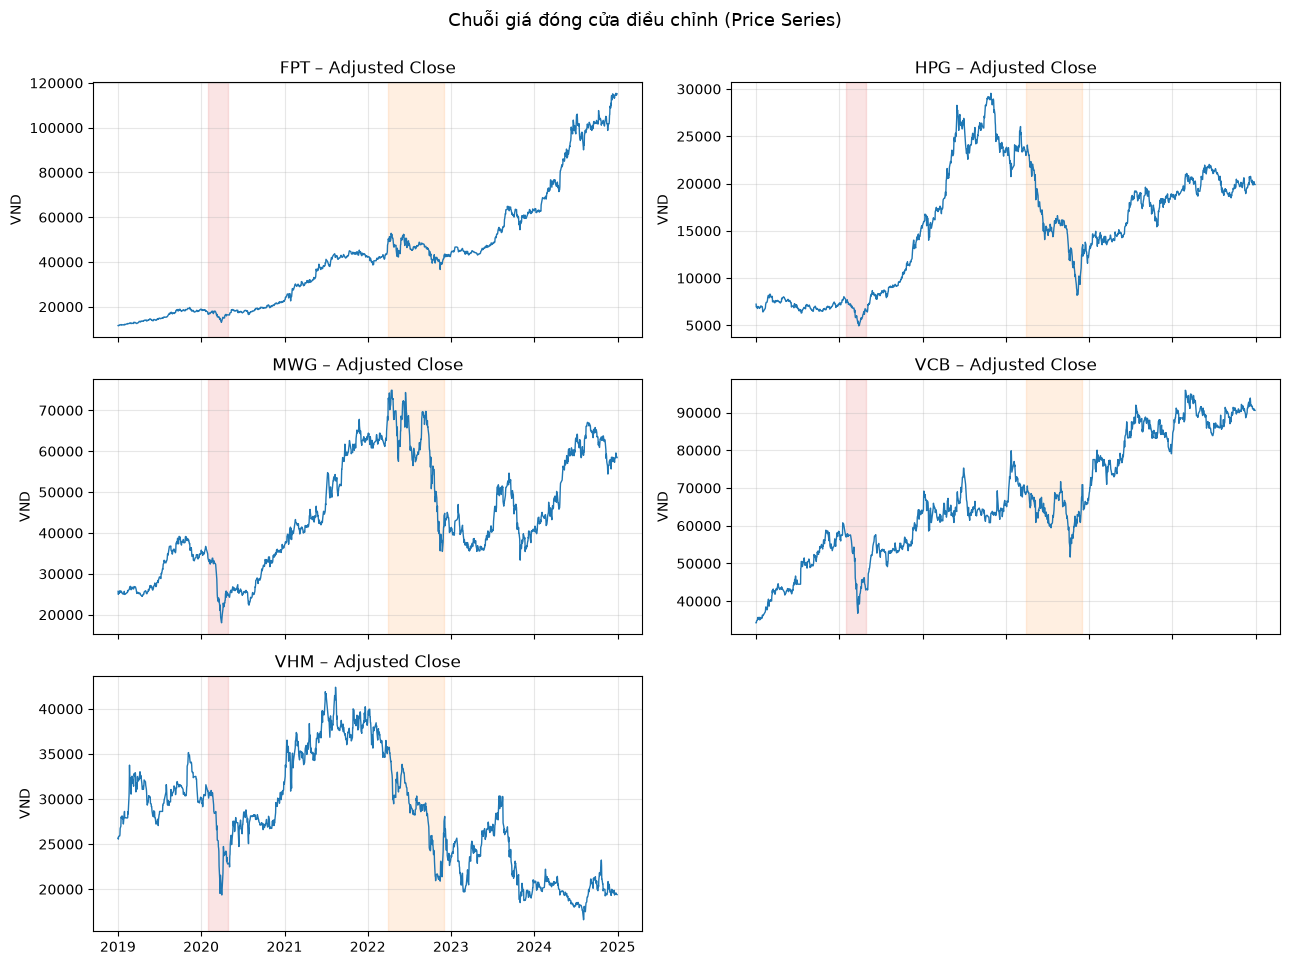

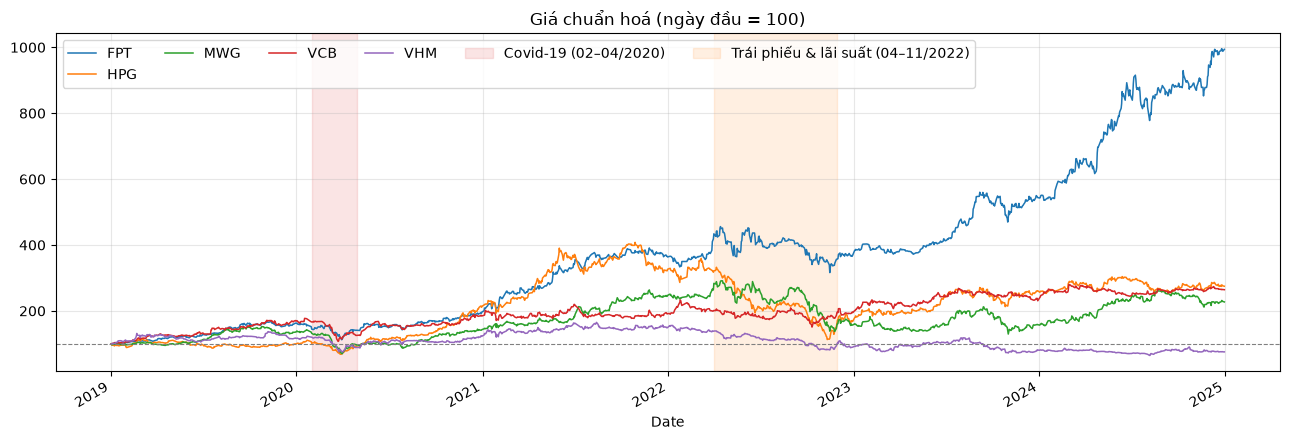

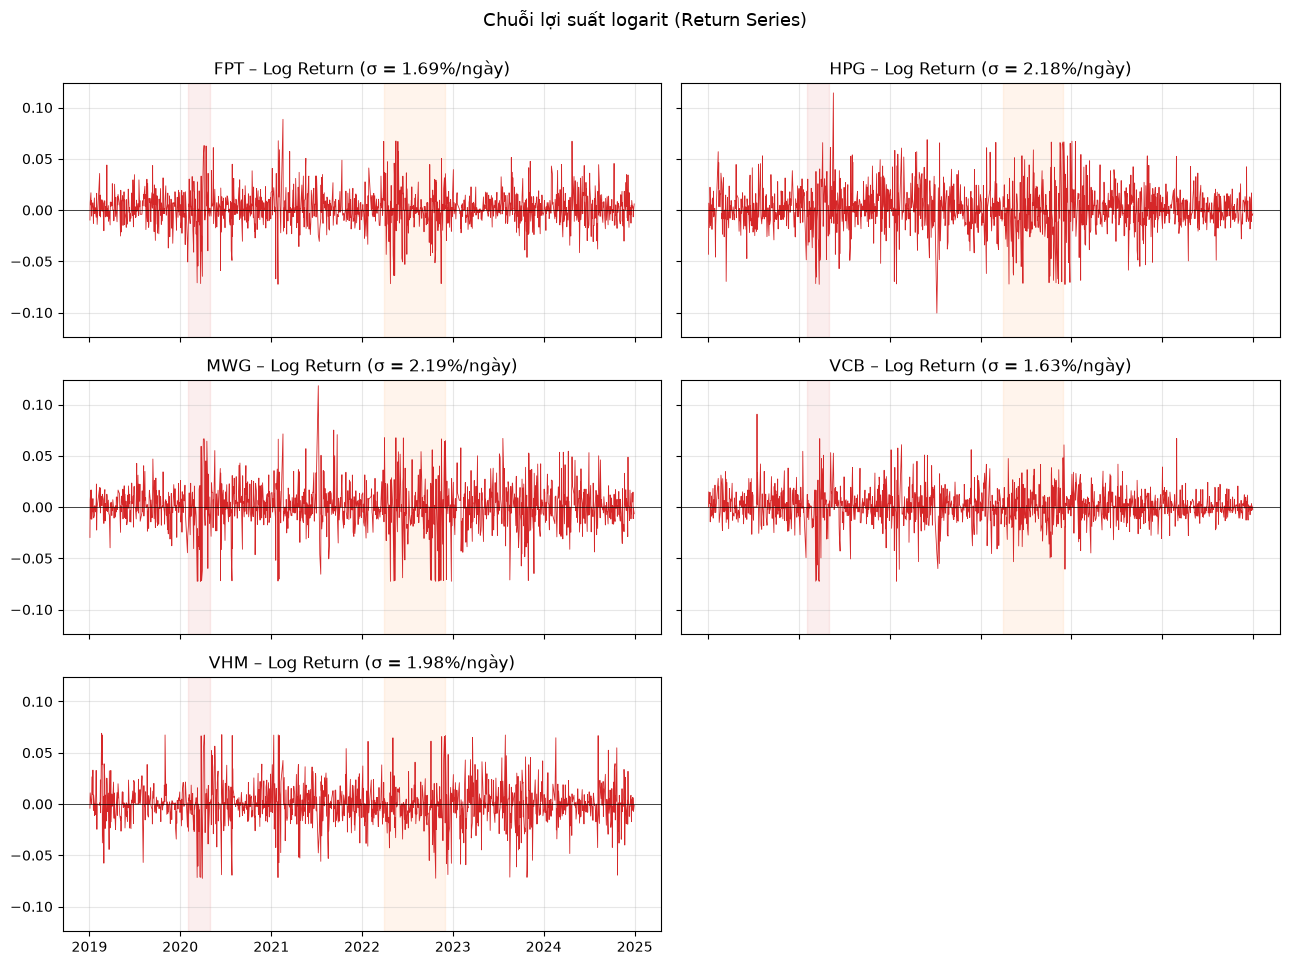

In [7]:
# ===================== 1.3 LOG RETURNS + BIỂU ĐỒ =====================
log_ret = np.log(prices / prices.shift(1)).iloc[1:]          # r_t = ln(P_t / P_{t-1})
log_ret.index.name = "Date"
T = len(log_ret)
print(f"Log return: {T} phiên × {N} mã | {log_ret.index.min().date()} -> {log_ret.index.max().date()} "
      f"| NaN: {int(log_ret.isna().sum().sum())}")
display(log_ret.head())
log_ret.to_csv(OUT["TV1"] / "log_returns.csv", encoding="utf-8-sig")

# (a) Chuỗi giá – mỗi mã một ô vì thang giá khác nhau
fig, axes = grid_axes(N, sharex=True)
for ax, tk in zip(axes, tickers):
    ax.plot(prices.index, prices[tk], lw=1, color="tab:blue")
    shade_stress(ax, label=False)
    ax.set_title(f"{tk} – Adjusted Close"); ax.set_ylabel("VND"); ax.grid(alpha=0.3)
fig.suptitle("Chuỗi giá đóng cửa điều chỉnh (Price Series)", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_price_series.png", dpi=150, bbox_inches="tight"); plt.show()

# (b) Giá chuẩn hoá = 100 tại ngày đầu để so sánh trên cùng trục
ax = (prices / prices.iloc[0] * 100).plot(figsize=(13, 4.5), lw=1.1)
shade_stress(ax); ax.axhline(100, color="grey", ls="--", lw=0.8)
ax.set_title("Giá chuẩn hoá (ngày đầu = 100)"); ax.grid(alpha=0.3); ax.legend(ncol=6)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_price_normalized.png", dpi=150); plt.show()

# (c) Chuỗi lợi suất – cùng trục tung để so sánh mức biến động
ylim = log_ret.abs().max().max() * 1.05
fig, axes = grid_axes(N, sharex=True, sharey=True)
for ax, tk in zip(axes, tickers):
    ax.plot(log_ret.index, log_ret[tk], lw=0.6, color="tab:red")
    shade_stress(ax, alpha=0.08, label=False)
    ax.axhline(0, color="black", lw=0.5); ax.set_ylim(-ylim, ylim)
    ax.set_title(f"{tk} – Log Return (σ = {log_ret[tk].std():.2%}/ngày)"); ax.grid(alpha=0.3)
fig.suptitle("Chuỗi lợi suất logarit (Return Series)", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_return_series.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4a Thống kê mô tả
**Tầng 1:** Skewness $S = \frac{1}{n}\sum\left(\frac{r_t-\bar r}{\hat\sigma}\right)^3$ (S < 0: đuôi trái dài – lỗ lớn hay xảy ra hơn lãi lớn);
Kurtosis $K = \frac{1}{n}\sum\left(\frac{r_t-\bar r}{\hat\sigma}\right)^4$ (phân phối chuẩn K = 3; K > 3: **đuôi dày**, nhọn hơn chuẩn).

**Tầng 2:** `describe_returns(log_ret)` dùng `scipy.stats.skew / kurtosis` (bias=True – đúng công thức JB). Output bảng `desc`.

**Tầng 3:** So sánh Std năm hoá giữa các mã (mã nào rủi ro nhất); K > 3 ở mọi mã là bằng chứng ban đầu của fat tails.

,N,Mean,Std,Skewness,Kurtosis,Excess Kurtosis,Min,Median,Max,Mean năm,Std năm
FPT,1452.0,0.00158,0.01693,0.00416,6.53506,3.53506,-0.07240,0.00107,0.08853,0.39855,0.26874
HPG,1452.0,0.00070,0.02182,-0.04130,5.30658,2.30658,-0.10049,0.00000,0.11430,0.17550,0.34638
MWG,1452.0,0.00057,0.02188,-0.21940,5.74078,2.74078,-0.07253,0.00000,0.11835,0.14241,0.34739
VCB,1452.0,0.00067,0.01634,-0.03869,6.45201,3.45201,-0.07248,0.00000,0.09060,0.16871,0.25931
VHM,1452.0,-0.00019,0.01982,0.02345,5.76892,2.76892,-0.07257,0.00000,0.06899,-0.04849,0.31466


FPT: S = +0.004 (lệch phải), K = 6.535 (đuôi dày hơn chuẩn)
HPG: S = -0.041 (lệch trái), K = 5.307 (đuôi dày hơn chuẩn)
MWG: S = -0.219 (lệch trái), K = 5.741 (đuôi dày hơn chuẩn)
VCB: S = -0.039 (lệch trái), K = 6.452 (đuôi dày hơn chuẩn)
VHM: S = +0.023 (lệch phải), K = 5.769 (đuôi dày hơn chuẩn)


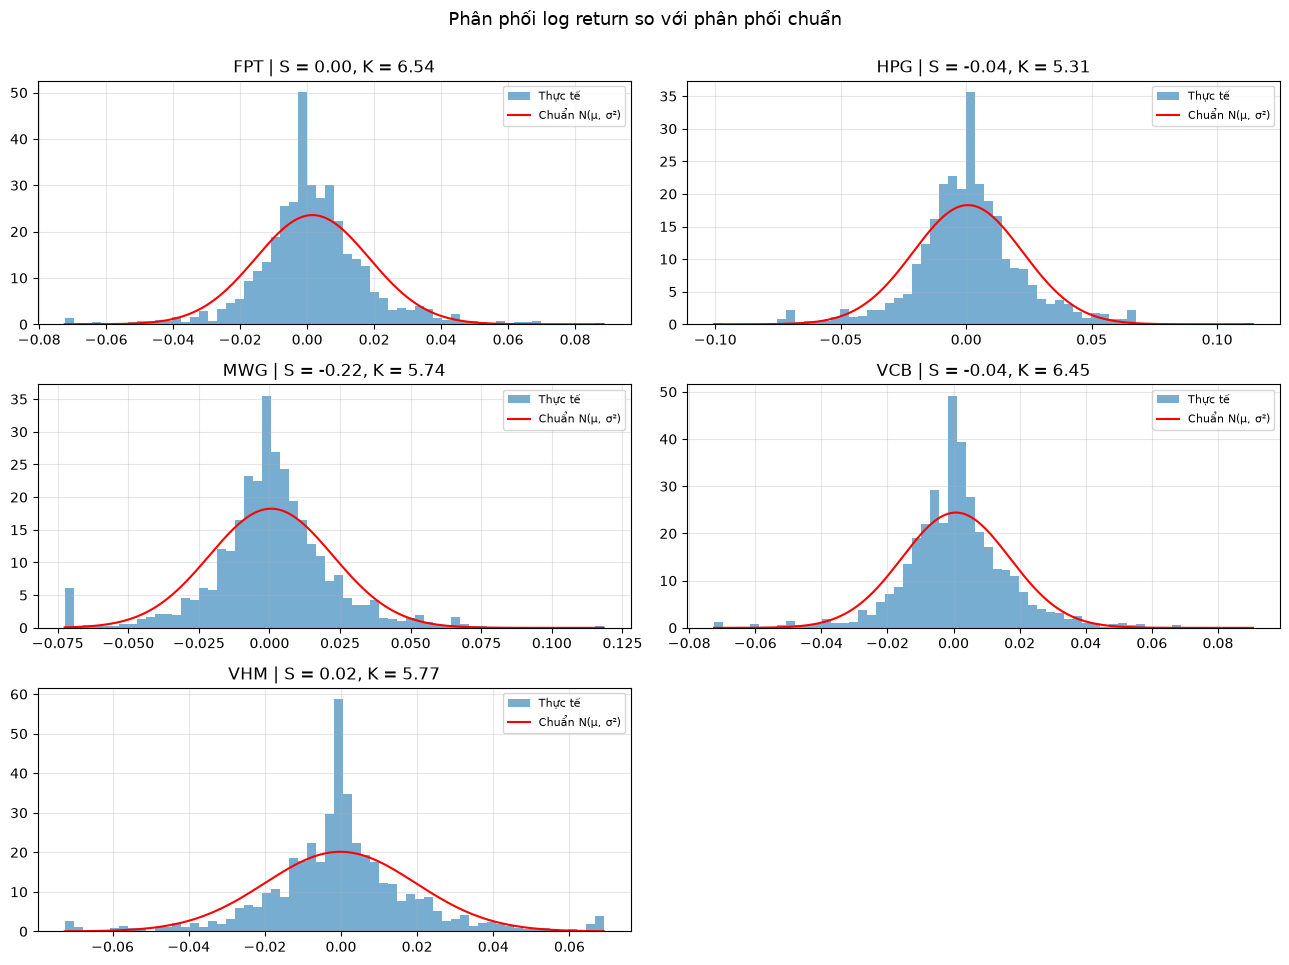

In [8]:
# ===================== 1.4a THỐNG KÊ MÔ TẢ =====================
def describe_returns(r: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for tk in r.columns:
        x = r[tk].dropna().values
        S = stats.skew(x, bias=True)
        K = stats.kurtosis(x, fisher=False, bias=True)        # kurtosis thường (chuẩn = 3)
        rows[tk] = {"N": len(x), "Mean": x.mean(), "Std": x.std(ddof=1), "Skewness": S, "Kurtosis": K,
                    "Excess Kurtosis": K - 3, "Min": x.min(), "Median": np.median(x), "Max": x.max(),
                    "Mean năm": x.mean() * TRADING_DAYS, "Std năm": x.std(ddof=1) * np.sqrt(TRADING_DAYS)}
    return pd.DataFrame(rows).T


desc = describe_returns(log_ret)
display(desc.astype(float).round(5))
for tk, row in desc.iterrows():
    print(f"{tk}: S = {row['Skewness']:+.3f} ({'lệch trái' if row['Skewness'] < 0 else 'lệch phải'}), "
          f"K = {row['Kurtosis']:.3f} ({'đuôi dày hơn chuẩn' if row['Kurtosis'] > 3 else 'đuôi mỏng'})")

# Histogram so với phân phối chuẩn cùng mean & std
fig, axes = grid_axes(N)
for ax, tk in zip(axes, tickers):
    x = log_ret[tk]
    ax.hist(x, bins=60, density=True, alpha=0.6, label="Thực tế")
    xs = np.linspace(x.min(), x.max(), 400)
    ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "r-", lw=1.5, label="Chuẩn N(μ, σ²)")
    ax.set_title(f"{tk} | S = {desc.loc[tk, 'Skewness']:.2f}, K = {desc.loc[tk, 'Kurtosis']:.2f}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Phân phối log return so với phân phối chuẩn", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_histogram.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4b Kiểm định phân phối chuẩn: Jarque-Bera & QQ-plot
**Tầng 1:** $JB = \dfrac{n}{6}\left(S^2 + \dfrac{(K-3)^2}{4}\right) \sim \chi^2(2)$ dưới $H_0$: lợi suất phân phối chuẩn (S = 0, K = 3).

**Tầng 2:** `jarque_bera(x)` tính đúng công thức trên, đối chiếu với `scipy.stats.jarque_bera`. QQ-plot: phân vị mẫu (đã chuẩn hoá) so với phân vị N(0,1).

**Tầng 3:** p < 0,05 ⇒ bác bỏ chuẩn. Trên QQ-plot, hai đầu điểm **cong ra ngoài** đường 45° (dưới đường ở bên trái, trên đường ở bên phải)
⇒ giá trị cực đoan nhiều hơn chuẩn dự báo = fat tails.

**Lưu ý – biên độ giá ±7% của HOSE:** lợi suất ngày bị chặn ở trần/sàn nên histogram có cột nhô lên ở ≈ ±0,07 và QQ-plot "đi ngang"
ở hai đầu (rõ ở HPG, MWG, VHM). Biên độ **cắt cụt đuôi**: rủi ro đuôi thật (khi trần/sàn bị dồn sang nhiều phiên liên tiếp) có thể còn
lớn hơn những gì Kurtosis đo được ⇒ càng củng cố kết luận đuôi dày.

,n,Skewness,Kurtosis,JB,p-value,JB (scipy),Giá trị tới hạn χ²(2),Kết luận
FPT,1452.0,0.004155,6.535062,756.052166,6.688954e-165,756.052166,5.991465,Bác bỏ H0 – KHÔNG chuẩn
HPG,1452.0,-0.041302,5.306578,322.291206,1.035986e-70,322.291206,5.991465,Bác bỏ H0 – KHÔNG chuẩn
MWG,1452.0,-0.219400,5.740783,466.118474,6.076582e-102,466.118474,5.991465,Bác bỏ H0 – KHÔNG chuẩn
VCB,1452.0,-0.038691,6.452015,721.304790,2.347767e-157,721.304790,5.991465,Bác bỏ H0 – KHÔNG chuẩn
VHM,1452.0,0.023448,5.768919,463.981282,1.769069e-101,463.981282,5.991465,Bác bỏ H0 – KHÔNG chuẩn


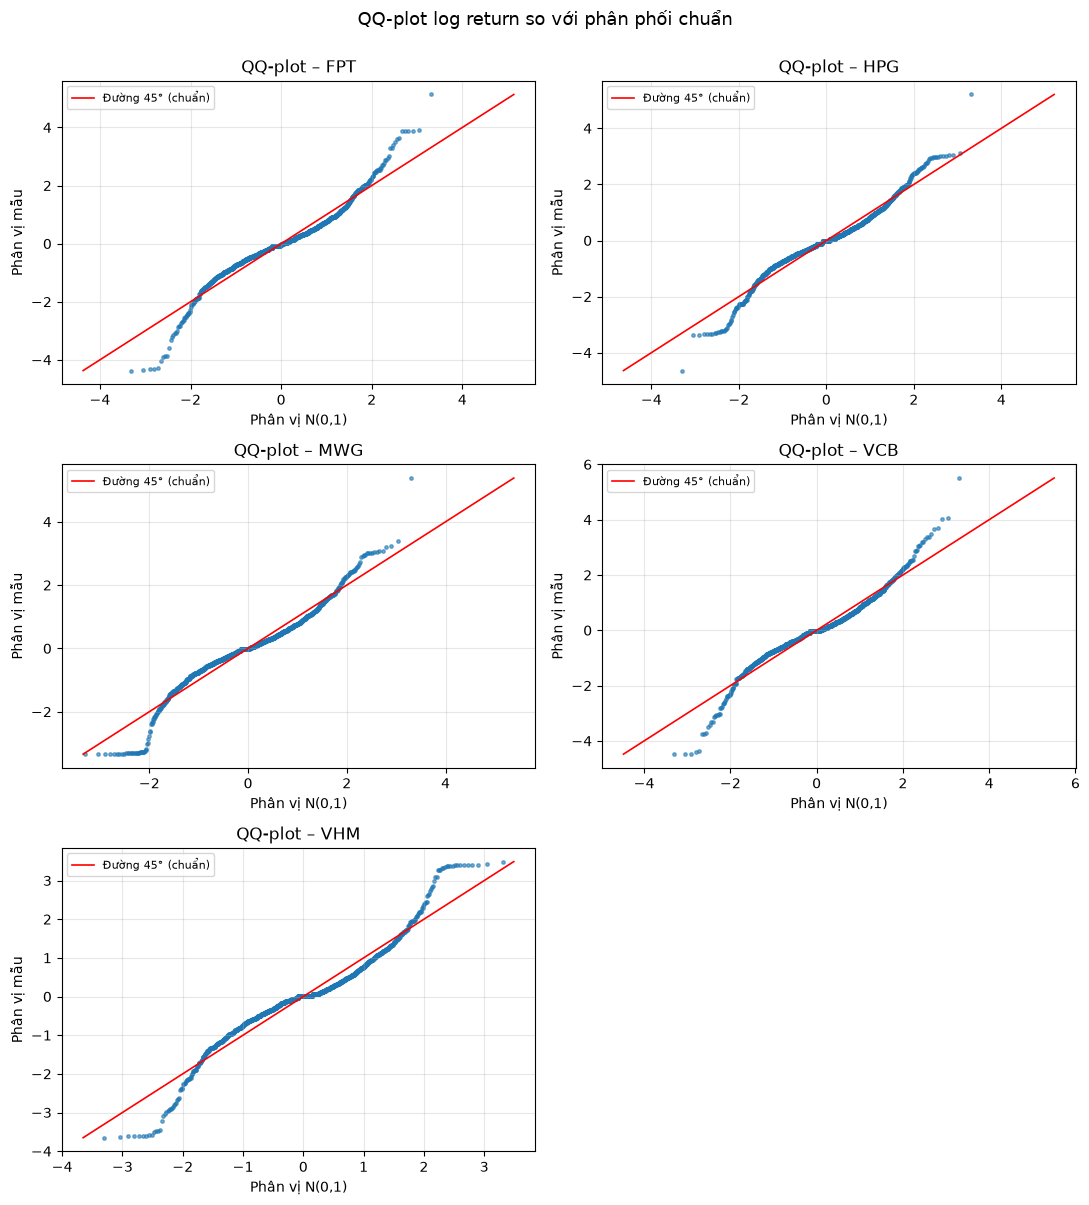

In [9]:
# ===================== 1.4b JARQUE-BERA + QQ-PLOT =====================
def jarque_bera(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    n = len(x)
    S = stats.skew(x, bias=True)
    K = stats.kurtosis(x, fisher=False, bias=True)
    jb = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
    return n, S, K, jb, stats.chi2.sf(jb, df=2)


crit_jb = stats.chi2.ppf(1 - ALPHA, df=2)
jb_table = pd.DataFrame({tk: dict(zip(["n", "Skewness", "Kurtosis", "JB", "p-value"], jarque_bera(log_ret[tk])))
                         for tk in tickers}).T
jb_table["JB (scipy)"] = [stats.jarque_bera(log_ret[tk]).statistic for tk in tickers]
jb_table["Giá trị tới hạn χ²(2)"] = crit_jb
jb_table["Kết luận"] = np.where(jb_table["p-value"].astype(float) < ALPHA, "Bác bỏ H0 – KHÔNG chuẩn", "Chưa bác bỏ – chuẩn")
display(jb_table)

fig, axes = grid_axes(N, h=4, w=11)
for ax, tk in zip(axes, tickers):
    z = (log_ret[tk] - log_ret[tk].mean()) / log_ret[tk].std()
    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.6)
    lim = [min(osm.min(), osr.min()), max(osm.max(), osr.max())]
    ax.plot(lim, lim, "r-", lw=1.2, label="Đường 45° (chuẩn)")
    ax.set_title(f"QQ-plot – {tk}"); ax.set_xlabel("Phân vị N(0,1)"); ax.set_ylabel("Phân vị mẫu")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("QQ-plot log return so với phân phối chuẩn", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_qqplot.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4c Kiểm định tính dừng: ADF & KPSS (cho cả chuỗi giá và chuỗi lợi suất)
**Tầng 1:**
- ADF: $\Delta y_t = c + \gamma y_{t-1} + \sum_{j=1}^{p}\phi_j \Delta y_{t-j} + u_t$; $H_0: \gamma = 0$ (có nghiệm đơn vị – **không dừng**).
- KPSS: $H_0$: chuỗi **dừng**. Dùng hai kiểm định có giả thuyết ngược nhau để kết luận chắc chắn hơn.

**Tầng 2:** `adf_test`, `kpss_test` dùng `statsmodels` (nếu có), nếu không dùng bản viết tay (ADF chọn trễ theo AIC; KPSS dùng
phương sai dài hạn Newey-West). KPSS: bảng tra chỉ có p trong [0,01; 0,10] nên p bị chặn ở biên ⇒ cột "KPSS p (ghi báo cáo)"
ghi đúng dạng "< 0.01" / "> 0.10" để chép vào báo cáo.

**Tầng 3:** Kết luận DỪNG khi ADF bác bỏ (p < 0,05) **và** KPSS không bác bỏ (p ≥ 0,05). Kỳ vọng: giá KHÔNG DỪNG, lợi suất DỪNG.

In [10]:
# ===================== 1.4c ADF & KPSS =====================
def _adf_manual(x, maxlag=None):
    """ADF có hằng số, chọn số trễ theo AIC. Trả về (stat, p=NaN, lag, giá trị tới hạn 5% xấp xỉ MacKinnon)."""
    x = np.asarray(x, float)
    dx = np.diff(x)
    maxlag = maxlag or int(np.ceil(12 * (len(x) / 100) ** 0.25))
    best = None
    for p in range(maxlag + 1):
        y = dx[maxlag:]
        X = [np.ones_like(y), x[maxlag:-1]] + [dx[maxlag - j:-j] for j in range(1, p + 1)]
        X = np.column_stack(X)
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        n = len(y)
        aic = n * np.log(resid @ resid / n) + 2 * X.shape[1]
        if best is None or aic < best[0]:
            s2 = resid @ resid / (n - X.shape[1])
            se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
            best = (aic, beta[1] / se, p)
    tau = best[1]
    p_approx = 0.01 if tau < -3.43 else 0.05 if tau < -2.86 else 0.10 if tau < -2.57 else 0.5
    return tau, p_approx, best[2], -2.86


def _kpss_manual(x):
    """KPSS (level) với phương sai dài hạn Bartlett, số trễ = int(12 (T/100)^{1/4})."""
    x = np.asarray(x, float)
    e = x - x.mean()
    n = len(e)
    L = int(12 * (n / 100) ** 0.25)
    s2 = e @ e / n
    for k in range(1, L + 1):
        s2 += 2 * (1 - k / (L + 1)) * (e[k:] @ e[:-k]) / n
    stat = (np.cumsum(e) ** 2).sum() / (n ** 2 * s2)
    p = float(np.interp(stat, [0.347, 0.463, 0.574, 0.739], [0.10, 0.05, 0.025, 0.01]))
    return stat, p, L, 0.463


def adf_test(x):
    x = pd.Series(x).dropna()
    if HAS_SM:
        stat, p, lag, _, cv, _ = adfuller(x, regression="c", autolag="AIC")
        return {"ADF stat": stat, "ADF p-value": p, "ADF lag": lag, "ADF CV 5%": cv["5%"]}
    stat, p, lag, cv = _adf_manual(x.values)
    return {"ADF stat": stat, "ADF p-value": p, "ADF lag": lag, "ADF CV 5%": cv}


def kpss_test(x):
    x = pd.Series(x).dropna()
    if HAS_SM:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InterpolationWarning)
            stat, p, lag, cv = kpss(x, regression="c", nlags="auto")
    else:
        stat, p, lag, cv = _kpss_manual(x.values)
        cv = {"5%": cv}
    # bảng tra KPSS chỉ có p trong [0,01; 0,10] -> p ở biên nghĩa là "< 0,01" hoặc "> 0,10"
    note = "< 0.01" if p <= 0.01 else ("> 0.10" if p >= 0.10 else f"{p:.3f}")
    return {"KPSS stat": stat, "KPSS p-value": p, "KPSS p (ghi báo cáo)": note, "KPSS lag": lag, "KPSS CV 5%": cv["5%"]}


def stationarity_verdict(p_adf, p_kpss):
    adf_rej, kpss_rej = p_adf < ALPHA, p_kpss < ALPHA
    if adf_rej and not kpss_rej:
        return "DỪNG"
    if not adf_rej and kpss_rej:
        return "KHÔNG DỪNG"
    return "Mâu thuẫn (cần xem thêm)"


rows = []
for name, df in {"Giá (Adj Close)": prices, "Log return": log_ret}.items():
    for tk in tickers:
        res = {"Chuỗi": name, "Mã": tk, **adf_test(df[tk]), **kpss_test(df[tk])}
        res["Kết luận"] = stationarity_verdict(res["ADF p-value"], res["KPSS p-value"])
        rows.append(res)
stationarity = pd.DataFrame(rows).set_index(["Chuỗi", "Mã"])
display(stationarity.round(4))

ADF stat  ADF p-value  ADF lag  ADF CV 5%  KPSS stat  KPSS p-value KPSS p (ghi báo cáo)  KPSS lag  KPSS CV 5%    Kết luận
Chuỗi           Mã                                                                                                                            
Giá (Adj Close) FPT    1.9995       0.9987        7    -2.8635     4.8450          0.01               < 0.01        25       0.463  KHÔNG DỪNG
                HPG   -1.5466       0.5103       13    -2.8636     2.5677          0.01               < 0.01        25       0.463  KHÔNG DỪNG
                MWG   -1.5781       0.4946        2    -2.8635     2.5351          0.01               < 0.01        25       0.463  KHÔNG DỪNG
                VCB   -1.6147       0.4755        3    -2.8635     5.0968          0.01               < 0.01        25       0.463  KHÔNG DỪNG
                VHM   -1.4462       0.5599        0    -2.8635     2.5501          0.01               < 0.01        25       0.463  KHÔNG DỪNG
Log return      FPT  -28.2546       0.0000        1    -2.8635     0.0680          0.10               > 0.10         9       0.463        DỪNG
                HPG  -36.4627       0.0000        0    -2.8635     0.1778          0.10               > 0.10         2       0.463        DỪNG
                MWG  -35.2940       0.0000        0    -2.8635     0.0941          0.10               > 0.10         0       0.463        DỪNG
                VCB  -10.5196       0.0000       15    -2.8636     0.0896          0.10               > 0.10         3       0.463        DỪNG
                VHM  -35.2996       0.0000        0    -2.8635     0.1238          0.10               > 0.10         8       0.463        DỪNG

## 1.4d Kiểm định tự tương quan: ACF & Ljung-Box trên $r_t$, $|r_t|$, $r_t^2$
**Tầng 1:** $Q(m) = T(T+2)\sum_{k=1}^{m}\dfrac{\hat\rho_k^2}{T-k} \sim \chi^2(m)$ dưới $H_0$: không có tự tương quan đến trễ m.
$r_t$ có tự tương quan ⇒ lợi suất dự báo được (vi phạm thị trường hiệu quả dạng yếu); $|r_t|$, $r_t^2$ có tự tương quan ⇒ **cụm biến động** (hiệu ứng ARCH).

**Tầng 2:** `acf()` và `ljung_box()` viết tay bằng numpy (kết quả trùng `statsmodels.acorr_ljungbox`). Biên tin cậy ACF: $\pm 1{,}96/\sqrt{T}$.

**Tầng 3:** Cột ACF vượt dải xanh = tự tương quan có ý nghĩa. Ô p-value < 0,05 = có tự tương quan.

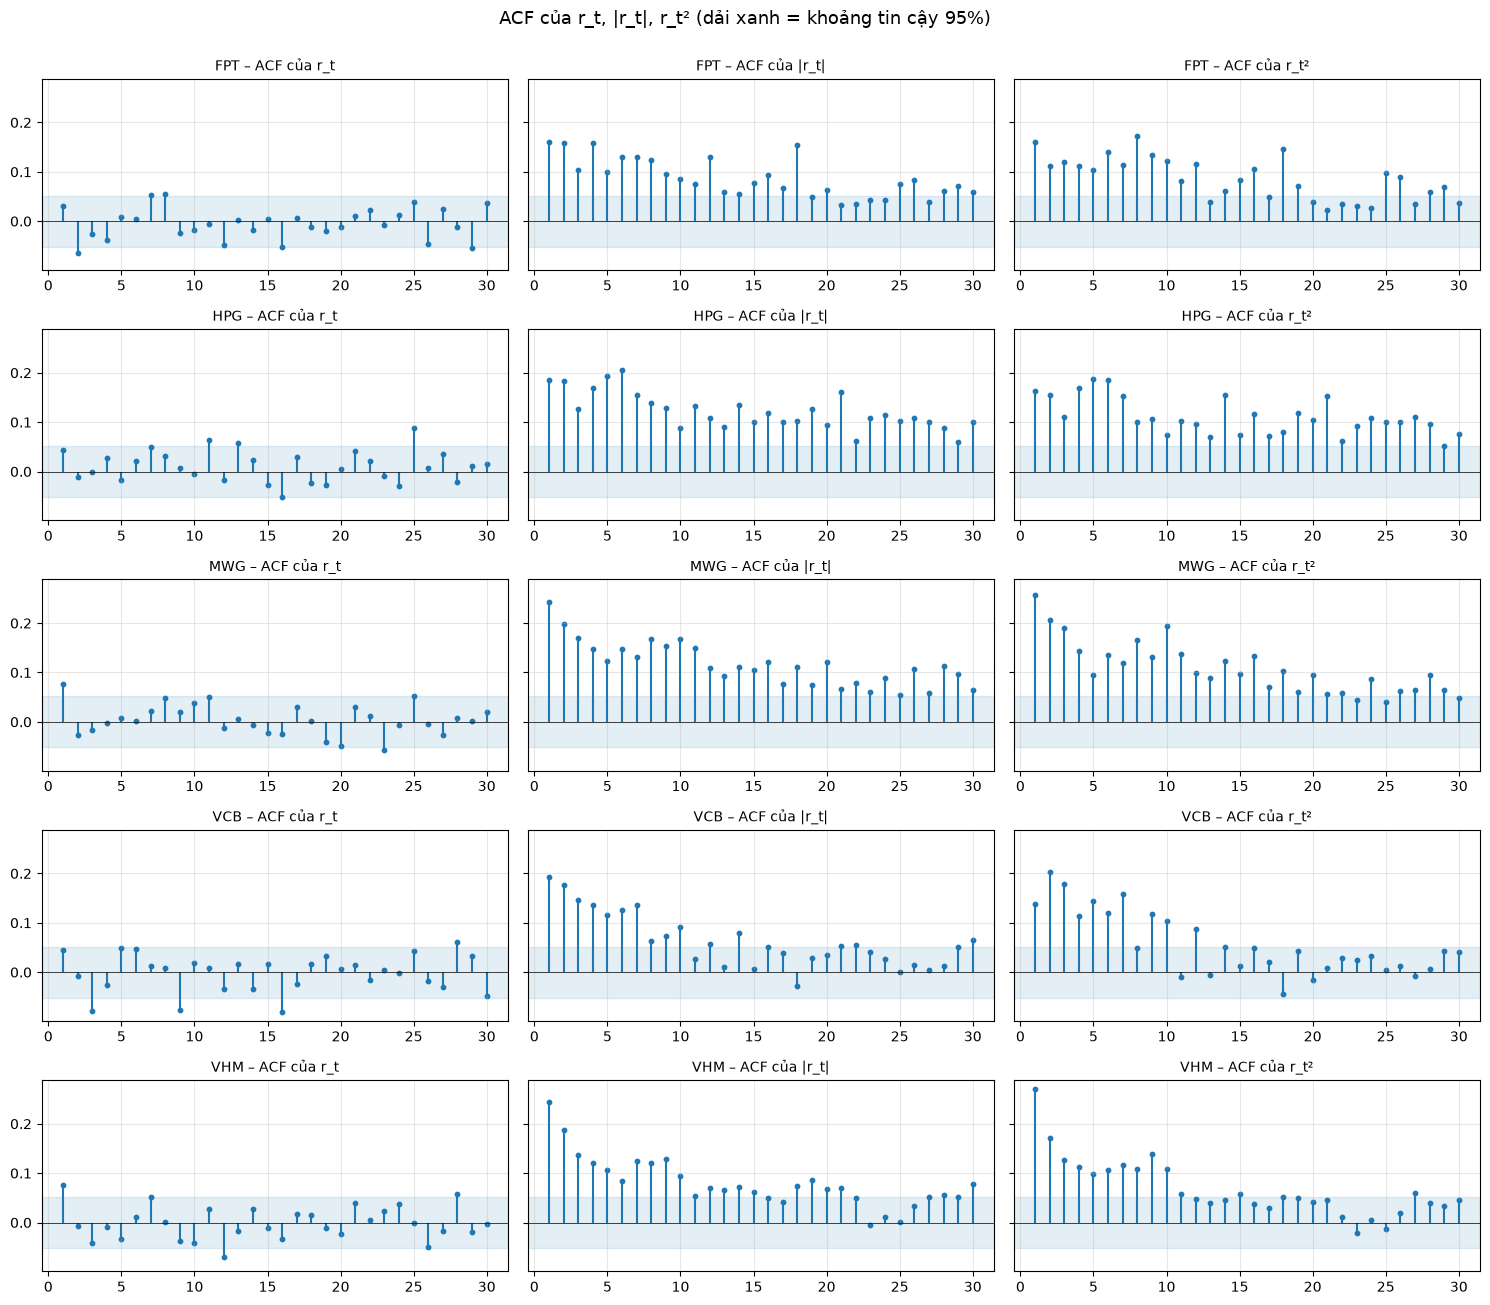

p (lag 5)  p (lag 10)  p (lag 20)
Mã  Chuỗi                                   
FPT r_t       0.0594      0.0248      0.0776
    |r_t|     0.0000      0.0000      0.0000
    r_t²      0.0000      0.0000      0.0000
HPG r_t       0.4673      0.4089      0.0588
    |r_t|     0.0000      0.0000      0.0000
    r_t²      0.0000      0.0000      0.0000
MWG r_t       0.0763      0.0766      0.0711
    |r_t|     0.0000      0.0000      0.0000
    r_t²      0.0000      0.0000      0.0000
VCB r_t       0.0062      0.0013      0.0008
    |r_t|     0.0000      0.0000      0.0000
    r_t²      0.0000      0.0000      0.0000
VHM r_t       0.0292      0.0220      0.0255
    |r_t|     0.0000      0.0000      0.0000
    r_t²      0.0000      0.0000      0.0000

In [11]:
# ===================== 1.4d ACF + LJUNG-BOX =====================
def acf(x, nlags):
    """Hệ số tự tương quan mẫu ρ_1..ρ_nlags."""
    x = np.asarray(x, float); x = x - x.mean()
    denom = x @ x
    return np.array([(x[k:] @ x[:-k]) / denom for k in range(1, nlags + 1)])


def ljung_box(x, lags):
    """Ljung-Box Q(m) và p-value cho từng m trong lags."""
    x = np.asarray(pd.Series(x).dropna(), float)
    n = len(x)
    rho = acf(x, max(lags))
    out = {}
    for m in lags:
        Q = n * (n + 2) * np.sum(rho[:m] ** 2 / (n - np.arange(1, m + 1)))
        out[m] = {"Q": Q, "p-value": stats.chi2.sf(Q, m)}
    return pd.DataFrame(out).T


ACF_LAGS = 30
transforms = {"r_t": lambda s: s, "|r_t|": lambda s: s.abs(), "r_t²": lambda s: s ** 2}
band = 1.96 / np.sqrt(T)
fig, axes = plt.subplots(N, 3, figsize=(15, 2.6 * N), squeeze=False, sharey=True)
for i, tk in enumerate(tickers):
    for j, (name, f) in enumerate(transforms.items()):
        ax = axes[i, j]
        rho = acf(f(log_ret[tk]), ACF_LAGS)
        ax.vlines(range(1, ACF_LAGS + 1), 0, rho, color="tab:blue")
        ax.scatter(range(1, ACF_LAGS + 1), rho, s=10, color="tab:blue")
        ax.axhspan(-band, band, color="tab:blue", alpha=0.12)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{tk} – ACF của {name}", fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("ACF của r_t, |r_t|, r_t² (dải xanh = khoảng tin cậy 95%)", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_acf.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for tk in tickers:
    for name, f in transforms.items():
        for m, r in ljung_box(f(log_ret[tk]), LB_LAGS).iterrows():
            rows.append({"Mã": tk, "Chuỗi": name, "Lag": int(m), "Q-stat": r["Q"], "p-value": r["p-value"],
                         "Kết luận": "Có tự tương quan" if r["p-value"] < ALPHA else "Không"})
ljungbox = pd.DataFrame(rows)
lb_pivot = ljungbox.pivot_table(index=["Mã", "Chuỗi"], columns="Lag", values="p-value", sort=False)
lb_pivot.columns = [f"p (lag {c})" for c in lb_pivot.columns]
display(lb_pivot.round(4))

## 1.5 Diễn giải cốt lõi: Fat Tails & Volatility Clustering ⇒ vì sao cần GARCH
**Tầng 1:**
- *Fat tails*: K > 3 và JB bác bỏ chuẩn ⇒ biến động cực đoan xảy ra thường xuyên hơn phân phối chuẩn dự báo ⇒ VaR giả định chuẩn
  với phương sai cố định sẽ **đánh giá thấp** rủi ro đuôi.
- *Volatility clustering*: $|r_t|$ và $r_t^2$ tự tương quan rất mạnh (p ≈ 0) ⇒ phương sai **thay đổi theo thời gian và phụ thuộc quá khứ**.
- Bản thân $r_t$ tự tương quan yếu hơn nhiều; nếu mã nào vẫn có p < 0,05 (ô tổng hợp dưới tự chỉ ra) thì thường do **giao dịch mỏng**
  (nhiều ngày lợi suất = 0 do điền giá) ⇒ có thể thêm AR(1) vào phương trình trung bình; điều này không thay đổi kết luận chính.
- Mô hình phương sai không đổi không giải thích được các hiện tượng trên ⇒ cần **GARCH** $\sigma_t^2 = \omega + \alpha\epsilon_{t-1}^2 + \beta\sigma_{t-1}^2$
  (TV2), kết hợp phân phối Student-t để bắt đuôi dày.

**Tầng 3:** ô dưới tự tổng hợp bằng chứng cho từng mã từ các bảng trên.

In [12]:
# ===================== 1.5 TỔNG HỢP STYLIZED FACTS =====================
max_lag = max(LB_LAGS)
lb_at = lambda name: ljungbox[(ljungbox["Chuỗi"] == name) & (ljungbox["Lag"] == max_lag)].set_index("Mã")["p-value"]
evidence = pd.DataFrame(index=tickers)
evidence["Kurtosis"] = desc["Kurtosis"].astype(float)
evidence["JB p-value"] = jb_table["p-value"].astype(float)
evidence["Fat tails?"] = np.where((evidence["Kurtosis"] > 3) & (evidence["JB p-value"] < ALPHA), "CÓ", "không")
evidence[f"LB p r_t (lag {max_lag})"] = lb_at("r_t")
evidence[f"LB p r_t² (lag {max_lag})"] = lb_at("r_t²")
evidence["Vol clustering?"] = np.where(lb_at("r_t²") < ALPHA, "CÓ", "không")
evidence["Tự tương quan r_t?"] = np.where(lb_at("r_t") < ALPHA, "CÓ (nhẹ)", "không")   # kết luận theo lag 20
sig_lags = ljungbox[(ljungbox["Chuỗi"] == "r_t") & (ljungbox["p-value"] < ALPHA)].groupby("Mã")["Lag"].apply(
    lambda s: ", ".join(map(str, s)))
evidence["LB r_t có ý nghĩa ở lag"] = sig_lags.reindex(tickers).fillna("không lag nào")
evidence["% ngày r_t = 0"] = (log_ret == 0).mean() * 100
evidence["Giá"] = stationarity.xs("Giá (Adj Close)", level="Chuỗi")["Kết luận"]
evidence["Lợi suất"] = stationarity.xs("Log return", level="Chuỗi")["Kết luận"]
display(evidence.round(4))

print(f"• Fat tails ở {(evidence['Fat tails?'] == 'CÓ').sum()}/{N} mã -> dùng phân phối Student-t (TV2) và VaR-t (TV4).")
print(f"• Volatility clustering ở {(evidence['Vol clustering?'] == 'CÓ').sum()}/{N} mã -> cần GARCH/GJR-GARCH (TV2).")
print("• Giá: " + ", ".join(f"{k}={v}" for k, v in evidence["Giá"].items()))
print("• Lợi suất: " + ", ".join(f"{k}={v}" for k, v in evidence["Lợi suất"].items())
      + " -> mọi mô hình phía sau ước lượng trên log return.")
ac_tk = evidence.index[evidence["Tự tương quan r_t?"] != "không"].tolist()
if ac_tk:
    print(f"• Lợi suất còn tự tương quan nhẹ ở {', '.join(ac_tk)} (tỷ lệ ngày r_t = 0: "
          + ", ".join(f"{t} = {evidence.loc[t, '% ngày r_t = 0']:.1f}%" for t in ac_tk)
          + ") -> nghi do giao dịch mỏng; kiểm tra lại Ljung-Box trên phần dư ε ở TV2.")
weak = [t for t in tickers if t not in ac_tk and evidence.loc[t, "LB r_t có ý nghĩa ở lag"] != "không lag nào"]
if weak:
    print("• Tự tương quan rất yếu (chỉ có ý nghĩa ở một vài lag, không có ý nghĩa ở lag 20): "
          + ", ".join(f"{t} (lag {evidence.loc[t, 'LB r_t có ý nghĩa ở lag']})" for t in weak)
          + " -> kết luận ở bảng tổng hợp dựa trên lag 20.")

with pd.ExcelWriter(OUT["TV1"] / "TV1_statistical_tests.xlsx", engine="openpyxl") as xw:
    evidence.to_excel(xw, sheet_name="Tong_hop")
    desc.to_excel(xw, sheet_name="Thong_ke_mo_ta")
    jb_table.to_excel(xw, sheet_name="Jarque_Bera")
    stationarity.to_excel(xw, sheet_name="ADF_KPSS")
    ljungbox.to_excel(xw, sheet_name="Ljung_Box", index=False)
print("✔ Đã lưu", OUT["TV1"] / "TV1_statistical_tests.xlsx")

,Kurtosis,JB p-value,Fat tails?,LB p r_t (lag 20),LB p r_t² (lag 20),Vol clustering?,Tự tương quan r_t?,LB r_t có ý nghĩa ở lag,% ngày r_t = 0,Giá,Lợi suất
FPT,6.5351,0.0,CÓ,0.0776,0.0,CÓ,không,10,6.6116,KHÔNG DỪNG,DỪNG
HPG,5.3066,0.0,CÓ,0.0588,0.0,CÓ,không,không lag nào,5.9917,KHÔNG DỪNG,DỪNG
MWG,5.7408,0.0,CÓ,0.0711,0.0,CÓ,không,không lag nào,6.9559,KHÔNG DỪNG,DỪNG
VCB,6.4520,0.0,CÓ,0.0008,0.0,CÓ,CÓ (nhẹ),"5, 10, 20",9.2975,KHÔNG DỪNG,DỪNG
VHM,5.7689,0.0,CÓ,0.0255,0.0,CÓ,CÓ (nhẹ),"5, 10, 20",9.4353,KHÔNG DỪNG,DỪNG


• Fat tails ở 5/5 mã -> dùng phân phối Student-t (TV2) và VaR-t (TV4).
• Volatility clustering ở 5/5 mã -> cần GARCH/GJR-GARCH (TV2).
• Giá: FPT=KHÔNG DỪNG, HPG=KHÔNG DỪNG, MWG=KHÔNG DỪNG, VCB=KHÔNG DỪNG, VHM=KHÔNG DỪNG
• Lợi suất: FPT=DỪNG, HPG=DỪNG, MWG=DỪNG, VCB=DỪNG, VHM=DỪNG -> mọi mô hình phía sau ước lượng trên log return.
• Lợi suất còn tự tương quan nhẹ ở VCB, VHM (tỷ lệ ngày r_t = 0: VCB = 9.3%, VHM = 9.4%) -> nghi do giao dịch mỏng; kiểm tra lại Ljung-Box trên phần dư ε ở TV2.
• Tự tương quan rất yếu (chỉ có ý nghĩa ở một vài lag, không có ý nghĩa ở lag 20): FPT (lag 10) -> kết luận ở bảng tổng hợp dựa trên lag 20.
✔ Đã lưu D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput\TV1_Data_EDA\TV1_statistical_tests.xlsx


### TV1 – Gợi ý trả lời vấn đáp
**Câu 1 – Vì sao log return dừng còn giá thì không?** Giá xấp xỉ bước ngẫu nhiên $\ln P_t = \ln P_{t-1} + r_t$ (có nghiệm đơn vị):
mọi cú sốc tích luỹ vĩnh viễn nên trung bình và phương sai của giá thay đổi theo thời gian. Log return chính là sai phân bậc 1 của
$\ln P_t$, loại bỏ nghiệm đơn vị nên dao động quanh một mức trung bình ổn định ⇒ dừng (ADF bác bỏ, KPSS không bác bỏ).

**Câu 2 – Kurtosis > 3 và JB p < 0,05 nghĩa là gì cho việc chọn mô hình rủi ro?** Lợi suất không chuẩn và đuôi dày ⇒ VaR/ES giả định
chuẩn đánh giá thấp tổn thất cực đoan (nhất là ở 99%). Cần: (i) mô hình phương sai có điều kiện (GARCH) vì một phần đuôi dày do phương sai
thay đổi; (ii) phân phối đuôi dày (Student-t); (iii) bổ sung ES và Historical Simulation, rồi backtest (TV4) để kiểm chứng.

---
# THÀNH VIÊN 2: MÔ HÌNH HOÁ BIẾN ĐỘNG BIÊN (UNIVARIATE GARCH MARGINS)
## 2.1 Ước lượng GARCH(1,1) & GJR-GARCH(1,1) với phân phối Normal và Student-t
**Tầng 1 – Công thức & ý nghĩa:**
- Phương trình trung bình: $r_t = \mu + \epsilon_t$, $\epsilon_t = \sigma_t z_t$.
- GARCH(1,1): $\sigma_t^2 = \omega + \alpha\epsilon_{t-1}^2 + \beta\sigma_{t-1}^2$.
- GJR-GARCH(1,1): $\sigma_t^2 = \omega + \alpha\epsilon_{t-1}^2 + \gamma I_{t-1}\epsilon_{t-1}^2 + \beta\sigma_{t-1}^2$, $I_{t-1} = 1$ nếu $\epsilon_{t-1} < 0$.
- $\alpha$: phản ứng với tin tức mới; $\beta$: "trí nhớ" của biến động; persistence $= \alpha + \gamma/2 + \beta$ (GARCH: $\alpha+\beta$);
  half-life $= \ln 0{,}5/\ln(\text{persistence})$ phiên; phương sai dài hạn $\bar\sigma^2 = \omega/(1-\text{persistence})$.
- $\gamma > 0$: **hiệu ứng đòn bẩy** – tin xấu làm biến động tăng nhiều hơn tin tốt cùng độ lớn.
- $z_t \sim N(0,1)$ hoặc Student-t chuẩn hoá (phương sai 1, bậc tự do ν > 2) – t bắt đuôi dày mà TV1 đã chứng minh.
- Log-likelihood mỗi quan sát: Normal $\ell_t = -\tfrac12[\ln 2\pi + \ln\sigma_t^2 + \epsilon_t^2/\sigma_t^2]$;
  Student-t $\ell_t = \ln\Gamma(\tfrac{\nu+1}{2}) - \ln\Gamma(\tfrac{\nu}{2}) - \tfrac12\ln[\pi(\nu-2)] - \tfrac12\ln\sigma_t^2 - \tfrac{\nu+1}{2}\ln\left(1+\tfrac{\epsilon_t^2}{\sigma_t^2(\nu-2)}\right)$.

**Tầng 2:** `garch_variance()` lọc $\sigma_t^2$ (dùng `scipy.signal.lfilter`), `fit_garch()` tối đa hoá log-likelihood bằng
`scipy.optimize.minimize` (SLSQP, ràng buộc ω > 0, α ≥ 0, α + γ ≥ 0, β ≥ 0, persistence < 1, ν > 2). Sai số chuẩn robust
(Bollerslev–Wooldridge, sandwich). Ước lượng trên lợi suất % (r × 100); σ được đổi lại về thập phân khi lưu.

**Tầng 3:** p-value của γ < 0,05 ⇒ có đòn bẩy; ν nhỏ (3–6) ⇒ phần dư vẫn đuôi dày; persistence gần 1 ⇒ cú sốc biến động tắt rất chậm.

In [13]:
# ===================== 2.1 HÀM GARCH / GJR-GARCH VIẾT TAY =====================
def unpack(params, gjr, dist):
    """Tách vector tham số [mu, omega, alpha, (gamma), beta, (nu)]."""
    mu, omega, alpha = params[0], params[1], params[2]
    gamma = params[3] if gjr else 0.0
    beta = params[4] if gjr else params[3]
    nu = params[-1] if dist == "t" else np.inf
    return mu, omega, alpha, gamma, beta, nu


def garch_variance(params, r, gjr, dist):
    """σ²_t = ω + (α + γ·I_{t-1}) ε²_{t-1} + β σ²_{t-1}; khởi tạo σ²_0 = phương sai mẫu (backcast)."""
    mu, omega, alpha, gamma, beta, _ = unpack(params, gjr, dist)
    eps = r - mu
    backcast = np.mean(eps ** 2)
    x = np.empty_like(eps)
    x[0] = omega + (alpha + 0.5 * gamma + beta) * backcast
    x[1:] = omega + (alpha + gamma * (eps[:-1] < 0)) * eps[:-1] ** 2
    sigma2 = lfilter([1.0], [1.0, -beta], x)               # σ²_t = x_t + β σ²_{t-1}
    return np.maximum(sigma2, 1e-12), eps


def loglik_t(params, r, gjr, dist):
    """Log-likelihood của từng quan sát (vector độ dài T)."""
    sigma2, eps = garch_variance(params, r, gjr, dist)
    if dist == "normal":
        return -0.5 * (np.log(2 * np.pi) + np.log(sigma2) + eps ** 2 / sigma2)
    nu = params[-1]
    return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
            - 0.5 * np.log(sigma2) - (nu + 1) / 2 * np.log1p(eps ** 2 / (sigma2 * (nu - 2))))


def robust_se(ll_fun, x, h=1e-4):
    """Sai số chuẩn sandwich A⁻¹BA⁻¹ (A: Hessian số, B: tích ngoài của score) – Bollerslev & Wooldridge (1992)."""
    x = np.asarray(x, float)
    k = len(x)
    step = h * np.maximum(np.abs(x), 1e-2)
    scores = np.empty((len(ll_fun(x)), k))
    for i in range(k):
        e = np.zeros(k); e[i] = step[i]
        scores[:, i] = (ll_fun(x + e) - ll_fun(x - e)) / (2 * step[i])
    L = lambda p: ll_fun(p).sum()
    Hs = np.empty((k, k))
    for i in range(k):
        for j in range(i, k):
            ei = np.zeros(k); ei[i] = step[i]
            ej = np.zeros(k); ej[j] = step[j]
            Hs[i, j] = Hs[j, i] = (L(x + ei + ej) - L(x + ei - ej) - L(x - ei + ej) + L(x - ei - ej)) / (4 * step[i] * step[j])
    try:
        A_inv = np.linalg.inv(-Hs)
        return np.sqrt(np.clip(np.diag(A_inv @ (scores.T @ scores) @ A_inv), 0, None))
    except np.linalg.LinAlgError:
        return np.full(k, np.nan)


def fit_garch(r, gjr=False, dist="normal"):
    """Ước lượng MLE; thử nhiều điểm xuất phát, giữ nghiệm có log-likelihood lớn nhất."""
    v = r.var()
    names = ["mu", "omega", "alpha"] + (["gamma"] if gjr else []) + ["beta"] + (["nu"] if dist == "t" else [])
    bounds = [(-5 * abs(r.mean()) - 1, 5 * abs(r.mean()) + 1), (1e-6, 10 * v), (0.0, 1.0)] \
        + ([(-0.5, 1.0)] if gjr else []) + [(0.0, 1.0)] + ([(2.05, 100.0)] if dist == "t" else [])
    ia, ib = 2, (4 if gjr else 3)
    cons = [{"type": "ineq", "fun": lambda p: 0.9999 - (p[ia] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})          # α + γ ≥ 0
    nll = lambda p: -loglik_t(p, r, gjr, dist).sum()
    best = None
    for a0, b0 in [(0.05, 0.90), (0.10, 0.85), (0.15, 0.75)]:
        x0 = [r.mean(), v * (1 - a0 - b0), a0] + ([0.05] if gjr else []) + [b0] + ([6.0] if dist == "t" else [])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = minimize(nll, x0, method="SLSQP", bounds=bounds, constraints=cons,
                           options={"maxiter": 2000, "ftol": 1e-10})
        if best is None or res.fun < best.fun:
            best = res
    x = best.x
    se = robust_se(lambda p: loglik_t(p, r, gjr, dist), x)
    se = np.where(se > 0, se, np.nan)
    p_val = 2 * stats.norm.sf(np.abs(x / se))
    sigma2, eps = garch_variance(x, r, gjr, dist)
    mu, omega, alpha, gamma, beta, nu = unpack(x, gjr, dist)
    pers = alpha + 0.5 * gamma + beta
    igarch = pers > 0.999                                         # chạm biên => IGARCH, σ dài hạn không tồn tại
    LL, k, n = -best.fun, len(x), len(r)
    sig2_next = omega + (alpha + gamma * (eps[-1] < 0)) * eps[-1] ** 2 + beta * sigma2[-1]
    return {"gjr": gjr, "dist": dist, "params": dict(zip(names, x)), "se": dict(zip(names, se)),
            "pvalue": dict(zip(names, p_val)), "LL": LL, "k": k, "AIC": -2 * LL + 2 * k, "BIC": -2 * LL + k * np.log(n),
            "persistence": pers, "IGARCH": igarch,
            "half_life": np.nan if igarch else np.log(0.5) / np.log(pers),
            "uncond_vol_ann": np.nan if igarch else np.sqrt(omega / (1 - pers) * TRADING_DAYS) / SCALE,
            "sigma": np.sqrt(sigma2) / SCALE, "std_resid": eps / np.sqrt(sigma2),
            "sigma_fcst": np.sqrt(sig2_next) / SCALE, "converged": bool(best.success)}

In [14]:
# ===================== 2.1b ƯỚC LƯỢNG 4 MÔ HÌNH CHO MỖI MÃ =====================
SPECS = {"GARCH-N": dict(gjr=False, dist="normal"), "GARCH-t": dict(gjr=False, dist="t"),
         "GJR-GARCH-N": dict(gjr=True, dist="normal"), "GJR-GARCH-t": dict(gjr=True, dist="t")}
fits, param_rows = {}, []
for tk in tickers:
    r = log_ret[tk].values * SCALE
    for name, spec in SPECS.items():
        f = fit_garch(r, **spec)
        fits[(tk, name)] = f
        for pn, v in f["params"].items():
            param_rows.append({"Mã": tk, "Mô hình": name, "Tham số": pn, "Ước lượng": v,
                               "Std.Err (robust)": f["se"][pn], "p-value": f["pvalue"][pn]})
    print(f"✔ {tk}: đã ước lượng {len(SPECS)} mô hình")
all_params = pd.DataFrame(param_rows)
wide = all_params.pivot_table(index=["Mã", "Mô hình"], columns="Tham số", values="Ước lượng", sort=False)
display(wide[[c for c in ["mu", "omega", "alpha", "gamma", "beta", "nu"] if c in wide]].round(4))

✔ FPT: đã ước lượng 4 mô hình
✔ HPG: đã ước lượng 4 mô hình
✔ MWG: đã ước lượng 4 mô hình
✔ VCB: đã ước lượng 4 mô hình
✔ VHM: đã ước lượng 4 mô hình


Tham số              mu   omega   alpha   gamma    beta      nu
Mã  Mô hình                                                    
FPT GARCH-N      0.1595  0.0932  0.0758     NaN  0.8911     NaN
    GARCH-t      0.1201  0.1324  0.1196     NaN  0.8563  3.5427
    GJR-GARCH-N  0.1378  0.1037  0.0455  0.0574  0.8894     NaN
    GJR-GARCH-t  0.1018  0.1617  0.0695  0.1179  0.8426  3.5751
HPG GARCH-N      0.0794  0.0960  0.0706     NaN  0.9092     NaN
    GARCH-t      0.0445  0.1342  0.1138     NaN  0.8713  4.2140
    GJR-GARCH-N  0.0514  0.0962  0.0411  0.0502  0.9138     NaN
    GJR-GARCH-t  0.0213  0.1446  0.0647  0.0960  0.8722  4.2603
MWG GARCH-N      0.0969  0.1382  0.0844     NaN  0.8870     NaN
    GARCH-t      0.0822  0.1896  0.1212     NaN  0.8580  3.7366
    GJR-GARCH-N  0.0835  0.1506  0.0664  0.0282  0.8870     NaN
    GJR-GARCH-t  0.0585  0.2583  0.0641  0.1168  0.8444  3.6552
VCB GARCH-N      0.0773  0.4984  0.1688     NaN  0.6432     NaN
    GARCH-t      0.0189  0.3544  0.2460     NaN  0.6800  3.6072
    GJR-GARCH-N  0.0661  0.4886  0.1348  0.0525  0.6540     NaN
    GJR-GARCH-t  0.0116  0.3803  0.2118  0.0873  0.6663  3.6106
VHM GARCH-N     -0.0297  0.3066  0.1716     NaN  0.7598     NaN
    GARCH-t     -0.0619  0.2272  0.1784     NaN  0.8215  3.0373
    GJR-GARCH-N -0.0377  0.3137  0.1563  0.0299  0.7581     NaN
    GJR-GARCH-t -0.0624  0.2278  0.1762  0.0052  0.8211  3.0388

## 2.2 Lựa chọn mô hình tối ưu (AIC, BIC, Log-Likelihood)
**Tầng 1:** $AIC = -2\ln L + 2k$, $BIC = -2\ln L + k\ln n$ – càng nhỏ càng tốt; BIC phạt số tham số mạnh hơn nên ưa mô hình gọn.
Kiểm định LR GARCH vs GJR (cùng phân phối): $LR = 2(LL_{GJR} - LL_{GARCH}) \sim \chi^2(1)$.

**Tầng 3:** Student-t có AIC/BIC thấp hơn hẳn Normal ⇒ phần dư vẫn đuôi dày sau khi đã mô hình hoá biến động.
GJR tốt hơn và LR có p < 0,05 ⇒ có hiệu ứng đòn bẩy. Mô hình có persistence ≥ 0,999 được đánh dấu **IGARCH** (cú sốc không tắt,
σ dài hạn không xác định) – vẫn dùng được để lọc σ_t nhưng không diễn giải σ dài hạn.

In [15]:
# ===================== 2.2 SO SÁNH & CHỌN MÔ HÌNH =====================
comparison = pd.DataFrame([{
    "Mã": tk, "Mô hình": name, "LogLik": f["LL"], "k": f["k"], "AIC": f["AIC"], "BIC": f["BIC"],
    "Persistence": f["persistence"], "IGARCH?": "CÓ" if f["IGARCH"] else "",
    "Half-life (phiên)": f["half_life"], "σ dài hạn năm": f["uncond_vol_ann"],
    "gamma": f["params"].get("gamma", np.nan), "p(gamma)": f["pvalue"].get("gamma", np.nan),
    "nu": f["params"].get("nu", np.nan), "Hội tụ": f["converged"]} for (tk, name), f in fits.items()])
comparison["Hạng AIC"] = comparison.groupby("Mã")["AIC"].rank().astype(int)
comparison["Hạng BIC"] = comparison.groupby("Mã")["BIC"].rank().astype(int)
display(comparison.set_index(["Mã", "Mô hình"]).round(4))

lr_table = pd.DataFrame([{
    "Mã": tk, "Phân phối": d,
    "LR (GJR vs GARCH)": max(2 * (fits[(tk, f"GJR-GARCH-{d}")]["LL"] - fits[(tk, f"GARCH-{d}")]["LL"]), 0)}
    for tk in tickers for d in ["N", "t"]])
lr_table["p-value"] = stats.chi2.sf(lr_table["LR (GJR vs GARCH)"], 1)
lr_table["Kết luận"] = np.where(lr_table["p-value"] < ALPHA, "Có đòn bẩy (GJR tốt hơn)", "Không khác biệt")
display(lr_table.round(4))

best_name = comparison.sort_values(SELECT_BY).groupby("Mã", sort=False).head(1).set_index("Mã")["Mô hình"].loc[tickers]
selected = {tk: fits[(tk, best_name[tk])] for tk in tickers}
print(f"\nMô hình được chọn theo {SELECT_BY}:")
for tk in tickers:
    f = selected[tk]
    extra = ("IGARCH – σ dài hạn không xác định" if f["IGARCH"]
             else f"half-life = {f['half_life']:.1f} phiên | σ dài hạn năm = {f['uncond_vol_ann']:.2%}")
    print(f"  {tk}: {best_name[tk]:<12} | persistence = {f['persistence']:.4f} | {extra}")

LogLik  k        AIC        BIC  Persistence IGARCH?  Half-life (phiên)  σ dài hạn năm   gamma  p(gamma)      nu  Hội tụ  Hạng AIC  \
Mã  Mô hình                                                                                                                                              
FPT GARCH-N     -2713.5300  4  5435.0600  5456.1828       0.9670                    20.6441         0.2667     NaN       NaN     NaN    True         4   
    GARCH-t     -2630.1863  5  5270.3725  5296.7760       0.9760                    28.4988         0.3727     NaN       NaN  3.5427    True         2   
    GJR-GARCH-N -2708.8723  5  5427.7445  5454.1480       0.9636                    18.6830         0.2679  0.0574    0.0499     NaN    True         3   
    GJR-GARCH-t -2625.8574  6  5263.7148  5295.3990       0.9711                    23.6299         0.3755  0.1179    0.0229  3.5751    True         1   
HPG GARCH-N     -3076.3401  4  6160.6802  6181.8030       0.9798                    33.9278         0.3459     NaN       NaN     NaN    True         4   
    GARCH-t     -3016.3702  5  6042.7404  6069.1439       0.9852                    46.3498         0.4773     NaN       NaN  4.2140    True         2   
    GJR-GARCH-N -3070.7585  5  6151.5170  6177.9205       0.9800                    34.3309         0.3483  0.0502    0.0231     NaN    True         3   
    GJR-GARCH-t -3011.1412  6  6034.2824  6065.9666       0.9849                    45.5684         0.4913  0.0960    0.0056  4.2603    True         1   
MWG GARCH-N     -3069.3155  4  6146.6309  6167.7537       0.9714                    23.8779         0.3489     NaN       NaN     NaN    True         4   
    GARCH-t     -2996.5751  5  6003.1502  6029.5537       0.9792                    32.9753         0.4793     NaN       NaN  3.7366    True         2   
    GJR-GARCH-N -3068.1604  5  6146.3208  6172.7242       0.9675                    20.9979         0.3419  0.0282    0.3450     NaN    True         3   
    GJR-GARCH-t -2991.5176  6  5995.0351  6026.7193       0.9669                    20.5680         0.4432  0.1168    0.0209  3.6552    True         1   
VCB GARCH-N     -2686.3908  4  5380.7816  5401.9043       0.8120                     3.3288         0.2585     NaN       NaN     NaN    True         3   
    GARCH-t     -2590.3154  5  5190.6309  5217.0344       0.9260                     9.0125         0.3473     NaN       NaN  3.6072    True         1   
    GJR-GARCH-N -2685.6321  5  5381.2643  5407.6678       0.8149                     3.3872         0.2579  0.0525    0.3367     NaN    True         4   
    GJR-GARCH-t -2589.6093  6  5191.2186  5222.9028       0.9217                     8.5035         0.3499  0.0873    0.3119  3.6106    True         2   
VHM GARCH-N     -2938.1043  4  5884.2087  5905.3315       0.9314                     9.7527         0.3356     NaN       NaN     NaN    True         3   
    GARCH-t     -2845.1407  5  5700.2813  5726.6848       0.9999      CÓ                NaN            NaN     NaN       NaN  3.0373    True         1   
    GJR-GARCH-N -2937.7423  5  5885.4845  5911.8880       0.9294                     9.4637         0.3346  0.0299    0.5324     NaN    True         4   
    GJR-GARCH-t -2845.1356  6  5702.2712  5733.9554       0.9999      CÓ                NaN            NaN  0.0052    0.9264  3.0388    True         2   

                 Hạng BIC  
Mã  Mô hình                
FPT GARCH-N             4  
    GARCH-t             2  
    GJR-GARCH-N         3  
    GJR-GARCH-t         1  
HPG GARCH-N             4  
    GARCH-t             2  
    GJR-GARCH-N         3  
    GJR-GARCH-t         1  
MWG GARCH-N             3  
    GARCH-t             2  
    GJR-GARCH-N         4  
    GJR-GARCH-t         1  
VCB GARCH-N             3  
    GARCH-t             1  
    GJR-GARCH-N         4  
    GJR-GARCH-t         2  
VHM GARCH-N             3  
    GARCH-t             1  
    GJR-GARCH-N         4  
    GJR-GARCH-t         2

,Mã,Phân phối,LR (GJR vs GARCH),p-value,Kết luận
0,FPT,N,9.3155,0.0023,Có đòn bẩy (GJR tốt hơn)
1,FPT,t,8.6577,0.0033,Có đòn bẩy (GJR tốt hơn)
2,HPG,N,11.1632,0.0008,Có đòn bẩy (GJR tốt hơn)
3,HPG,t,10.4579,0.0012,Có đòn bẩy (GJR tốt hơn)
4,MWG,N,2.3101,0.1285,Không khác biệt
5,MWG,t,10.1151,0.0015,Có đòn bẩy (GJR tốt hơn)
6,VCB,N,1.5173,0.2180,Không khác biệt
7,VCB,t,1.4123,0.2347,Không khác biệt
8,VHM,N,0.7242,0.3948,Không khác biệt
9,VHM,t,0.0101,0.9198,Không khác biệt



Mô hình được chọn theo BIC:
  FPT: GJR-GARCH-t  | persistence = 0.9711 | half-life = 23.6 phiên | σ dài hạn năm = 37.55%
  HPG: GJR-GARCH-t  | persistence = 0.9849 | half-life = 45.6 phiên | σ dài hạn năm = 49.13%
  MWG: GJR-GARCH-t  | persistence = 0.9669 | half-life = 20.6 phiên | σ dài hạn năm = 44.32%
  VCB: GARCH-t      | persistence = 0.9260 | half-life = 9.0 phiên | σ dài hạn năm = 34.73%
  VHM: GARCH-t      | persistence = 0.9999 | IGARCH – σ dài hạn không xác định


## 2.3 Trích xuất phần dư chuẩn hoá ε và độ lệch chuẩn có điều kiện σ
**Tầng 1:** $\epsilon_{i,t} = \dfrac{r_{i,t} - \mu_i}{\sigma_{i,t}}$. Nếu mô hình đúng: ε có trung bình ≈ 0, phương sai ≈ 1, không còn cụm biến động.
$\sigma_{i,t}$ chỉ dùng thông tin đến $t-1$ ⇒ chính là **dự báo biến động 1 ngày** cho ngày t (dùng cho VaR ở TV4).

**Tầng 2:** Output dùng chung: `std_resid` (T × N), `cond_vol` (T × N, thập phân/ngày), `mu_vec` (N), `sigma_fcst` (σ phiên T+1).

**Tầng 3:** Biểu đồ: σ_t (đỏ) bám theo |r_t| (xám) và vọt lên trong các giai đoạn khủng hoảng; so sánh với EWMA (RiskMetrics λ = 0,94).

Phần dư chuẩn hoá (kỳ vọng mean ≈ 0, std ≈ 1):


,mean,std,skew,kurt
FPT,0.0297,0.9455,0.1585,2.9211
HPG,0.0199,0.9742,-0.0599,2.4582
MWG,0.0113,0.9503,0.1863,3.0524
VCB,0.0367,0.9614,0.6872,5.9769
VHM,0.0189,0.8922,0.1148,2.6994


Lưu ý: std(ε) < 0,95 ở FPT, VHM -> σ_t hơi cao hơn biến động thực hiện (thường gặp khi persistence sát 1 / IGARCH hoặc phân phối t với ν nhỏ) -> VaR từ các mã này có xu hướng thận trọng.
σ dự báo phiên T+1 (%/ngày): {'FPT': 1.202, 'HPG': 1.451, 'MWG': 1.563, 'VCB': 1.08, 'VHM': 1.347}


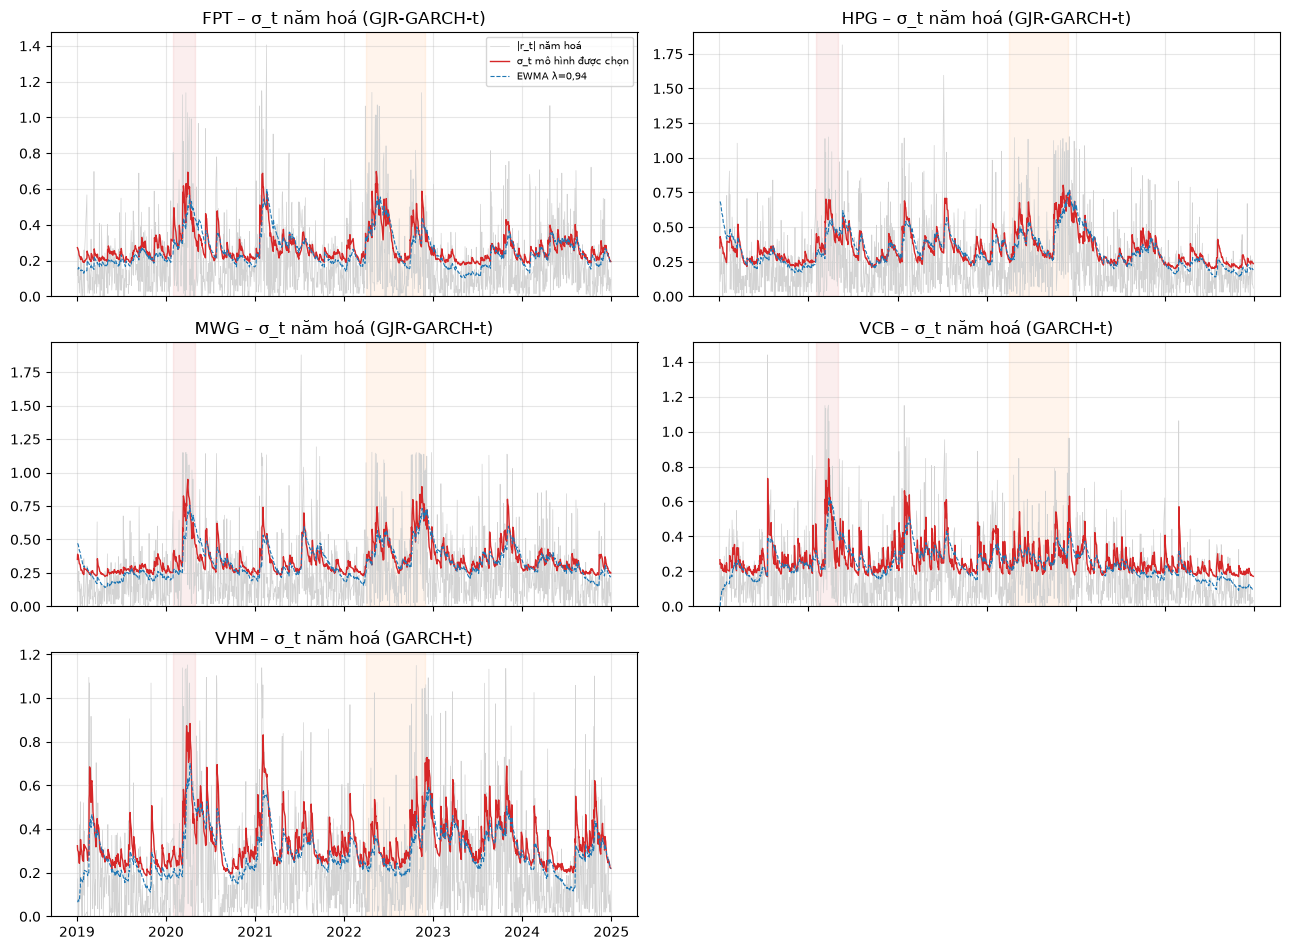

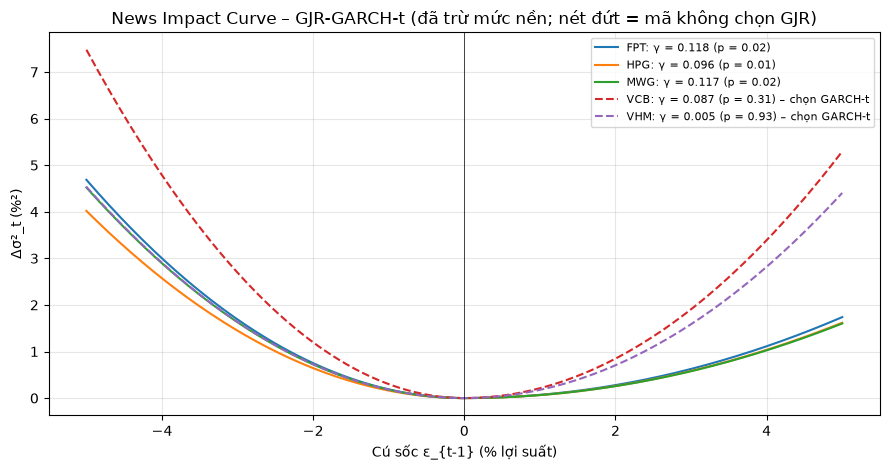

In [16]:
# ===================== 2.3 LƯU ε, σ + BIỂU ĐỒ =====================
std_resid = pd.DataFrame({tk: selected[tk]["std_resid"] for tk in tickers}, index=log_ret.index)
cond_vol = pd.DataFrame({tk: selected[tk]["sigma"] for tk in tickers}, index=log_ret.index)
mu_vec = pd.Series({tk: selected[tk]["params"]["mu"] / SCALE for tk in tickers})      # μ thập phân
sigma_fcst = pd.Series({tk: selected[tk]["sigma_fcst"] for tk in tickers}, name="sigma_T+1")
print("Phần dư chuẩn hoá (kỳ vọng mean ≈ 0, std ≈ 1):")
resid_stats = std_resid.agg(["mean", "std", "skew", "kurt"]).T
display(resid_stats.round(4))
low_std = resid_stats.index[resid_stats["std"] < 0.95].tolist()
if low_std:
    print("Lưu ý: std(ε) < 0,95 ở " + ", ".join(low_std) + " -> σ_t hơi cao hơn biến động thực hiện "
          "(thường gặp khi persistence sát 1 / IGARCH hoặc phân phối t với ν nhỏ) -> VaR từ các mã này có xu hướng thận trọng.")
print("σ dự báo phiên T+1 (%/ngày):", (sigma_fcst * 100).round(3).to_dict())

ewma = log_ret.pow(2).ewm(alpha=1 - 0.94, adjust=False).mean().shift(1).pipe(np.sqrt)
fig, axes = grid_axes(N, sharex=True)
for ax, tk in zip(axes, tickers):
    ax.plot(log_ret.index, log_ret[tk].abs() * np.sqrt(TRADING_DAYS), color="lightgrey", lw=0.5, label="|r_t| năm hoá")
    ax.plot(cond_vol.index, cond_vol[tk] * np.sqrt(TRADING_DAYS), color="tab:red", lw=1, label="σ_t mô hình được chọn")
    ax.plot(ewma.index, ewma[tk] * np.sqrt(TRADING_DAYS), color="tab:blue", lw=0.8, ls="--", label="EWMA λ=0,94")
    shade_stress(ax, alpha=0.08, label=False)
    ax.set_title(f"{tk} – σ_t năm hoá ({best_name[tk]})"); ax.set_ylim(0, None); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV2"] / "2_conditional_volatility.png", dpi=150, bbox_inches="tight"); plt.show()

# News Impact Curve: σ²_t theo cú sốc ε_{t-1}, giữ σ²_{t-1} = phương sai mẫu.
# Dùng GJR-GARCH-t cho CẢ 5 mã để so sánh mức bất đối xứng; mã có mô hình được chọn KHÔNG phải GJR (γ không có ý nghĩa)
# vẽ nét đứt – với các mã này đường cong gần đối xứng, đúng với kết luận "không có hiệu ứng đòn bẩy".
fig, ax = plt.subplots(figsize=(9, 4.8))
shocks = np.linspace(-5, 5, 201)
for tk in tickers:
    f = fits[(tk, "GJR-GARCH-t")]
    p = f["params"]
    nic = p["omega"] + (p["alpha"] + p["gamma"] * (shocks < 0)) * shocks ** 2 + p["beta"] * (log_ret[tk] * SCALE).var()
    chosen_gjr = best_name[tk].startswith("GJR")
    ax.plot(shocks, nic - nic.min(), ls="-" if chosen_gjr else "--",
            label=f"{tk}: γ = {p['gamma']:.3f} (p = {f['pvalue']['gamma']:.2f})"
                  + ("" if chosen_gjr else f" – chọn {best_name[tk]}"))
ax.axvline(0, color="k", lw=0.5); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("News Impact Curve – GJR-GARCH-t (đã trừ mức nền; nét đứt = mã không chọn GJR)")
ax.set_xlabel("Cú sốc ε_{t-1} (% lợi suất)"); ax.set_ylabel("Δσ²_t (%²)")
plt.tight_layout(); plt.savefig(OUT["TV2"] / "2_news_impact_curve.png", dpi=150); plt.show()

## 2.4 Chẩn đoán phần dư (Residual Diagnostics)
**Tầng 1:** Ljung-Box trên ε kiểm tra tự tương quan còn sót trong phương trình trung bình; Ljung-Box trên ε² kiểm tra **hiệu ứng ARCH còn sót**.
So với $r_t^2$ ở TV1 (p ≈ 0): nếu p của ε² > 0,05 ⇒ GARCH đã "hấp thụ" cụm biến động.

**Tầng 3:** Yêu cầu của đề: p ≥ 0,05 ở cả ε và ε². Nếu một mã còn p < 0,05 ở ε (mức sát ngưỡng) nhưng ε² đạt, phần biến động đã được
mô hình hoá tốt; phần tự tương quan nhỏ còn lại nằm ở phương trình trung bình (có thể thêm AR(1) nếu muốn loại bỏ hoàn toàn).
So sánh với TV1: tự tương quan của r_t ở VCB/VHM có thể biến mất sau khi chuẩn hoá bằng σ_t (do các ngày biến động lớn chi phối Q-stat).

In [17]:
# ===================== 2.4 LJUNG-BOX TRÊN ε VÀ ε² =====================
diag_rows = []
for tk in tickers:
    for label, s in [("r_t² (trước GARCH)", log_ret[tk] ** 2), ("ε", std_resid[tk]), ("ε²", std_resid[tk] ** 2)]:
        for m, row in ljung_box(s, LB_LAGS).iterrows():
            diag_rows.append({"Mã": tk, "Chuỗi": label, "Lag": int(m), "Q": row["Q"], "p-value": row["p-value"]})
diagnostics = pd.DataFrame(diag_rows)
diag_pivot = diagnostics.pivot_table(index=["Mã", "Chuỗi"], columns="Lag", values="p-value", sort=False)
diag_pivot.columns = [f"p (lag {c})" for c in diag_pivot.columns]
display(diag_pivot.round(4))
at = lambda lab: diagnostics[(diagnostics["Chuỗi"] == lab) & (diagnostics["Lag"] == max_lag)].set_index("Mã")["p-value"]
print(f"ε  (lag {max_lag}): " + ", ".join(f"{tk}={'còn tự tương quan' if p < ALPHA else 'đạt'} (p={p:.3f})" for tk, p in at("ε").items()))
print(f"ε² (lag {max_lag}): " + ", ".join(f"{tk}={'CÒN ARCH' if p < ALPHA else 'đã loại bỏ ARCH'} (p={p:.3f})" for tk, p in at("ε²").items()))

# ---- Lưu kết quả TV2 ----
# Lưu ý đơn vị: mô hình ước lượng trên lợi suất % (r × 100) -> mu tính bằng %/ngày, omega bằng %²
UNIT = {"mu": "mu (%/ngày)", "omega": "omega (%²)"}
selected_df = pd.DataFrame({tk: {
    "Mô hình": best_name[tk], **{UNIT.get(k, k): v for k, v in selected[tk]["params"].items()},
    "LogLik": selected[tk]["LL"], "k": selected[tk]["k"], "AIC": selected[tk]["AIC"], "BIC": selected[tk]["BIC"],
    "Persistence": selected[tk]["persistence"], "IGARCH?": "CÓ" if selected[tk]["IGARCH"] else "không",
    "Half-life (phiên)": selected[tk]["half_life"],
    "σ dài hạn năm (%)": selected[tk]["uncond_vol_ann"] * 100,
    "σ T+1 (%/ngày)": sigma_fcst[tk] * 100,
    "std(ε)": std_resid[tk].std()} for tk in tickers}).T
display(selected_df)
std_resid.to_csv(OUT["TV2"] / "std_resid.csv", encoding="utf-8-sig")
cond_vol.to_csv(OUT["TV2"] / "cond_vol.csv", encoding="utf-8-sig")
with pd.ExcelWriter(OUT["TV2"] / "TV2_garch_results.xlsx", engine="openpyxl") as xw:
    selected_df.to_excel(xw, sheet_name="Mo_hinh_chon")
    comparison.to_excel(xw, sheet_name="So_sanh_AIC_BIC", index=False)
    lr_table.to_excel(xw, sheet_name="LR_GJR_vs_GARCH", index=False)
    all_params.to_excel(xw, sheet_name="Tham_so_day_du", index=False)
    diagnostics.to_excel(xw, sheet_name="Ljung_Box_phan_du", index=False)
print("✔ Đã lưu kết quả TV2 vào", OUT["TV2"])

p (lag 5)  p (lag 10)  p (lag 20)
Mã  Chuỗi                                                
FPT r_t² (trước GARCH)     0.0000      0.0000      0.0000
    ε                      0.3080      0.4558      0.6845
    ε²                     0.3982      0.5576      0.0880
HPG r_t² (trước GARCH)     0.0000      0.0000      0.0000
    ε                      0.5189      0.5902      0.2022
    ε²                     0.5610      0.6306      0.8146
MWG r_t² (trước GARCH)     0.0000      0.0000      0.0000
    ε                      0.0206      0.0693      0.0423
    ε²                     0.6094      0.8189      0.9546
VCB r_t² (trước GARCH)     0.0000      0.0000      0.0000
    ε                      0.4947      0.3671      0.2954
    ε²                     0.7920      0.9738      0.9912
VHM r_t² (trước GARCH)     0.0000      0.0000      0.0000
    ε                      0.1027      0.4544      0.4804
    ε²                     0.3976      0.6461      0.9261

ε  (lag 20): FPT=đạt (p=0.685), HPG=đạt (p=0.202), MWG=còn tự tương quan (p=0.042), VCB=đạt (p=0.295), VHM=đạt (p=0.480)
ε² (lag 20): FPT=đã loại bỏ ARCH (p=0.088), HPG=đã loại bỏ ARCH (p=0.815), MWG=đã loại bỏ ARCH (p=0.955), VCB=đã loại bỏ ARCH (p=0.991), VHM=đã loại bỏ ARCH (p=0.926)


,Mô hình,mu (%/ngày),omega (%²),alpha,gamma,beta,nu,LogLik,k,AIC,BIC,Persistence,IGARCH?,Half-life (phiên),σ dài hạn năm (%),σ T+1 (%/ngày),std(ε)
FPT,GJR-GARCH-t,0.101807,0.161703,0.06952,0.117944,0.842601,3.575097,-2625.857396,6,5263.714791,5295.398974,0.971093,không,23.629918,37.545216,1.20172,0.945518
HPG,GJR-GARCH-t,0.021296,0.144603,0.064712,0.096001,0.872191,4.260329,-3011.141216,6,6034.282432,6065.966615,0.984904,không,45.568407,49.131147,1.450834,0.974156
MWG,GJR-GARCH-t,0.058499,0.258316,0.064056,0.11677,0.84442,3.655248,-2991.517555,6,5995.035109,6026.719292,0.966861,không,20.568041,44.320902,1.563103,0.950347
VCB,GARCH-t,0.018914,0.354352,0.246006,NaN,0.679968,3.607197,-2590.315437,5,5190.630874,5217.03436,0.925974,không,9.01253,34.731613,1.079872,0.961384
VHM,GARCH-t,-0.061928,0.227168,0.178429,NaN,0.821471,3.037302,-2845.140673,5,5700.281346,5726.684832,0.9999,CÓ,NaN,NaN,1.346655,0.892154


✔ Đã lưu kết quả TV2 vào D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput\TV2_GARCH


## 2.5 Diễn giải cốt lõi – vai trò của GARCH đơn biến trong DCC hai bước
DCC-GARCH (Engle, 2002) tách log-likelihood thành **phần biến động** + **phần tương quan**:
1. **Bước 1 (TV2):** GARCH riêng cho từng mã ⇒ có $\sigma_{i,t}$, **chuẩn hoá biến động riêng lẻ**, loại bỏ phương sai thay đổi theo thời gian.
2. **Bước 2 (TV3):** dùng $\epsilon_{i,t}$ (phương sai ≈ 1, không còn ARCH) làm đầu vào để ước lượng tương quan động $R_t$.

Nếu bỏ bước 1, hai mã cùng tăng biến động sẽ trông như tương quan tăng ⇒ tương quan ước lượng bị nhiễu bởi biến động.

### TV2 – Gợi ý trả lời vấn đáp
**Câu 1 – α + β ≈ 1 nghĩa là gì?** Biến động có **độ bền rất cao**: cú sốc hôm nay ảnh hưởng tới biến động nhiều tuần sau (half-life dài),
phương sai hội tụ rất chậm về mức dài hạn. Khi α + β = 1 là IGARCH (giống EWMA) – cú sốc không bao giờ tắt và phương sai dài hạn không
tồn tại (trường hợp được đánh dấu IGARCH ở bảng trên). Hệ quả: dự báo VaR nhiều ngày phải dùng σ hiện tại, không thể giả định nhanh chóng quay về mức bình thường.

**Câu 2 – Hiệu ứng đòn bẩy ở Việt Nam?** γ > 0 ⇒ phiên giảm điểm làm biến động phiên sau tăng mạnh hơn phiên tăng cùng biên độ.
Thị trường Việt Nam có tỷ trọng nhà đầu tư cá nhân lớn và dùng margin nhiều: giá giảm ⇒ call margin ⇒ bán giải chấp dây chuyền ⇒ biến động
tăng (rõ nhất năm 2022). Về quản trị: VaR cần phản ứng nhanh hơn sau phiên giảm mạnh.

---
# THÀNH VIÊN 3: MÔ HÌNH HOÁ TƯƠNG QUAN ĐỘNG (DCC-GARCH ESTIMATION)
## 3.1 Ước lượng DCC(1,1) – Engle (2002)
**Tầng 1:**
- a. $Q_t = (1-a-b)\bar{Q} + a\,\epsilon_{t-1}\epsilon_{t-1}' + b\,Q_{t-1}$, với $\bar Q$ = hiệp phương sai mẫu của ε (correlation targeting).
- b. Điều kiện dừng: $a \ge 0,\ b \ge 0,\ a + b < 1$.
- c. $R_t = \operatorname{diag}(Q_t)^{-1/2}\,Q_t\,\operatorname{diag}(Q_t)^{-1/2}$.
- d. $H_t = D_t R_t D_t$, $D_t = \operatorname{diag}(\sigma_{1,t}, \dots, \sigma_{N,t})$ lấy từ TV2.
- Log-likelihood phần tương quan (bước 2): $LL_C(a,b) = -\tfrac12\sum_t\left(\ln|R_t| + \epsilon_t'R_t^{-1}\epsilon_t - \epsilon_t'\epsilon_t\right)$.

**Tầng 2:** Input `std_resid` (ε), `cond_vol` (σ), `mu_vec` của TV2. Output dùng chung: `a_hat`, `b_hat`, `R_t`, `H_t` (T × N × N),
`R_fcst`, `H_fcst` (dự báo phiên T+1). Tối ưu bằng SLSQP; sai số chuẩn robust (chưa hiệu chỉnh sai số ước lượng bước 1).

**Tầng 3:** a nhỏ (0,01–0,05), b lớn (> 0,9) là điển hình; half-life tương quan $= \ln 0{,}5/\ln(a+b)$ phiên.

In [18]:
# ===================== 3.1 DCC(1,1) =====================
Z = std_resid.values                                   # T × N
Qbar = Z.T @ Z / T


def dcc_filter(a, b, Z, Qbar):
    """Trả về Q (T×N×N), R (T×N×N) và Q_{T+1}."""
    Tn, Nn = Z.shape
    Q = np.empty((Tn, Nn, Nn)); R = np.empty((Tn, Nn, Nn))
    q = Qbar.copy()
    for t in range(Tn):
        if t > 0:
            q = (1 - a - b) * Qbar + a * np.outer(Z[t - 1], Z[t - 1]) + b * q
        Q[t] = q
        d = 1 / np.sqrt(np.diag(q))
        R[t] = q * np.outer(d, d)                      # diag(Q)^-1/2 Q diag(Q)^-1/2
    q_next = (1 - a - b) * Qbar + a * np.outer(Z[-1], Z[-1]) + b * q
    return Q, R, q_next


def corr_loglik_t(R, Z):
    """Đóng góp log-likelihood phần tương quan theo từng ngày."""
    _, logdet = np.linalg.slogdet(R)
    quad = np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z)
    return -0.5 * (logdet + quad - np.einsum("ti,ti->t", Z, Z))


def dcc_nll(p):
    a, b = p
    if a < 0 or b < 0 or a + b >= 1:
        return 1e10
    return -corr_loglik_t(dcc_filter(a, b, Z, Qbar)[1], Z).sum()


best = None
for x0 in [(0.02, 0.95), (0.05, 0.90), (0.10, 0.80)]:
    res = minimize(dcc_nll, x0, method="SLSQP", bounds=[(0, 1), (0, 1)],
                   constraints=[{"type": "ineq", "fun": lambda p: 0.9999 - p[0] - p[1]}],
                   options={"maxiter": 500, "ftol": 1e-10})
    if best is None or res.fun < best.fun:
        best = res
a_hat, b_hat = best.x
se_ab = robust_se(lambda p: corr_loglik_t(dcc_filter(p[0], p[1], Z, Qbar)[1], Z), best.x)
Q_t, R_t, Q_next = dcc_filter(a_hat, b_hat, Z, Qbar)
half_life_corr = np.log(0.5) / np.log(a_hat + b_hat)

dcc_params = pd.DataFrame({"Ước lượng": [a_hat, b_hat, a_hat + b_hat, half_life_corr],
                           "Std.Err": [se_ab[0], se_ab[1], np.nan, np.nan]},
                          index=["a", "b", "a + b", "Half-life tương quan (phiên)"])
dcc_params["p-value"] = 2 * stats.norm.sf(np.abs(dcc_params["Ước lượng"] / dcc_params["Std.Err"]))
display(dcc_params.round(5))
ok_stat = (a_hat >= 0) and (b_hat >= 0) and (a_hat + b_hat < 1)
print(f"Điều kiện dừng a ≥ 0, b ≥ 0, a + b < 1: {'THOẢ' if ok_stat else 'KHÔNG THOẢ'} "
      f"(a = {a_hat:.4f}, b = {b_hat:.4f}, a + b = {a_hat + b_hat:.4f}) | hội tụ: {best.success}")

,Ước lượng,Std.Err,p-value
a,0.02787,0.00567,0.0
b,0.93019,0.01998,0.0
a + b,0.95805,NaN,NaN
Half-life tương quan (phiên),16.17553,NaN,NaN


Điều kiện dừng a ≥ 0, b ≥ 0, a + b < 1: THOẢ (a = 0.0279, b = 0.9302, a + b = 0.9581) | hội tụ: True


In [19]:
# ===================== 3.1c–d R_t, H_t VÀ DỰ BÁO T+1 =====================
S = cond_vol.values                                     # σ_t (thập phân)
H_t = R_t * S[:, :, None] * S[:, None, :]               # H_t = D_t R_t D_t
d_next = 1 / np.sqrt(np.diag(Q_next))
R_fcst = Q_next * np.outer(d_next, d_next)
H_fcst = R_fcst * np.outer(sigma_fcst.values, sigma_fcst.values)
eig_min = np.linalg.eigvalsh(H_t).min()
print(f"Đường chéo R_t = 1: {np.allclose(np.einsum('tii->ti', R_t), 1)} | H_t đối xứng: {np.allclose(H_t, H_t.transpose(0, 2, 1))} "
      f"| H_t xác định dương (λ_min = {eig_min:.2e}): {eig_min > 0}")
print(f"Kiểm tra sqrt(diag H_t) = σ_t của TV2: {np.allclose(np.sqrt(np.einsum('tii->ti', H_t)), S)}")
idx_tk = {tk: i for i, tk in enumerate(tickers)}
pairs_all = list(combinations(tickers, 2))
dyn_corr = pd.DataFrame({f"{x}-{y}": R_t[:, idx_tk[x], idx_tk[y]] for x, y in pairs_all}, index=log_ret.index)
print("Ma trận tương quan dự báo R_{T+1}:")
display(pd.DataFrame(R_fcst, index=tickers, columns=tickers).round(3))

Đường chéo R_t = 1: True | H_t đối xứng: True | H_t xác định dương (λ_min = 7.01e-05): True
Kiểm tra sqrt(diag H_t) = σ_t của TV2: True
Ma trận tương quan dự báo R_{T+1}:


,FPT,HPG,MWG,VCB,VHM
FPT,1.000,0.456,0.485,0.280,0.255
HPG,0.456,1.000,0.417,0.322,0.368
MWG,0.485,0.417,1.000,0.310,0.286
VCB,0.280,0.322,0.310,1.000,0.322
VHM,0.255,0.368,0.286,0.322,1.000


## 3.2 So sánh mô hình: DCC vs CCC vs Hiệp phương sai tĩnh
**Tầng 1:** Cả 3 mô hình được so sánh bằng **cùng một hàm hợp lý chuẩn đa biến**
$LL = -\tfrac12\sum_t\left[N\ln 2\pi + \ln|H_t| + e_t'H_t^{-1}e_t\right]$, $e_t = r_t - \mu$:
- **Static:** $H_t = \Sigma$ cố định (hiệp phương sai mẫu) – bỏ qua cả biến động lẫn tương quan thay đổi.
- **CCC (Bollerslev, 1990):** $H_t = D_t R D_t$, R cố định = tương quan mẫu của ε.
- **DCC:** $H_t = D_t R_t D_t$.

CCC và DCC dùng chung $D_t$ của TV2 nên chênh lệch LL chỉ đến từ việc cho tương quan thay đổi. Kiểm định LR: $H_0$: a = b = 0 (DCC thu về CCC),
$LR = 2(LL_{DCC} - LL_{CCC})$ ~ hỗn hợp $\tfrac14\chi^2_0 + \tfrac12\chi^2_1 + \tfrac14\chi^2_2$ (tham số nằm trên biên).

**Tầng 3:** DCC có LL lớn nhất và AIC/BIC nhỏ nhất, LR p < 0,05 ⇒ **tương quan giữa các cổ phiếu VN30 thay đổi theo thời gian**, không bất biến.

In [20]:
# ===================== 3.2 BENCHMARK =====================
e = (log_ret - mu_vec).values


def mvn_loglik_from_R(R):
    """LL chuẩn đa biến khi H_t = D_t R_t D_t (R: N×N hoặc T×N×N)."""
    R = np.broadcast_to(R, (T, N, N))
    _, logdet_R = np.linalg.slogdet(R)
    quad = np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z)
    return np.sum(-0.5 * (N * np.log(2 * np.pi) + 2 * np.log(S).sum(axis=1) + logdet_R + quad))


k_margin = int(sum(selected[tk]["k"] for tk in tickers))
R_ccc = np.corrcoef(Z, rowvar=False)
Sigma = np.cov(log_ret.values, rowvar=False, bias=True)
bench = pd.DataFrame({
    "LogLik": [stats.multivariate_normal(log_ret.mean().values, Sigma).logpdf(log_ret.values).sum(),
               mvn_loglik_from_R(R_ccc), mvn_loglik_from_R(R_t)],
    "k": [N + N * (N + 1) // 2, k_margin + N * (N - 1) // 2, k_margin + N * (N - 1) // 2 + 2]},
    index=["Static Covariance", "CCC-GARCH", "DCC-GARCH"])
bench["AIC"] = -2 * bench["LogLik"] + 2 * bench["k"]
bench["BIC"] = -2 * bench["LogLik"] + np.log(T) * bench["k"]
bench["Hạng AIC"] = bench["AIC"].rank().astype(int)
bench["Hạng BIC"] = bench["BIC"].rank().astype(int)
display(bench.round(2))
LR_dcc = 2 * (bench.loc["DCC-GARCH", "LogLik"] - bench.loc["CCC-GARCH", "LogLik"])
p_lr = 0.5 * stats.chi2.sf(LR_dcc, 1) + 0.25 * stats.chi2.sf(LR_dcc, 2)
print(f"LR (DCC vs CCC) = {LR_dcc:.2f}, p-value = {p_lr:.3g} -> "
      + ("Bác bỏ H0: tương quan THAY ĐỔI theo thời gian" if p_lr < ALPHA else "Chưa bác bỏ tương quan bất biến"))

,LogLik,k,AIC,BIC,Hạng AIC,Hạng BIC
Static Covariance,19308.96,20,-38577.91,-38472.30,3,3
CCC-GARCH,19623.30,38,-39170.59,-38969.92,2,2
DCC-GARCH,19678.39,40,-39276.79,-39065.56,1,1


LR (DCC vs CCC) = 110.19, p-value = 3.39e-25 -> Bác bỏ H0: tương quan THAY ĐỔI theo thời gian


## 3.3 Trực quan hoá tương quan động
**Tầng 3:** đường xanh = ρ_t của DCC; nét đứt = tương quan CCC (hằng số); đường xanh lá = tương quan trượt 60 phiên (Pearson) để đối chiếu.
Vùng tô đỏ = giai đoạn khủng hoảng. Tương quan tăng vọt trong khủng hoảng ⇒ lợi ích đa dạng hoá giảm đúng lúc cần nhất.

**Lưu ý khi đọc các cú giảm đột ngột:** DCC phản ứng với tích $\epsilon_{i,t-1}\epsilon_{j,t-1}$. Một ngày hai mã có phần dư rất lớn **trái dấu**
kéo tương quan xuống mạnh. Ví dụ 09/07/2021: HPG −10% (ε = −5,1) và MWG +11,8% (ε = +6,2) – cả hai là lợi suất **dồn qua 4 ngày Yahoo thiếu
dữ liệu** (xem `outliers_check.csv` của TV1) ⇒ HPG–MWG rơi xuống ≈ −0,40 ngày 13/07/2021 là **hiệu ứng của dữ liệu**, không phải thay đổi
kinh tế thật. Ngược lại, cú giảm của các cặp có VCB ngày 24–25/01/2022 là thật: VCB tăng +4,2% trong phiên thị trường giảm mạnh.

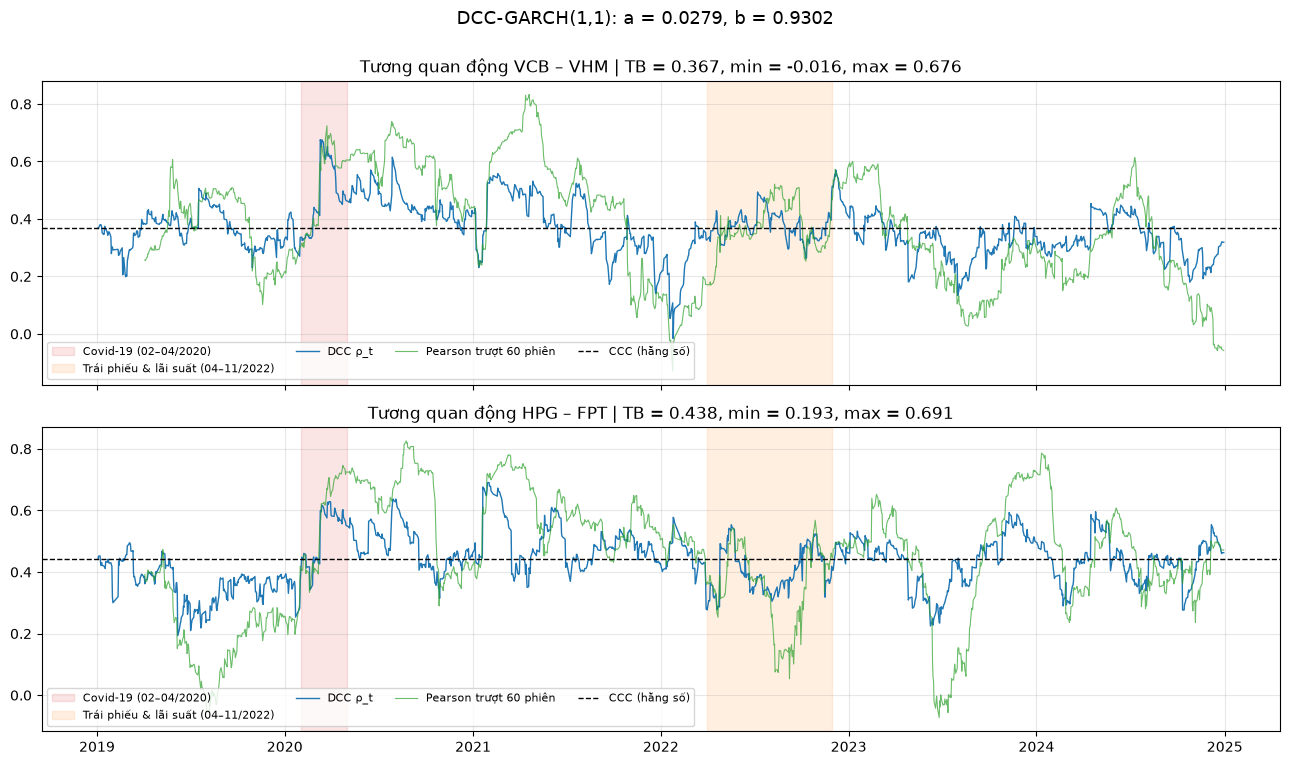

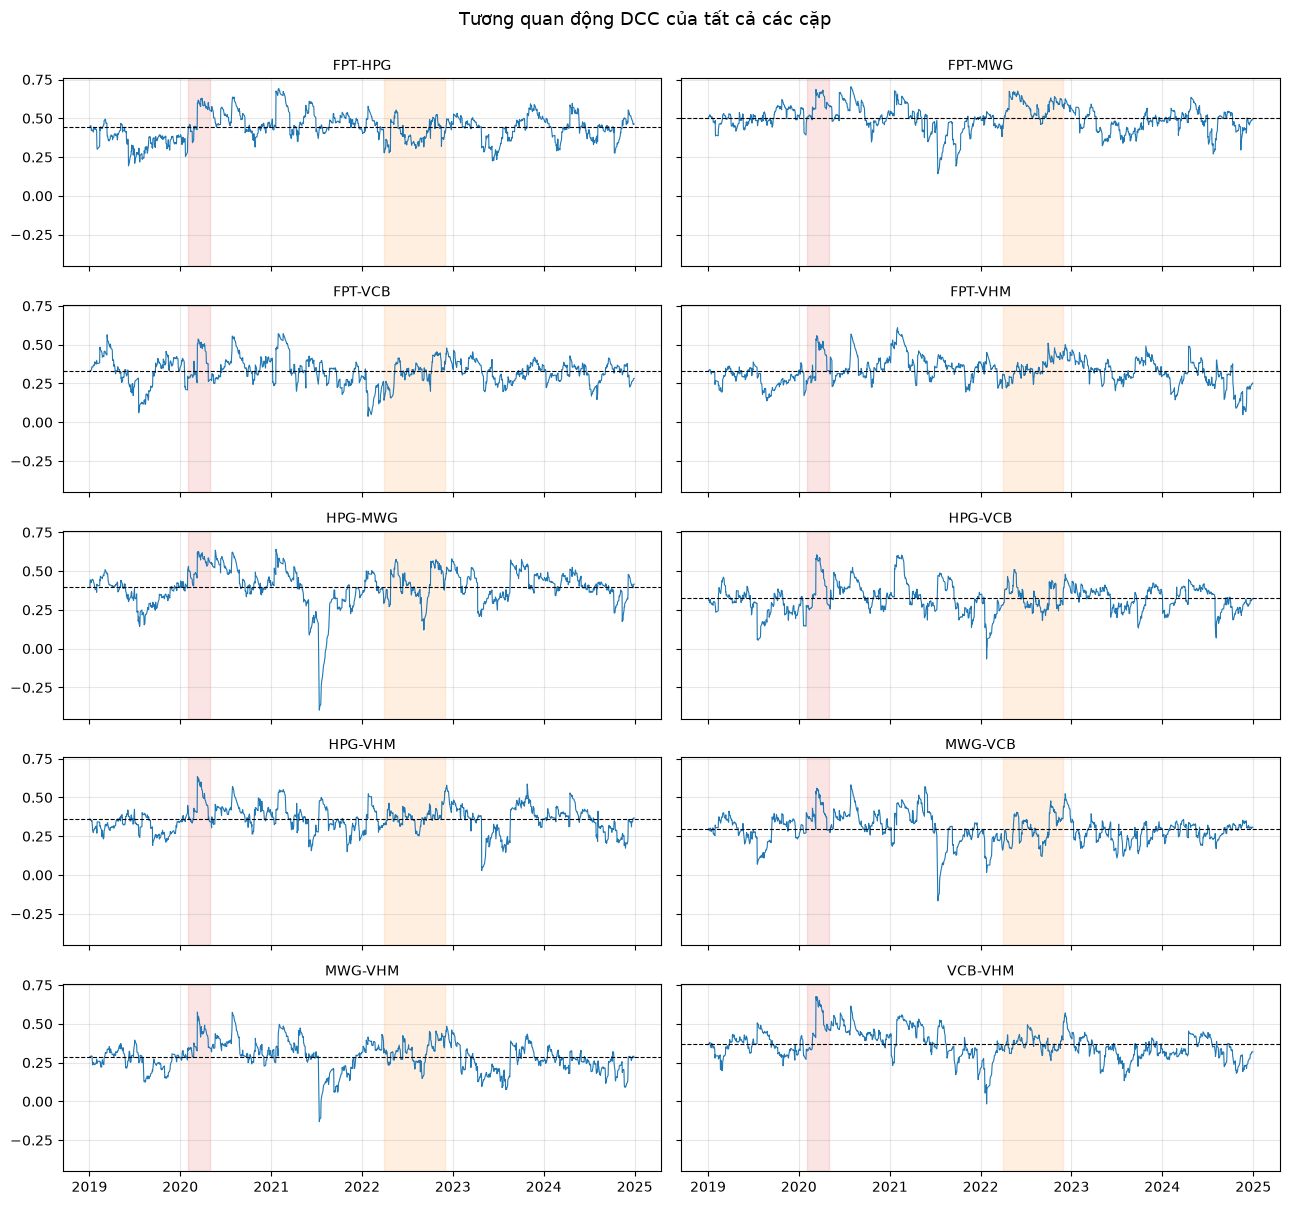

In [21]:
# ===================== 3.3 ĐỒ THỊ TƯƠNG QUAN ĐỘNG =====================
pairs_main = [p for p in PAIRS if p[0] in idx_tk and p[1] in idx_tk]
fig, axes = plt.subplots(len(pairs_main), 1, figsize=(13, 3.8 * len(pairs_main)), sharex=True, squeeze=False)
for ax, (x, y) in zip(axes.flat, pairs_main):
    s = pd.Series(R_t[:, idx_tk[x], idx_tk[y]], index=log_ret.index)
    shade_stress(ax)
    ax.plot(s.index, s, lw=1, color="tab:blue", label="DCC ρ_t")
    ax.plot(s.index, log_ret[x].rolling(60).corr(log_ret[y]), lw=0.8, color="tab:green", alpha=0.7, label="Pearson trượt 60 phiên")
    ax.axhline(R_ccc[idx_tk[x], idx_tk[y]], color="black", ls="--", lw=1, label="CCC (hằng số)")
    ax.set_title(f"Tương quan động {x} – {y} | TB = {s.mean():.3f}, min = {s.min():.3f}, max = {s.max():.3f}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.suptitle(f"DCC-GARCH(1,1): a = {a_hat:.4f}, b = {b_hat:.4f}", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_main_pairs.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = grid_axes(len(pairs_all), h=2.4, sharex=True, sharey=True)
for ax, col in zip(axes, dyn_corr.columns):
    x, y = col.split("-")
    shade_stress(ax, label=False)
    ax.plot(dyn_corr.index, dyn_corr[col], lw=0.8)
    ax.axhline(R_ccc[idx_tk[x], idx_tk[y]], color="black", ls="--", lw=0.8)
    ax.set_title(col, fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("Tương quan động DCC của tất cả các cặp", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_all_pairs.png", dpi=150, bbox_inches="tight"); plt.show()

,Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022)
FPT-HPG,0.439,0.522,0.403
FPT-MWG,0.487,0.590,0.579
FPT-VCB,0.330,0.388,0.328
FPT-VHM,0.326,0.393,0.351
HPG-MWG,0.391,0.535,0.415
HPG-VCB,0.320,0.403,0.331
HPG-VHM,0.353,0.455,0.373
MWG-VCB,0.294,0.415,0.298
MWG-VHM,0.278,0.405,0.321
VCB-VHM,0.360,0.484,0.376


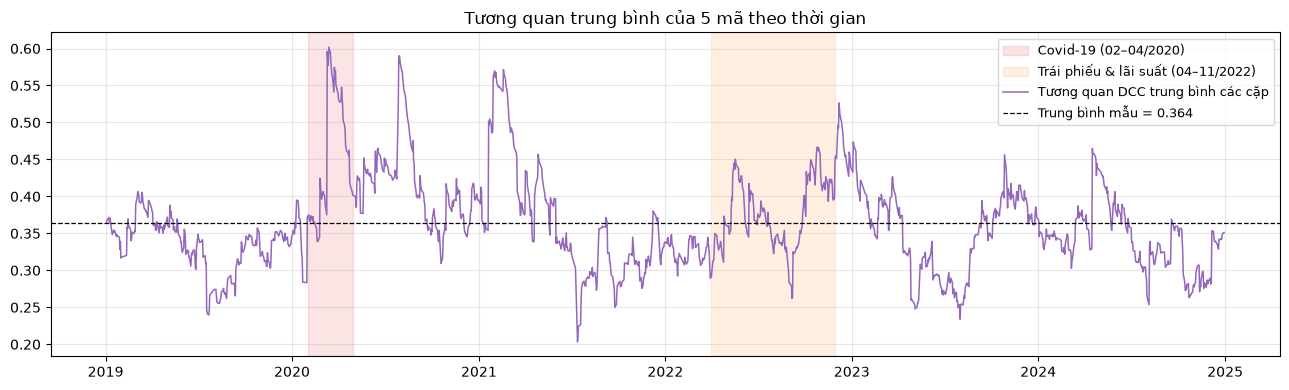

✔ Đã lưu kết quả TV3 vào D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput\TV3_DCC


In [22]:
# ===================== 3.3b TƯƠNG QUAN THEO GIAI ĐOẠN =====================
def period_masks(index):
    """Mặt nạ True/False cho từng giai đoạn: các giai đoạn STRESS + 'Bình thường' (ngoài mọi giai đoạn stress)."""
    m = {name: (index >= s) & (index <= e) for name, (s, e) in STRESS.items()}
    m = {"Bình thường": ~np.any(np.column_stack(list(m.values())), axis=1), **m}
    return m


masks = period_masks(log_ret.index)
avg_corr = dyn_corr.mean(axis=1)
corr_by_period = pd.DataFrame({name: dyn_corr[m].mean() for name, m in masks.items()})
corr_by_period.loc["TRUNG BÌNH CÁC CẶP"] = corr_by_period.mean()
display(corr_by_period.round(3))

fig, ax = plt.subplots(figsize=(13, 4))
shade_stress(ax)
ax.plot(avg_corr.index, avg_corr, color="tab:purple", lw=1.1, label="Tương quan DCC trung bình các cặp")
ax.axhline(avg_corr.mean(), color="black", ls="--", lw=0.9, label=f"Trung bình mẫu = {avg_corr.mean():.3f}")
ax.set_title("Tương quan trung bình của 5 mã theo thời gian"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_average_corr.png", dpi=150); plt.show()

# ---- Lưu kết quả TV3 ----
# dates/tickers lưu dạng chuỗi Unicode cố định (U10) để đọc lại được bằng np.load(..., allow_pickle=False)
np.savez_compressed(OUT["TV3"] / "dcc_matrices.npz",
                    dates=np.array(log_ret.index.strftime("%Y-%m-%d").tolist(), dtype="U10"),
                    tickers=np.array(tickers, dtype="U10"), R=R_t, H=H_t, R_fcst=R_fcst, H_fcst=H_fcst, a=a_hat, b=b_hat, Qbar=Qbar)
with pd.ExcelWriter(OUT["TV3"] / "TV3_dcc_results.xlsx", engine="openpyxl") as xw:
    dcc_params.to_excel(xw, sheet_name="Tham_so_DCC")
    bench.to_excel(xw, sheet_name="Benchmark")
    corr_by_period.to_excel(xw, sheet_name="Tuong_quan_theo_giai_doan")
    pd.DataFrame(R_fcst, index=tickers, columns=tickers).to_excel(xw, sheet_name="R_T+1")
    pd.DataFrame(H_fcst, index=tickers, columns=tickers).to_excel(xw, sheet_name="H_T+1")
    pd.DataFrame(Qbar, index=tickers, columns=tickers).to_excel(xw, sheet_name="Q_bar")
    dyn_corr.to_excel(xw, sheet_name="Tuong_quan_dong")
print("✔ Đã lưu kết quả TV3 vào", OUT["TV3"])

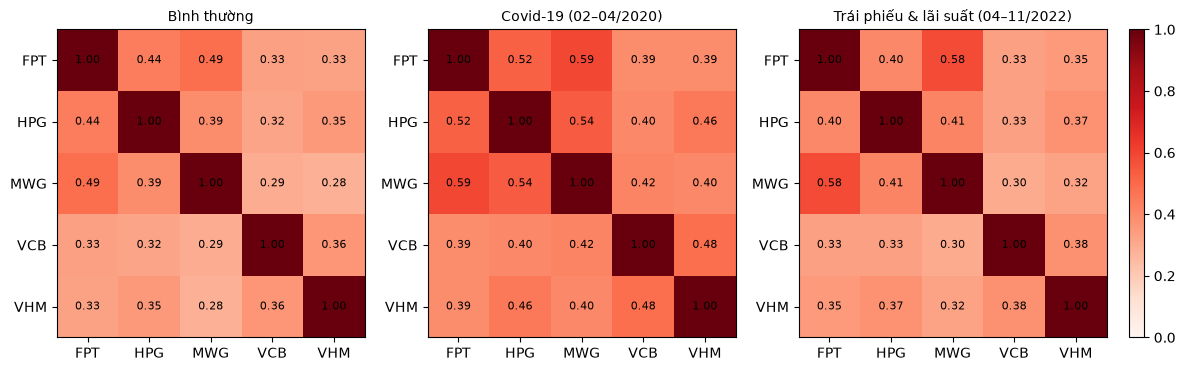

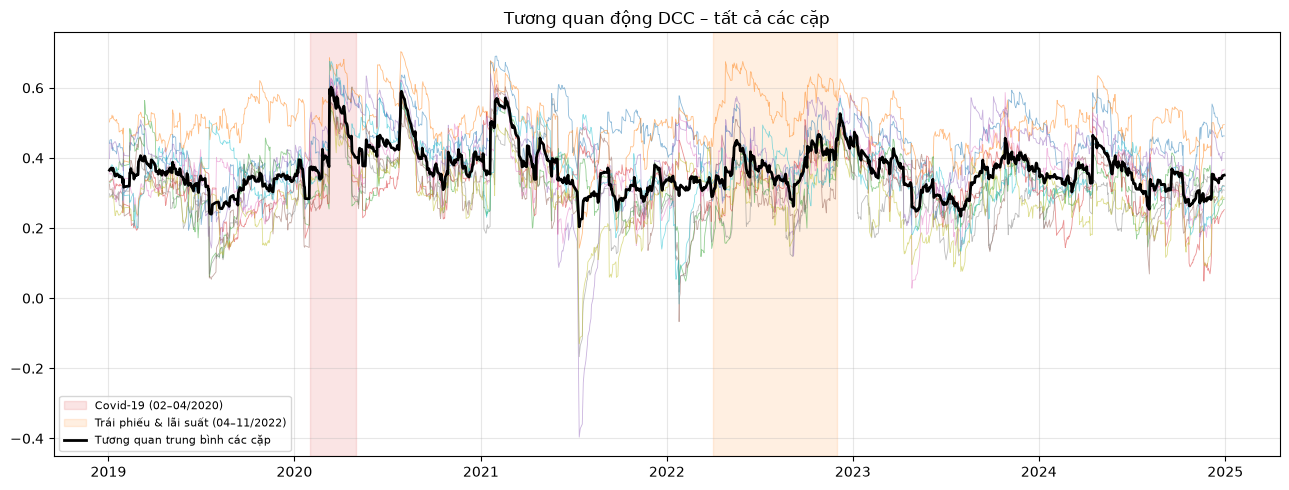

In [23]:
# ===================== 3.3c HEATMAP THEO GIAI ĐOẠN & ĐỒ THỊ CHỒNG TẤT CẢ CÁC CẶP =====================
fig, axes = plt.subplots(1, len(masks), figsize=(4.4 * len(masks) + 1.0, 4.0))
for ax, (name, mk) in zip(np.atleast_1d(axes), masks.items()):
    Rm = R_t[np.asarray(mk)].mean(axis=0)                  # ma trận tương quan DCC trung bình trong giai đoạn
    im = ax.imshow(Rm, cmap="Reds", vmin=0, vmax=1)
    ax.set_xticks(range(N)); ax.set_xticklabels(tickers); ax.set_yticks(range(N)); ax.set_yticklabels(tickers)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{Rm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(name, fontsize=10)
fig.colorbar(im, ax=list(np.atleast_1d(axes)), fraction=0.025, pad=0.02)
plt.savefig(OUT["TV3"] / "3_dcc_heatmap_by_period.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
shade_stress(ax)
for col in dyn_corr.columns:
    ax.plot(dyn_corr.index, dyn_corr[col], lw=0.6, alpha=0.5)
ax.plot(avg_corr.index, avg_corr, color="black", lw=2, label="Tương quan trung bình các cặp")
ax.set_title("Tương quan động DCC – tất cả các cặp"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_all_pairs_overlay.png", dpi=150); plt.show()

## 3.4 Diễn giải cốt lõi tham số a và b

In [24]:
# ===================== 3.4 DIỄN GIẢI TỰ ĐỘNG =====================
print(f"a = {a_hat:.4f}: mỗi phiên, tích chéo cú sốc ε_(t-1)ε_(t-1)' đóng góp {a_hat:.1%} vào Q_t -> "
      + ("tương quan phản ứng NHẸ với một cú sốc đơn lẻ; chỉ tăng mạnh khi cú sốc chung lặp lại nhiều phiên."
         if a_hat < 0.05 else "tương quan phản ứng KHÁ MẠNH với cú sốc mới."))
print(f"b = {b_hat:.4f}: {b_hat:.1%} của Q_(t-1) được giữ lại -> tương quan có 'trí nhớ' dài, thay đổi chậm và mượt.")
print(f"a + b = {a_hat + b_hat:.4f}: half-life ≈ {half_life_corr:.1f} phiên (~{half_life_corr / 21:.1f} tháng) -> "
      "sau một cú sốc chung, tương quan duy trì ở mức cao nhiều tuần rồi mới từ từ quay về Q̄.")
r_norm, r_cr = corr_by_period.loc["TRUNG BÌNH CÁC CẶP"].iloc[0], corr_by_period.loc["TRUNG BÌNH CÁC CẶP"].iloc[1:]
print("Tương quan TB: bình thường = " + f"{r_norm:.3f}; " + "; ".join(f"{k} = {v:.3f}" for k, v in r_cr.items()))

a = 0.0279: mỗi phiên, tích chéo cú sốc ε_(t-1)ε_(t-1)' đóng góp 2.8% vào Q_t -> tương quan phản ứng NHẸ với một cú sốc đơn lẻ; chỉ tăng mạnh khi cú sốc chung lặp lại nhiều phiên.
b = 0.9302: 93.0% của Q_(t-1) được giữ lại -> tương quan có 'trí nhớ' dài, thay đổi chậm và mượt.
a + b = 0.9581: half-life ≈ 16.2 phiên (~0.8 tháng) -> sau một cú sốc chung, tương quan duy trì ở mức cao nhiều tuần rồi mới từ từ quay về Q̄.
Tương quan TB: bình thường = 0.358; Covid-19 (02–04/2020) = 0.459; Trái phiếu & lãi suất (04–11/2022) = 0.378


**Ý nghĩa kinh tế:**
- **a – phản ứng với cú sốc:** nếu hôm qua hai mã cùng có phần dư lớn cùng dấu (cùng giảm sâu), $Q_t$ tăng thêm $a\,\epsilon_{i,t-1}\epsilon_{j,t-1}$
  ⇒ tương quan hôm nay tăng. a nhỏ ⇒ một phiên riêng lẻ không làm tương quan đảo chiều ngay.
- **b – tính bền vững:** trọng số của $Q_{t-1}$; b lớn ⇒ cấu trúc tương quan thay đổi chậm.
- **a + b gần 1:** lực kéo về $\bar Q$ (hệ số 1 − a − b) rất yếu ⇒ cú sốc tương quan kéo dài nhiều tuần; lợi ích đa dạng hoá giảm trong khủng hoảng
  và **không phục hồi ngay** khi thị trường ổn định ⇒ VaR và tỷ trọng danh mục phải dùng $H_t$ động thay vì ma trận tĩnh.

### TV3 – Gợi ý trả lời vấn đáp
**Câu 1 – Vì sao không dùng tương quan Pearson thông thường?** Pearson là **một con số trung bình** cho cả mẫu, giả định tương quan bất biến.
Thực tế tương quan tăng vọt trong khủng hoảng (bảng theo giai đoạn) nên Pearson **đánh giá thấp rủi ro đúng lúc thị trường căng thẳng**.
Pearson trượt cửa sổ thì phụ thuộc độ dài cửa sổ tuỳ ý và phản ứng trễ; DCC cập nhật mỗi ngày theo cú sốc mới, ước lượng bằng MLE,
đảm bảo $R_t$ luôn xác định dương và được kiểm định là tốt hơn CCC/Static (bảng benchmark).

**Câu 2 – a + b ≈ 1 thì tương quan có đặc điểm gì?** Tương quan có **độ bền cao**: sau cú sốc chung, tương quan tăng và duy trì lâu (half-life
vài tuần), giai đoạn tương quan cao/ thấp xuất hiện thành cụm – giống volatility clustering nhưng cho tương quan. Danh mục không thể trông chờ
đa dạng hoá phục hồi nhanh sau khủng hoảng.

---
# THÀNH VIÊN 4: ĐO LƯỜNG RỦI RO DANH MỤC & BACKTESTING (VaR, ES & BASEL TESTS)
## 4.1 Biến động có điều kiện của danh mục
*(Mục 4.5 bổ sung dự báo VaR/ES **ngoài mẫu** với ước lượng lại theo cửa sổ trượt.)*
**Tầng 1:** Tỷ trọng bằng nhau $w = [0{,}2;\,0{,}2;\,0{,}2;\,0{,}2;\,0{,}2]'$; $\sigma_{p,t} = \sqrt{w'H_tw}$ với $H_t$ của DCC (TV3).
Lợi suất danh mục $r_{p,t} = w'r_t$. Lợi ích đa dạng hoá $= 1 - \sigma_{p,t}/\sum_i w_i\sigma_{i,t}$ (0% khi mọi tương quan = 1).

**Tầng 2:** Input `H_t`, `log_ret`. Output `sigma_p` (Series), `r_p` (Series). Có thể đổi `WEIGHTS` (ví dụ theo vốn hoá) – tổng phải bằng 1.

**Tầng 3:** σ_p thấp hơn trung bình σ từng mã nhờ đa dạng hoá; khoảng cách này thu hẹp trong khủng hoảng khi tương quan tăng.

Tỷ trọng: {'FPT': 0.2, 'HPG': 0.2, 'MWG': 0.2, 'VCB': 0.2, 'VHM': 0.2}
σ_p trung bình năm hoá: 22.47% | lợi ích đa dạng hoá TB: 29.6%


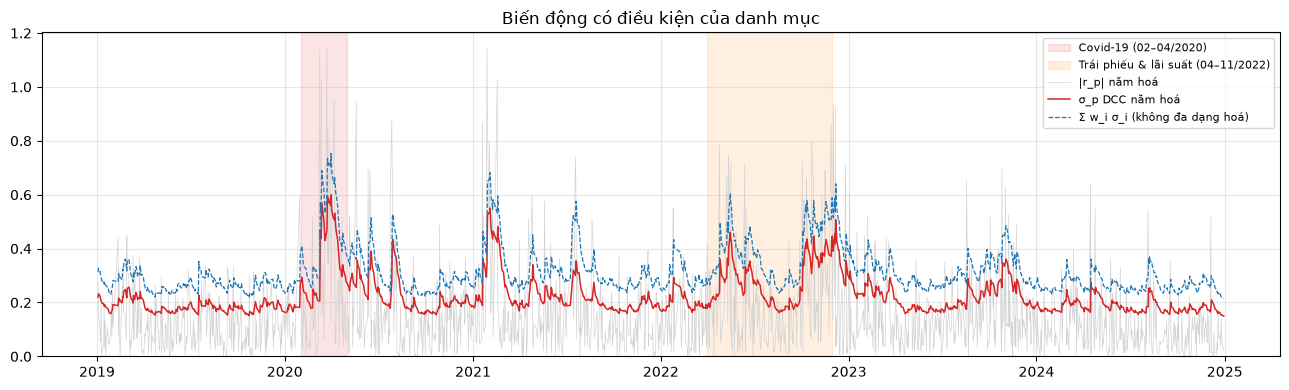

In [25]:
# ===================== 4.1 BIẾN ĐỘNG DANH MỤC =====================
WEIGHTS = pd.Series(1 / N, index=tickers)             # Equal weight; muốn theo vốn hoá thì gán Series khác, tổng = 1
assert np.isclose(WEIGHTS.sum(), 1), "Tổng tỷ trọng phải bằng 1"
w = WEIGHTS.values
r_p = pd.Series(log_ret.values @ w, index=log_ret.index, name="r_p")
sigma_p = pd.Series(np.sqrt(np.einsum("i,tij,j->t", w, H_t, w)), index=log_ret.index, name="sigma_p")
undiv = pd.Series(S @ w, index=log_ret.index)          # σ danh mục nếu mọi tương quan = 1
div_benefit = 1 - sigma_p / undiv
print("Tỷ trọng:", WEIGHTS.round(3).to_dict())
print(f"σ_p trung bình năm hoá: {sigma_p.mean() * np.sqrt(TRADING_DAYS):.2%} | lợi ích đa dạng hoá TB: {div_benefit.mean():.1%}")

fig, ax = plt.subplots(figsize=(13, 4))
shade_stress(ax)
ax.plot(r_p.index, r_p.abs() * np.sqrt(TRADING_DAYS), color="lightgrey", lw=0.5, label="|r_p| năm hoá")
ax.plot(sigma_p.index, sigma_p * np.sqrt(TRADING_DAYS), color="tab:red", lw=1.1, label="σ_p DCC năm hoá")
ax.plot(undiv.index, undiv * np.sqrt(TRADING_DAYS), color="tab:blue", lw=0.9, ls="--", label="Σ w_i σ_i (không đa dạng hoá)")
ax.set_title("Biến động có điều kiện của danh mục"); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_ylim(0, None)
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_portfolio_volatility.png", dpi=150); plt.show()

## 4.2 VaR & ES 1 ngày: Normal, Student-t, Historical Simulation
**Tầng 1** (quy ước VaR, ES là **tổn thất dương**, lợi suất danh mục trung bình = 0; α = 5% hoặc 1%):
- Normal: $VaR_{\alpha,t} = z_{1-\alpha}\,\sigma_{p,t}$; $ES_{\alpha,t} = \sigma_{p,t}\,\dfrac{\phi(z_{1-\alpha})}{\alpha}$.
- Student-t chuẩn hoá (phương sai 1, ν ước lượng bằng MLE trên $z_{p,t} = r_{p,t}/\sigma_{p,t}$), $c = \sqrt{(\nu-2)/\nu}$, $q = t_\nu^{-1}(1-\alpha)$:
  $VaR = c\,q\,\sigma_{p,t}$; $ES = c\,\sigma_{p,t}\,\dfrac{f_\nu(q)}{\alpha}\cdot\dfrac{\nu + q^2}{\nu - 1}$.
- Historical Simulation: VaR = phân vị α của 250 lợi suất danh mục **trước** ngày t (đổi dấu); ES = trung bình các khoản lỗ vượt VaR trong cửa sổ.

**Tầng 2:** Output `var_es` (DataFrame theo ngày: σ_p, r_p, VaR_*, ES_*). Cửa sổ backtest bắt đầu sau 250 phiên đầu (để HS có đủ dữ liệu)
nên cả 3 phương pháp được so sánh trên cùng các ngày. **Lưu ý:** tham số GARCH/DCC ước lượng trên toàn mẫu (in-sample) ⇒ backtest này
kiểm tra độ phù hợp của mô hình; dự báo ngoài mẫu thật (ước lượng lại theo cửa sổ trượt) nằm ở mục 4.5.

**Tầng 3:** ES luôn > VaR cùng mức tin cậy. Ở 99%, VaR-t > VaR-Normal (đuôi dày); ở 95% có thể ngược lại vì t chuẩn hoá "nhọn" hơn ở giữa.

In [26]:
# ===================== 4.2a ƯỚC LƯỢNG ν CHO STUDENT-t =====================
z_p = (r_p / sigma_p).values


def std_t_nll(nu, x):
    """−log-likelihood của Student-t chuẩn hoá (phương sai 1)."""
    c = np.sqrt((nu - 2) / nu)
    return -np.sum(stats.t.logpdf(x / c, nu) - np.log(c))


nu_p = minimize(lambda v: std_t_nll(v[0], z_p), [6.0], bounds=[(2.05, 100)], method="L-BFGS-B").x[0]
print(f"Phần dư danh mục z_p: std = {z_p.std():.3f}, kurtosis = {stats.kurtosis(z_p, fisher=False):.2f} -> ν ước lượng = {nu_p:.2f}")

Phần dư danh mục z_p: std = 0.925, kurtosis = 5.48 -> ν ước lượng = 4.21


Cửa sổ backtest: 2020-01-16 -> 2024-12-30 (1202 phiên)


,Trung bình (%)
VaR_Normal_95,2.413
ES_Normal_95,3.026
VaR_t_95,2.234
ES_t_95,3.316
VaR_HS_95,2.414
ES_HS_95,3.661
VaR_Normal_99,3.413
ES_Normal_99,3.910
VaR_t_99,3.875
ES_t_99,5.326


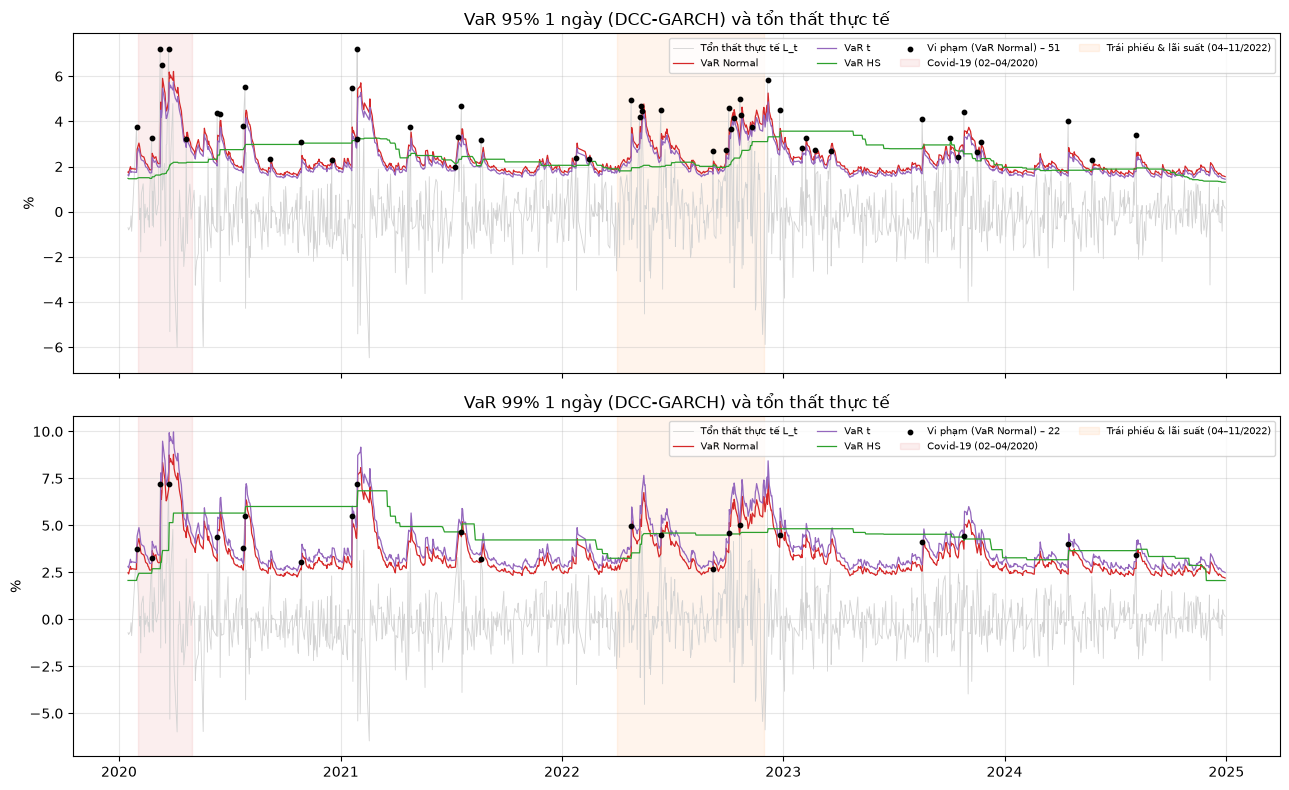

In [27]:
# ===================== 4.2b TÍNH VaR / ES =====================
def var_es_normal(sig, a):
    z = stats.norm.ppf(1 - a)
    return z * sig, sig * stats.norm.pdf(z) / a


def var_es_t(sig, a, nu):
    c = np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(1 - a, nu)
    return c * q * sig, c * sig * stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1)


def var_es_hs(r, a, window):
    """HS: dùng window lợi suất TRƯỚC ngày t (không nhìn trước)."""
    var, es = np.full(len(r), np.nan), np.full(len(r), np.nan)
    x = r.values
    for t in range(window, len(x)):
        hist = x[t - window:t]
        q = np.quantile(hist, a)
        var[t], es[t] = -q, -hist[hist <= q].mean()
    return var, es


var_es = pd.DataFrame({"r_p": r_p, "loss": -r_p, "sigma_p": sigma_p})
for cl in VAR_LEVELS:
    a = 1 - cl
    tag = f"{int(cl * 100)}"
    var_es[f"VaR_Normal_{tag}"], var_es[f"ES_Normal_{tag}"] = var_es_normal(sigma_p.values, a)
    var_es[f"VaR_t_{tag}"], var_es[f"ES_t_{tag}"] = var_es_t(sigma_p.values, a, nu_p)
    var_es[f"VaR_HS_{tag}"], var_es[f"ES_HS_{tag}"] = var_es_hs(r_p, a, HS_WINDOW)
bt = var_es.iloc[HS_WINDOW:].copy()                    # cửa sổ backtest chung cho 3 phương pháp
print(f"Cửa sổ backtest: {bt.index.min().date()} -> {bt.index.max().date()} ({len(bt)} phiên)")
display((bt.filter(regex="^(VaR|ES)").mean() * 100).round(3).to_frame("Trung bình (%)"))

METHODS = ["Normal", "t", "HS"]
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, cl in zip(axes, VAR_LEVELS):
    tag = f"{int(cl * 100)}"
    loss = -bt["r_p"]
    ax.plot(bt.index, loss * 100, color="lightgrey", lw=0.6, label="Tổn thất thực tế L_t")
    for m, c in zip(METHODS, ["tab:red", "tab:purple", "tab:green"]):
        ax.plot(bt.index, bt[f"VaR_{m}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {m}")
    br = loss > bt[f"VaR_{VIOL_MODEL}_{tag}"]                        # mô hình đánh dấu vi phạm: VIOL_MODEL (ô 0.2)
    ax.scatter(bt.index[br], loss[br] * 100, color="black", s=10, zorder=3, label=f"Vi phạm (VaR {VIOL_MODEL}) – {int(br.sum())}")
    shade_stress(ax, alpha=0.08)
    ax.set_title(f"VaR {tag}% 1 ngày (DCC-GARCH) và tổn thất thực tế"); ax.set_ylabel("%"); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_var_backtest.png", dpi=150, bbox_inches="tight"); plt.show()


## 4.3 Kiểm định ngược (Backtesting)
**Tầng 1:**
- Vi phạm: $I_t = 1$ nếu tổn thất $-r_{p,t} > VaR_t$. Kỳ vọng $n\alpha$ lần.
- **Kupiec POF** ($H_0$: tỷ lệ vi phạm $p = \alpha$): $LR_{uc} = -2\ln\dfrac{(1-\alpha)^{n-x}\alpha^x}{(1-\hat p)^{n-x}\hat p^x} \sim \chi^2(1)$.
- **Christoffersen** ($H_0$: vi phạm độc lập): $LR_{ind} = -2\ln\dfrac{(1-\pi)^{n_{00}+n_{10}}\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\pi_{01}^{n_{01}}(1-\pi_{11})^{n_{10}}\pi_{11}^{n_{11}}} \sim \chi^2(1)$;
  kết hợp $LR_{cc} = LR_{uc} + LR_{ind} \sim \chi^2(2)$.
- **Basel Traffic Light** (VaR 99%, 250 phiên gần nhất): Xanh 0–4, Vàng 5–9, Đỏ ≥ 10 vi phạm; hệ số nhân vốn k = 3 + plus factor.
  Với toàn bộ cửa sổ, vùng được xác định theo xác suất nhị thức tích luỹ (Xanh < 95%, Vàng < 99,99%, Đỏ còn lại) – tương ứng ngưỡng Basel.
- Kiểm tra ES: so sánh tổn thất thực tế trung bình trong các ngày vi phạm với ES dự báo trung bình những ngày đó.

**Tầng 3:** tỷ lệ vi phạm > α và Kupiec p < 0,05 ⇒ **đánh giá thấp** rủi ro; tỷ lệ < α và p < 0,05 ⇒ **thổi phồng** rủi ro (giữ vốn thừa).
Christoffersen p < 0,05 ⇒ vi phạm **thành cụm**: mô hình phản ứng chậm khi biến động tăng đột ngột.

In [28]:
# ===================== 4.3 CÁC HÀM KIỂM ĐỊNH =====================
def _xlogy(x, y):
    return 0.0 if x == 0 else x * np.log(y)


def kupiec_pof(hits, a):
    n, x = len(hits), int(hits.sum())
    p_hat = x / n
    ll0 = _xlogy(n - x, 1 - a) + _xlogy(x, a)
    ll1 = _xlogy(n - x, 1 - p_hat) + _xlogy(x, p_hat)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1)


def christoffersen_ind(hits):
    h = np.asarray(hits, int)
    prev, cur = h[:-1], h[1:]
    n00 = int(((prev == 0) & (cur == 0)).sum()); n01 = int(((prev == 0) & (cur == 1)).sum())
    n10 = int(((prev == 1) & (cur == 0)).sum()); n11 = int(((prev == 1) & (cur == 1)).sum())
    pi01 = n01 / max(n00 + n01, 1); pi11 = n11 / max(n10 + n11, 1)
    pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    ll0 = _xlogy(n00 + n10, 1 - pi) + _xlogy(n01 + n11, pi)
    ll1 = _xlogy(n00, 1 - pi01) + _xlogy(n01, pi01) + _xlogy(n10, 1 - pi11) + _xlogy(n11, pi11)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1), n11


def binomial_zone(x, n, a):
    cdf = stats.binom.cdf(x, n, a)                              # P(X ≤ x): trùng bảng Basel 0–4 / 5–9 / ≥10 khi n = 250, α = 1%
    return "Xanh" if cdf < 0.95 else ("Vàng" if cdf < 0.9999 else "Đỏ")


BASEL_PLUS = {5: 0.40, 6: 0.50, 7: 0.65, 8: 0.75, 9: 0.85}

rows = []
for cl in VAR_LEVELS:
    a = 1 - cl
    tag = f"{int(cl * 100)}"
    for m in METHODS:
        loss = -bt["r_p"]
        hits = (loss > bt[f"VaR_{m}_{tag}"]).astype(int).values
        n, x = len(hits), int(hits.sum())
        lr_uc, p_uc = kupiec_pof(hits, a)
        lr_ind, p_ind, n11 = christoffersen_ind(hits)
        lr_cc = lr_uc + lr_ind
        hit_days = hits.astype(bool)
        rows.append({"Mức tin cậy": f"{tag}%", "Phương pháp": m, "Số ngày": n, "Vi phạm": x,
                     "Kỳ vọng": round(n * a, 1), "Tỷ lệ vi phạm (%)": 100 * x / n,
                     "Kupiec LR": lr_uc, "Kupiec p": p_uc, "Christoffersen LR": lr_ind, "Christoffersen p": p_ind,
                     "Vi phạm liên tiếp (n11)": n11, "LR_cc": lr_cc, "LR_cc p": stats.chi2.sf(lr_cc, 2),
                     "Vùng (nhị thức)": binomial_zone(x, n, a),
                     "Lỗ TB ngày vi phạm (%)": 100 * loss[hit_days].mean() if x else np.nan,
                     "ES dự báo TB ngày vi phạm (%)": 100 * bt[f"ES_{m}_{tag}"][hit_days].mean() if x else np.nan})
bt_table = pd.DataFrame(rows)


def verdict(row, a):
    over = row["Tỷ lệ vi phạm (%)"] > 100 * a
    s = ("ĐÁNH GIÁ THẤP rủi ro" if over else "THỔI PHỒNG rủi ro") if row["Kupiec p"] < ALPHA else "Tỷ lệ vi phạm phù hợp"
    s += "; vi phạm THÀNH CỤM" if row["Christoffersen p"] < ALPHA else "; vi phạm độc lập"
    return s


bt_table["Kết luận"] = [verdict(r, 1 - float(r["Mức tin cậy"][:-1]) / 100) for _, r in bt_table.iterrows()]
display(bt_table.round(4))

# Basel Traffic Light chuẩn: VaR 99%, 250 phiên cuối
last = bt.iloc[-250:]
basel_rows = []
for m in METHODS:
    x = int((-last["r_p"] > last[f"VaR_{m}_99"]).sum())
    zone = "Xanh" if x <= 4 else ("Vàng" if x <= 9 else "Đỏ")
    plus = 0.0 if x <= 4 else BASEL_PLUS.get(x, 1.0)
    basel_rows.append({"Phương pháp": m, "Cửa sổ": f"{last.index.min().date()} -> {last.index.max().date()}",
                       "Vi phạm VaR99 (250 phiên)": x, "Vùng Basel": zone, "Plus factor": plus, "Hệ số nhân vốn k": 3 + plus})
basel_table = pd.DataFrame(basel_rows)
display(basel_table)

,Mức tin cậy,Phương pháp,Số ngày,Vi phạm,Kỳ vọng,Tỷ lệ vi phạm (%),Kupiec LR,Kupiec p,Christoffersen LR,Christoffersen p,Vi phạm liên tiếp (n11),LR_cc,LR_cc p,Vùng (nhị thức),Lỗ TB ngày vi phạm (%),ES dự báo TB ngày vi phạm (%),Kết luận
0,95%,Normal,1202,51,60.1,4.2429,1.5255,0.2168,3.0412,0.0812,5,4.5667,0.1019,Xanh,3.9147,3.3830,Tỷ lệ vi phạm phù hợp; vi phạm độc lập
1,95%,t,1202,61,60.1,5.0749,0.0141,0.9054,6.2507,0.0124,8,6.2648,0.0436,Xanh,3.6089,3.5832,Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM
2,95%,HS,1202,63,60.1,5.2413,0.1451,0.7033,23.2231,0.0000,14,23.3682,0.0000,Xanh,3.7248,3.5545,Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM
3,99%,Normal,1202,22,12.0,1.8303,6.7206,0.0095,0.6573,0.4175,1,7.3779,0.0250,Vàng,4.5890,3.9390,ĐÁNH GIÁ THẤP rủi ro; vi phạm độc lập
4,99%,t,1202,17,12.0,1.4143,1.8467,0.1742,1.4006,0.2366,1,3.2473,0.1972,Xanh,4.5983,4.9818,Tỷ lệ vi phạm phù hợp; vi phạm độc lập
5,99%,HS,1202,18,12.0,1.4975,2.6069,0.1064,9.8863,0.0017,3,12.4932,0.0019,Vàng,4.8950,4.4994,Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM


,Phương pháp,Cửa sổ,Vi phạm VaR99 (250 phiên),Vùng Basel,Plus factor,Hệ số nhân vốn k
0,Normal,2023-12-26 -> 2024-12-30,2,Xanh,0.0,3.0
1,t,2023-12-26 -> 2024-12-30,2,Xanh,0.0,3.0
2,HS,2023-12-26 -> 2024-12-30,1,Xanh,0.0,3.0


In [29]:
# ===================== 4.3b VI PHẠM THEO NĂM / GIAI ĐOẠN =====================
hits_df = pd.DataFrame({f"{m}_{int(cl * 100)}": (-bt["r_p"] > bt[f"VaR_{m}_{int(cl * 100)}"]).astype(int)
                        for cl in VAR_LEVELS for m in METHODS}, index=bt.index)
by_year = hits_df.groupby(hits_df.index.year).sum()
by_year["Số phiên"] = hits_df.groupby(hits_df.index.year).size()
print("Số lần vi phạm theo năm:"); display(by_year)
bt_masks = period_masks(bt.index)
rate_period = pd.DataFrame({name: hits_df[m].mean() * 100 for name, m in bt_masks.items() if m.any()}).T
rate_period["Số phiên"] = [int(m.sum()) for name, m in bt_masks.items() if m.any()]
print("Tỷ lệ vi phạm theo giai đoạn (%, kỳ vọng 5% / 1%):"); display(rate_period.round(2))

with pd.ExcelWriter(OUT["TV4"] / "TV4_var_backtest.xlsx", engine="openpyxl") as xw:
    bt_table.to_excel(xw, sheet_name="Backtest", index=False)
    basel_table.to_excel(xw, sheet_name="Basel_250", index=False)
    (bt.filter(regex="^(VaR|ES)").mean() * 100).to_frame("Trung bình (%)").to_excel(xw, sheet_name="VaR_ES_TB")
    by_year.to_excel(xw, sheet_name="Vi_pham_theo_nam")
    rate_period.to_excel(xw, sheet_name="Vi_pham_theo_giai_doan")
    var_es.to_excel(xw, sheet_name="VaR_ES_hang_ngay")
print("✔ Đã lưu kết quả TV4 vào", OUT["TV4"])

Số lần vi phạm theo năm:


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99,Số phiên
Date,,,,,,,
2020,13,14,22,8,7,7,234
2021,8,12,10,4,2,2,229
2022,17,19,22,6,4,7,246
2023,10,11,5,2,2,1,247
2024,3,5,4,2,2,1,246


Tỷ lệ vi phạm theo giai đoạn (%, kỳ vọng 5% / 1%):


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99,Số phiên
Bình thường,3.39,4.41,3.18,1.44,1.23,0.72,974
Covid-19 (02–04/2020),8.20,8.20,22.95,4.92,3.28,8.20,61
Trái phiếu & lãi suất (04–11/2022),7.78,7.78,10.78,2.99,1.80,3.59,167


✔ Đã lưu kết quả TV4 vào D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput\TV4_VaR_Backtest


## 4.4 Diễn giải cốt lõi – DCC-GARCH có đo lường đúng rủi ro danh mục?

In [30]:
# ===================== 4.4 DIỄN GIẢI TỰ ĐỘNG =====================
for _, r in bt_table.iterrows():
    print(f"VaR {r['Mức tin cậy']} – {r['Phương pháp']:<6}: {r['Vi phạm']} vi phạm / kỳ vọng {r['Kỳ vọng']} "
          f"({r['Tỷ lệ vi phạm (%)']:.2f}%) | Kupiec p = {r['Kupiec p']:.3f}, Christoffersen p = {r['Christoffersen p']:.3f} "
          f"| vùng {r['Vùng (nhị thức)']} -> {r['Kết luận']}")
worst = rate_period.drop(columns="Số phiên").drop(index="Bình thường", errors="ignore")
if len(worst):
    nrm = rate_period.loc["Bình thường"].drop("Số phiên")
    for name, row in worst.iterrows():
        v99, v95 = f"{VIOL_MODEL}_99", f"{VIOL_MODEL}_95"
        print(f"\n{name}: tỷ lệ vi phạm VaR-{VIOL_MODEL} 99% = {row[v99]:.2f}% (bình thường {nrm[v99]:.2f}%), "
              f"VaR-{VIOL_MODEL} 95% = {row[v95]:.2f}% (bình thường {nrm[v95]:.2f}%)"
              + (" -> mô hình phản ứng trễ khi cú sốc xảy ra đột ngột, vi phạm dồn vào giai đoạn khủng hoảng."
                 if row[v99] > nrm[v99] else "."))

print("\nKiểm tra ES (lỗ thực tế TB trong các ngày vi phạm so với ES dự báo TB những ngày đó):")
for _, r in bt_table.iterrows():
    if r["Vi phạm"]:
        ratio = r["Lỗ TB ngày vi phạm (%)"] / r["ES dự báo TB ngày vi phạm (%)"]       # > 1: lỗ thực tế lớn hơn ES dự báo
        verdict_es = ("ES đủ bao phủ tổn thất đuôi" if ratio <= 1 else
                      "xấp xỉ (lệch < 5%)" if ratio <= 1.05 else "ES ĐÁNH GIÁ THẤP tổn thất đuôi")
        print(f"  ES {r['Mức tin cậy']} – {r['Phương pháp']:<6}: lỗ thực tế {r['Lỗ TB ngày vi phạm (%)']:.2f}% vs ES "
              f"{r['ES dự báo TB ngày vi phạm (%)']:.2f}% (tỷ lệ {ratio:.2f}) -> {verdict_es}")
print("\nLưu ý: tham số GARCH/DCC ước lượng trên TOÀN MẪU (in-sample) nên backtest trên lạc quan hơn thực tế; "
      "kết quả ngoài mẫu (ước lượng lại theo cửa sổ trượt) nằm ở mục 4.5.")

VaR 95% – Normal: 51 vi phạm / kỳ vọng 60.1 (4.24%) | Kupiec p = 0.217, Christoffersen p = 0.081 | vùng Xanh -> Tỷ lệ vi phạm phù hợp; vi phạm độc lập
VaR 95% – t     : 61 vi phạm / kỳ vọng 60.1 (5.07%) | Kupiec p = 0.905, Christoffersen p = 0.012 | vùng Xanh -> Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM
VaR 95% – HS    : 63 vi phạm / kỳ vọng 60.1 (5.24%) | Kupiec p = 0.703, Christoffersen p = 0.000 | vùng Xanh -> Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM
VaR 99% – Normal: 22 vi phạm / kỳ vọng 12.0 (1.83%) | Kupiec p = 0.010, Christoffersen p = 0.418 | vùng Vàng -> ĐÁNH GIÁ THẤP rủi ro; vi phạm độc lập
VaR 99% – t     : 17 vi phạm / kỳ vọng 12.0 (1.41%) | Kupiec p = 0.174, Christoffersen p = 0.237 | vùng Xanh -> Tỷ lệ vi phạm phù hợp; vi phạm độc lập
VaR 99% – HS    : 18 vi phạm / kỳ vọng 12.0 (1.50%) | Kupiec p = 0.106, Christoffersen p = 0.002 | vùng Vàng -> Tỷ lệ vi phạm phù hợp; vi phạm THÀNH CỤM

Covid-19 (02–04/2020): tỷ lệ vi phạm VaR-Normal 99% = 4.92% (bình thường 1.44%), VaR-Nor

## 4.5 Dự báo rủi ro danh mục ngoài mẫu (Out-of-sample)
**Tầng 1 – Vì sao cần?** Ở mục 4.2–4.4, tham số GARCH/DCC được ước lượng trên **toàn mẫu** rồi mới backtest ⇒ mô hình đã "nhìn thấy" chính những ngày đem ra kiểm định.
Đề bài yêu cầu so sánh ít nhất 2 mô hình **ngoài mẫu**. Quy trình:
1. Kiểm định trên `N_TEST` ngày cuối. Cứ mỗi `REFIT` ngày, **ước lượng lại** toàn bộ mô hình trên `WINDOW` ngày gần nhất.
2. Giữa hai lần ước lượng, giữ nguyên tham số và lọc tiếp $\sigma_{i,t}$, $Q_t$ ⇒ $H_t$ chỉ dùng thông tin đến $t-1$.
3. So sánh 5 phương pháp trên **cùng** các ngày kiểm định:

| Phương pháp | Biến động | Tương quan | Phân phối |
|---|---|---|---|
| **DCC-N** | GARCH biên (mô hình chọn ở TV2) | DCC(1,1) – thay đổi theo ngày | Normal |
| **DCC-t** | như trên | như trên | Student-t (ν ước lượng trong cửa sổ) |
| **CCC-N** | GARCH biên | Hằng số $\bar R$ của cửa sổ | Normal |
| **EWMA-N** | RiskMetrics λ = 0,94 cho cả ma trận hiệp phương sai | | Normal |
| **HS** | Phân vị lịch sử 250 ngày | | Không giả định |

4. **Đánh giá:** Kupiec, Christoffersen, Basel (như mục 4.3) + **hàm mất mát phân vị (quantile/tick loss)** để xếp hạng:
$QL_t = (\alpha - I_t)\,(r_{p,t} + VaR_t)$, với $I_t = 1\{r_{p,t} < -VaR_t\}$. QL trung bình càng nhỏ càng tốt; nó phạt cả vi phạm (VaR quá thấp) lẫn VaR quá cao (giữ vốn thừa).

**Tầng 2:** `fit_margin` (MLE GARCH/GJR – cùng công thức mục 2.1), `fit_dcc` (QMLE bước 2 – cùng công thức mục 3.1), `rolling_portfolio_forecast` trả về $H_t$ DCC, $H_t$ CCC, ν cho từng ngày kiểm định.
Mô hình biên mỗi mã lấy từ `selected`/`best_name` của TV2 (không đọc lại file). Output: `oos_var_es.csv`, `oos_backtest.csv`, `TV4_out_of_sample.xlsx`, `4_oos_var_vs_loss.png`.

**Tầng 3:** Mô hình tốt: tỷ lệ vi phạm ≈ α, Kupiec & Christoffersen p > 0,05, vùng Basel Xanh, QL nhỏ nhất. DCC thắng CCC ⇒ tương quan động **có giá trị dự báo** rủi ro danh mục, không chỉ khớp trong mẫu.
Vi phạm trên hình được đánh dấu theo `VIOL_MODEL` (ô cấu hình 0.2) – cùng mô hình với hình trong mẫu ở mục 4.2.

In [31]:
# ===================== 4.5.1 CẤU HÌNH & HÀM ƯỚC LƯỢNG (cùng công thức TV2/TV3) =====================
import time
from scipy import optimize

N_TEST = 500                                    # số ngày kiểm định
REFIT = 20                                      # ước lượng lại mỗi 20 phiên
WINDOW = min(1000, len(log_ret) - N_TEST)       # cửa sổ ước lượng (tự thu nhỏ nếu mẫu ngắn)
LAMBDA_EWMA = 0.94

SPEC = {tk: dict(SPECS[best_name[tk]]) for tk in tickers}     # mô hình biên đã chọn ở TV2 (gjr, dist)
print(f"Rolling: WINDOW = {WINDOW}, REFIT = {REFIT}, N_TEST = {N_TEST} "
      f"({log_ret.index[-N_TEST].date()} -> {log_ret.index[-1].date()})")
print("Mô hình biên (từ TV2):", best_name.to_dict())


def g_filter(x, r, gjr, bc):
    """σ²_t của GARCH/GJR với tham số x = [mu, omega, alpha, (gamma), beta, (nu)], σ²_0 từ backcast bc."""
    mu, om, al = x[0], x[1], x[2]
    ga = x[3] if gjr else 0.0
    be = x[4] if gjr else x[3]
    e = r - mu
    z = np.empty_like(e)
    z[0] = om + (al + 0.5 * ga) * bc + be * bc
    z[1:] = om + (al + ga * (e[:-1] < 0)) * e[:-1] ** 2
    return lfilter([1.0], [1.0, -be], z), e


def g_negll(x, r, gjr, dist):
    s2, e = g_filter(x, r, gjr, np.mean((r - x[0]) ** 2))
    s2 = np.maximum(s2, 1e-12)
    if dist == "normal":
        return 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2) + e ** 2 / s2)
    nu = x[-1]
    return -np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
                   - 0.5 * np.log(s2) - (nu + 1) / 2 * np.log1p(e ** 2 / (s2 * (nu - 2))))


def fit_margin(r, gjr, dist, x0=None):
    """MLE GARCH/GJR (giống fit_garch ở 2.1, bỏ phần sai số chuẩn cho nhanh). Trả về vector tham số."""
    v = r.var()
    bnds = [(-np.inf, np.inf), (1e-8, 10 * v), (0, 1)] + ([(-1, 1)] if gjr else []) + [(0, 1)] + ([(2.05, 200)] if dist == "t" else [])
    ib = 4 if gjr else 3
    cons = [{"type": "ineq", "fun": lambda p: 0.99999 - (p[2] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})
    starts = [x0] if x0 is not None else []
    starts += [[r.mean(), v * 0.05, 0.05] + ([0.05] if gjr else []) + [0.90] + ([8.0] if dist == "t" else [])]
    best = None
    for s in starts:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            o = optimize.minimize(g_negll, s, args=(r, gjr, dist), method="SLSQP", bounds=bnds, constraints=cons,
                                  options={"maxiter": 500, "ftol": 1e-9})
        if np.isfinite(o.fun) and (best is None or o.fun < best.fun):
            best = o
    return best.x


def dcc_Q_path(a, b, e, Qbar):
    """Q_t, R_t (t = 0..T-1) với Q_0 = Q̄; R_t dùng ε đến t-1."""
    T_, N_ = e.shape
    Q = np.empty((T_, N_, N_)); Q[0] = Qbar
    for t in range(1, T_):
        Q[t] = (1 - a - b) * Qbar + a * np.outer(e[t - 1], e[t - 1]) + b * Q[t - 1]
    d = 1 / np.sqrt(np.einsum("tii->ti", Q))
    return Q * d[:, :, None] * d[:, None, :]


def fit_dcc(e, x0=(0.02, 0.95)):
    Qbar_w = e.T @ e / len(e)

    def nll(th):
        a, b = th
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        R = dcc_Q_path(a, b, e, Qbar_w)
        _, logdet = np.linalg.slogdet(R)
        quad = np.einsum("ti,ti->t", e, np.linalg.solve(R, e[:, :, None])[:, :, 0])
        return 0.5 * np.sum(logdet + quad - np.einsum("ti,ti->t", e, e))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        o = optimize.minimize(nll, x0, method="SLSQP", bounds=[(0, 0.5), (0, 0.9999)],
                              constraints=[{"type": "ineq", "fun": lambda th: 0.9999 - th[0] - th[1]}])
    return o.x, Qbar_w

Rolling: WINDOW = 952, REFIT = 20, N_TEST = 500 (2022-12-22 -> 2024-12-30)
Mô hình biên (từ TV2): {'FPT': 'GJR-GARCH-t', 'HPG': 'GJR-GARCH-t', 'MWG': 'GJR-GARCH-t', 'VCB': 'GARCH-t', 'VHM': 'GARCH-t'}


In [32]:
# ===================== 4.5.2 VÒNG LẶP ROLLING: ƯỚC LƯỢNG LẠI GARCH + DCC MỖI REFIT NGÀY =====================
def rolling_portfolio_forecast(r):
    """r: T × N lợi suất (thập phân). Trả về H_dcc, H_ccc (N_TEST × N × N), nu_t (N_TEST), bảng tham số mỗi lần refit."""
    T_, N_ = r.shape
    first = T_ - N_TEST
    H_dcc = np.empty((N_TEST, N_, N_)); H_ccc = np.empty((N_TEST, N_, N_)); nu_t = np.empty(N_TEST)
    log_rows, prev = [], {}
    for start in range(first, T_, REFIT):
        end = min(start + REFIT, T_)
        seg = r[start - WINDOW:end] * SCALE                 # cửa sổ ước lượng + các ngày cần dự báo
        win = seg[:WINDOW]
        sig = np.empty_like(seg); eps = np.empty_like(seg)
        for i, tk in enumerate(tickers):                    # Bước 1: GARCH biên từng mã
            x = fit_margin(win[:, i], **SPEC[tk], x0=prev.get(tk))
            prev[tk] = x
            s2, e = g_filter(x, seg[:, i], SPEC[tk]["gjr"], np.mean((win[:, i] - x[0]) ** 2))
            sig[:, i] = np.sqrt(s2); eps[:, i] = e / sig[:, i]
        (a, b), Qbar_w = fit_dcc(eps[:WINDOW], x0=prev.get("dcc", (0.02, 0.95)))   # Bước 2: DCC
        prev["dcc"] = (a, b)
        R = dcc_Q_path(a, b, eps, Qbar_w)                   # lọc Q_t qua cả cửa sổ + ngày dự báo
        Rbar = np.corrcoef(eps[:WINDOW].T)
        Hd = sig[:, :, None] * R * sig[:, None, :] / SCALE ** 2          # về đơn vị thập phân
        Hc = sig[:, :, None] * Rbar[None] * sig[:, None, :] / SCALE ** 2
        # ν cho DCC-t: MLE trên z_p = r_p / σ_p trong CỬA SỔ ƯỚC LƯỢNG (không dùng ngày kiểm định)
        sp_win = np.sqrt(np.einsum("i,tij,j->t", w, Hd[:WINDOW], w))
        zp = (r[start - WINDOW:start] @ w) / sp_win
        nu = optimize.minimize_scalar(std_t_nll, bounds=(2.1, 200), args=(zp,), method="bounded").x
        k = slice(start - first, end - first)
        H_dcc[k], H_ccc[k], nu_t[k] = Hd[WINDOW:], Hc[WINDOW:], nu
        log_rows.append({"Refit từ": log_ret.index[start].date(), "a": a, "b": b, "a+b": a + b, "nu_p": nu})
    return H_dcc, H_ccc, nu_t, pd.DataFrame(log_rows)


t0 = time.time()
H_dcc_oos, H_ccc_oos, nu_oos, refit_log = rolling_portfolio_forecast(log_ret.values)
print(f"✔ Xong {len(refit_log)} lần ước lượng lại trong {time.time() - t0:.0f}s")
display(refit_log.round(4))


# ===================== 4.5.3 EWMA COVARIANCE (RiskMetrics) =====================
def ewma_cov(r, lam=LAMBDA_EWMA):
    """S_t = λ S_{t-1} + (1-λ) r_{t-1} r_{t-1}'; khởi tạo bằng hiệp phương sai mẫu của cửa sổ đầu tiên."""
    T_, N_ = r.shape
    S_ = np.empty((T_, N_, N_))
    S_[0] = np.cov(r[:WINDOW].T)
    for t in range(1, T_):
        S_[t] = lam * S_[t - 1] + (1 - lam) * np.outer(r[t - 1], r[t - 1])
    return S_[-N_TEST:]


H_ewma_oos = ewma_cov(log_ret.values)

✔ Xong 25 lần ước lượng lại trong 13s


,Refit từ,a,b,a+b,nu_p
0,2022-12-22,0.0350,0.9063,0.9413,3.8817
1,2023-01-27,0.0356,0.9033,0.9389,3.8029
2,2023-02-24,0.0337,0.9077,0.9414,3.6750
3,2023-03-24,0.0358,0.9018,0.9375,3.7888
4,2023-04-21,0.0369,0.9019,0.9388,3.7813
5,2023-05-25,0.0381,0.9001,0.9382,3.7707
6,2023-06-23,0.0419,0.8889,0.9308,3.7102
7,2023-07-21,0.0379,0.8953,0.9332,3.8013
8,2023-08-18,0.0349,0.9077,0.9426,3.8402
9,2023-09-19,0.0448,0.8705,0.9152,3.7572


In [33]:
# ===================== 4.5.4 VaR / ES NGOÀI MẪU CHO 5 PHƯƠNG PHÁP =====================
test_idx = log_ret.index[-N_TEST:]
sp_oos = {name: pd.Series(np.sqrt(np.einsum("i,tij,j->t", w, Hm, w)), index=test_idx)
          for name, Hm in [("DCC", H_dcc_oos), ("CCC", H_ccc_oos), ("EWMA", H_ewma_oos)]}

oos = pd.DataFrame({"r_p": var_es.loc[test_idx, "r_p"], "loss": -var_es.loc[test_idx, "r_p"],
                    "sigma_DCC": sp_oos["DCC"], "sigma_CCC": sp_oos["CCC"], "sigma_EWMA": sp_oos["EWMA"], "nu_DCC": nu_oos})
OOS_METHODS = ["DCC-N", "DCC-t", "CCC-N", "EWMA-N", "HS"]
for cl in VAR_LEVELS:
    a_lvl = 1 - cl
    tag = f"{int(cl * 100)}"
    oos[f"VaR_DCC-N_{tag}"], oos[f"ES_DCC-N_{tag}"] = var_es_normal(sp_oos["DCC"], a_lvl)
    oos[f"VaR_DCC-t_{tag}"], oos[f"ES_DCC-t_{tag}"] = var_es_t(sp_oos["DCC"], a_lvl, nu_oos)
    oos[f"VaR_CCC-N_{tag}"], oos[f"ES_CCC-N_{tag}"] = var_es_normal(sp_oos["CCC"], a_lvl)
    oos[f"VaR_EWMA-N_{tag}"], oos[f"ES_EWMA-N_{tag}"] = var_es_normal(sp_oos["EWMA"], a_lvl)
    oos[f"VaR_HS_{tag}"], oos[f"ES_HS_{tag}"] = var_es.loc[test_idx, f"VaR_HS_{tag}"], var_es.loc[test_idx, f"ES_HS_{tag}"]
assert oos.notna().all().all(), "Còn NaN trong dự báo ngoài mẫu"
oos.index.name = "Date"
oos.to_csv(OUT["TV4"] / "oos_var_es.csv", encoding="utf-8-sig")

In [34]:
# ===================== 4.5.5 BACKTEST NGOÀI MẪU + QUANTILE LOSS =====================
def quantile_loss(r_p_, var_, a_):
    hit = (r_p_ < -var_).astype(float)
    return ((a_ - hit) * (r_p_ + var_)).mean()


oos_rows = []
for cl in VAR_LEVELS:
    tag, a_lvl = f"{int(cl * 100)}", 1 - cl
    for meth in OOS_METHODS:
        I = (oos["loss"] > oos[f"VaR_{meth}_{tag}"]).astype(int).values
        n_, x_ = len(I), int(I.sum())
        lr_uc, p_uc = kupiec_pof(I, a_lvl)
        lr_ind, p_ind, _ = christoffersen_ind(I)
        oos_rows.append({
            "Phương pháp": meth, "Mức tin cậy": f"{tag}%", "Số ngày": n_, "Vi phạm kỳ vọng": n_ * a_lvl,
            "Vi phạm thực tế": x_, "Tỷ lệ vi phạm (%)": 100 * x_ / n_,
            "Kupiec p": p_uc, "Christoffersen p": p_ind, "CC p": stats.chi2.sf(lr_uc + lr_ind, 2),
            "Basel (cả kỳ KĐ)": binomial_zone(x_, n_, a_lvl),
            "Vi phạm 250 ngày cuối": int(I[-BASEL_WINDOW:].sum()),
            "Quantile loss (x1e4)": quantile_loss(oos["r_p"], oos[f"VaR_{meth}_{tag}"], a_lvl) * 1e4,
            "VaR TB (%)": oos[f"VaR_{meth}_{tag}"].mean() * 100, "ES TB (%)": oos[f"ES_{meth}_{tag}"].mean() * 100,
            "Đánh giá": ("ĐÁNH GIÁ THẤP rủi ro" if (p_uc < ALPHA and x_ > n_ * a_lvl) else
                         "THỔI PHỒNG rủi ro" if (p_uc < ALPHA and x_ < n_ * a_lvl) else "Tần suất vi phạm phù hợp")
                        + ("; vi phạm THÀNH CỤM" if p_ind < ALPHA else "")})
oos_bt = pd.DataFrame(oos_rows)
m99 = oos_bt["Mức tin cậy"] == "99%"
oos_bt.loc[m99, "Basel (250 ngày cuối, VaR99)"] = ["Xanh" if v <= 4 else ("Vàng" if v <= 9 else "Đỏ")
                                                   for v in oos_bt.loc[m99, "Vi phạm 250 ngày cuối"]]
oos_bt["Basel (250 ngày cuối, VaR99)"] = oos_bt["Basel (250 ngày cuối, VaR99)"].fillna("")
oos_bt["Hạng QL"] = oos_bt.groupby("Mức tin cậy")["Quantile loss (x1e4)"].rank().astype(int)
display(oos_bt.round(4))
oos_bt.to_csv(OUT["TV4"] / "oos_backtest.csv", index=False, encoding="utf-8-sig")

for cl in VAR_LEVELS:
    sub = oos_bt[oos_bt["Mức tin cậy"] == f"{int(cl * 100)}%"].set_index("Phương pháp")
    print(f"VaR {int(cl * 100)}%: tốt nhất theo quantile loss = {sub['Quantile loss (x1e4)'].idxmin()} | "
          f"đạt cả Kupiec & Christoffersen: {', '.join(sub.index[(sub['Kupiec p'] >= ALPHA) & (sub['Christoffersen p'] >= ALPHA)]) or 'không có'}")


# ===================== 4.5.6 SO SÁNH TRONG MẪU vs NGOÀI MẪU (DCC) =====================
ins = bt_table.set_index(["Phương pháp", "Mức tin cậy"])
cmp_rows = []
for cl in VAR_LEVELS:
    tag = f"{int(cl * 100)}%"
    for m_in, m_out in [("Normal", "DCC-N"), ("t", "DCC-t"), ("HS", "HS")]:
        o = oos_bt[(oos_bt["Phương pháp"] == m_out) & (oos_bt["Mức tin cậy"] == tag)].iloc[0]
        cmp_rows.append({"Mức tin cậy": tag, "Phương pháp": m_out,
                         "Tỷ lệ vi phạm trong mẫu (%)": ins.loc[(m_in, tag), "Tỷ lệ vi phạm (%)"],
                         "Tỷ lệ vi phạm ngoài mẫu (%)": o["Tỷ lệ vi phạm (%)"],
                         "Kỳ vọng (%)": 100 * (1 - float(tag[:-1]) / 100)})
in_vs_out = pd.DataFrame(cmp_rows)
display(in_vs_out.round(2))
gap_in = (in_vs_out["Tỷ lệ vi phạm trong mẫu (%)"] - in_vs_out["Kỳ vọng (%)"]).abs().mean()
gap_out = (in_vs_out["Tỷ lệ vi phạm ngoài mẫu (%)"] - in_vs_out["Kỳ vọng (%)"]).abs().mean()
print(f"Sai lệch TB so với kỳ vọng: trong mẫu = {gap_in:.2f} điểm %, ngoài mẫu = {gap_out:.2f} điểm %")
print("=> Ngoài mẫu kém hơn: backtest trong mẫu đã lạc quan, nên lấy kết quả ngoài mẫu làm kết luận chính."
      if gap_out > gap_in + 0.25 else
      "=> Ngoài mẫu không kém hơn đáng kể: mô hình ổn định, kết quả trong mẫu không bị lạc quan quá mức.")

,Phương pháp,Mức tin cậy,Số ngày,Vi phạm kỳ vọng,Vi phạm thực tế,Tỷ lệ vi phạm (%),Kupiec p,Christoffersen p,CC p,Basel (cả kỳ KĐ),Vi phạm 250 ngày cuối,Quantile loss (x1e4),VaR TB (%),ES TB (%),Đánh giá,"Basel (250 ngày cuối, VaR99)",Hạng QL
0,DCC-N,95%,500,25.0,12,2.4,0.0031,0.4419,0.0094,Xanh,3,14.1217,2.2357,2.8036,THỔI PHỒNG rủi ro,nan,3
1,DCC-t,95%,500,25.0,14,2.8,0.0142,0.3686,0.0329,Xanh,3,13.7665,2.0567,3.0723,THỔI PHỒNG rủi ro,nan,2
2,CCC-N,95%,500,25.0,12,2.4,0.0031,0.4419,0.0094,Xanh,3,14.2095,2.2745,2.8523,THỔI PHỒNG rủi ro,nan,4
3,EWMA-N,95%,500,25.0,23,4.6,0.6776,0.1359,0.3017,Xanh,11,12.8817,1.8846,2.3634,Tần suất vi phạm phù hợp,nan,1
4,HS,95%,500,25.0,10,2.0,0.0005,0.5225,0.0019,Xanh,4,14.3932,2.4002,3.3582,THỔI PHỒNG rủi ro,nan,5
5,DCC-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Xanh,2,4.2233,3.1619,3.6225,Tần suất vi phạm phù hợp,Xanh,4
6,DCC-t,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Xanh,2,4.2320,3.5917,4.9753,Tần suất vi phạm phù hợp,Xanh,5
7,CCC-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Xanh,2,4.2039,3.2169,3.6855,Tần suất vi phạm phù hợp,Xanh,3
8,EWMA-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Xanh,2,4.1511,2.6655,3.0538,Tần suất vi phạm phù hợp,Xanh,1
9,HS,99%,500,5.0,2,0.4,0.1250,0.8990,0.3059,Xanh,1,4.2029,3.9106,4.5302,Tần suất vi phạm phù hợp,Xanh,2


VaR 95%: tốt nhất theo quantile loss = EWMA-N | đạt cả Kupiec & Christoffersen: EWMA-N
VaR 99%: tốt nhất theo quantile loss = EWMA-N | đạt cả Kupiec & Christoffersen: DCC-N, DCC-t, CCC-N, EWMA-N, HS


,Mức tin cậy,Phương pháp,Tỷ lệ vi phạm trong mẫu (%),Tỷ lệ vi phạm ngoài mẫu (%),Kỳ vọng (%)
0,95%,DCC-N,4.24,2.4,5.0
1,95%,DCC-t,5.07,2.8,5.0
2,95%,HS,5.24,2.0,5.0
3,99%,DCC-N,1.83,1.0,1.0
4,99%,DCC-t,1.41,1.0,1.0
5,99%,HS,1.50,0.4,1.0


Sai lệch TB so với kỳ vọng: trong mẫu = 0.47 điểm %, ngoài mẫu = 1.40 điểm %
=> Ngoài mẫu kém hơn: backtest trong mẫu đã lạc quan, nên lấy kết quả ngoài mẫu làm kết luận chính.


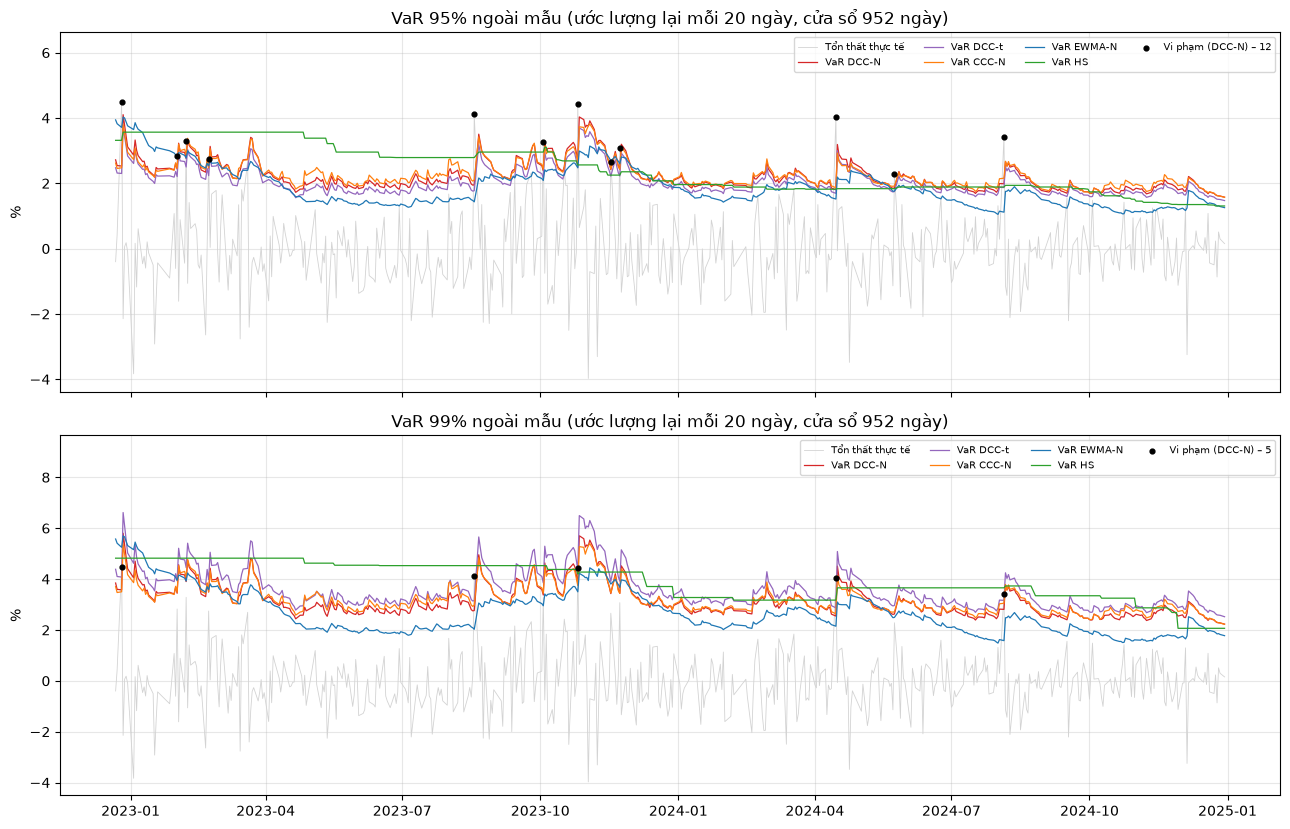

Lưu ý: cả hai giai đoạn khủng hoảng (Covid-19, Trái phiếu & lãi suất) đều nằm TRƯỚC cửa sổ ngoài mẫu (2022-12-22 → 2024-12-30) nên không tô trên hình; kết quả ngoài mẫu phản ánh giai đoạn thị trường tương đối bình thường. Muốn kiểm định cả khủng hoảng 2022 thì tăng N_TEST (ví dụ 700) – đổi lại cửa sổ ước lượng ngắn hơn.
✔ Đã lưu kết quả ngoài mẫu TV4 vào D:\Năm 3\Ứng dụng công nghệ trong TCNH\bản demo\ouput\TV4_VaR_Backtest


In [35]:
# ===================== 4.5.7 ĐỒ THỊ & LƯU KẾT QUẢ NGOÀI MẪU =====================
fig, axes = plt.subplots(len(VAR_LEVELS), 1, figsize=(13, 4.2 * len(VAR_LEVELS)), sharex=True)
for ax, cl in zip(np.atleast_1d(axes), VAR_LEVELS):
    tag = f"{int(cl * 100)}"
    ax.plot(test_idx, oos["loss"] * 100, color="lightgrey", lw=0.6, label="Tổn thất thực tế")
    for meth, c in zip(OOS_METHODS, ["tab:red", "tab:purple", "tab:orange", "tab:blue", "tab:green"]):
        ax.plot(test_idx, oos[f"VaR_{meth}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {meth}")
    br = oos["loss"] > oos[f"VaR_{VIOL_OOS}_{tag}"]
    ax.scatter(test_idx[br], oos["loss"][br] * 100, color="black", s=12, zorder=3, label=f"Vi phạm ({VIOL_OOS}) – {int(br.sum())}")
    shade_stress(ax, alpha=0.08, xlim=(test_idx[0], test_idx[-1]))      # chỉ tô giai đoạn nằm trong cửa sổ kiểm định
    ax.set_title(f"VaR {tag}% ngoài mẫu (ước lượng lại mỗi {REFIT} ngày, cửa sổ {WINDOW} ngày)")
    ax.set_ylabel("%"); ax.grid(alpha=0.3)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.35)                           # chừa chỗ cho chú thích
    ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_oos_var_vs_loss.png", dpi=150, bbox_inches="tight"); plt.show()
if not any(pd.Timestamp(e_) >= test_idx[0] for _, (s_, e_) in STRESS.items()):
    print(f"Lưu ý: cả hai giai đoạn khủng hoảng (Covid-19, Trái phiếu & lãi suất) đều nằm TRƯỚC cửa sổ ngoài mẫu "
          f"({test_idx[0].date()} → {test_idx[-1].date()}) nên không tô trên hình; kết quả ngoài mẫu phản ánh giai đoạn thị trường tương đối bình thường. "
          f"Muốn kiểm định cả khủng hoảng 2022 thì tăng N_TEST (ví dụ 700) – đổi lại cửa sổ ước lượng ngắn hơn.")

with pd.ExcelWriter(OUT["TV4"] / "TV4_out_of_sample.xlsx", engine="openpyxl") as xw:
    oos_bt.to_excel(xw, sheet_name="Backtest_ngoai_mau", index=False)
    in_vs_out.to_excel(xw, sheet_name="Trong_vs_ngoai_mau", index=False)
    refit_log.to_excel(xw, sheet_name="Tham_so_moi_lan_refit", index=False)
    oos.to_excel(xw, sheet_name="VaR_ES_ngoai_mau")
print("✔ Đã lưu kết quả ngoài mẫu TV4 vào", OUT["TV4"])

### 4.5b Diễn giải kết quả ngoài mẫu (gợi ý viết báo cáo)
- So sánh **DCC-N vs CCC-N**: cùng mô hình biên, chỉ khác tương quan động/hằng ⇒ chênh lệch vi phạm & quantile loss chính là **giá trị dự báo của DCC**.
- So sánh **DCC-N vs DCC-t**: tác động của giả định đuôi dày lên VaR 99%.
- So sánh với **EWMA** và **HS**: mô hình phức tạp có thực sự tốt hơn phương pháp đơn giản ngân hàng hay dùng không?
- Bảng "trong mẫu vs ngoài mẫu": nếu tỷ lệ vi phạm ngoài mẫu cao hơn rõ rệt ⇒ backtest trong mẫu đã lạc quan; báo cáo nên lấy **kết quả ngoài mẫu làm kết luận chính**.
- Tỷ lệ vi phạm **thấp hơn** kỳ vọng với Kupiec p < 0,05 (ví dụ VaR 95% của DCC) nghĩa là mô hình **thổi phồng** rủi ro: an toàn nhưng giữ vốn thừa – quantile loss giúp xếp hạng trade-off này.
- *Giới hạn:* giai đoạn kiểm định là `N_TEST` ngày cuối (không chứa hai giai đoạn khủng hoảng của đề); chỉ 5 vi phạm kỳ vọng ở VaR 99% nên kiểm định Kupiec/Christoffersen có sức mạnh thấp.

In [36]:
# ===================== 4.5c DIỄN GIẢI NGOÀI MẪU TỰ ĐỘNG =====================
for cl in VAR_LEVELS:
    lv = f"{int(cl * 100)}%"
    sub = oos_bt[oos_bt["Mức tin cậy"] == lv].set_index("Phương pháp")
    print(f"VaR {lv}:")
    for meth, r_ in sub.iterrows():
        print(f"  {meth:<7}: {r_['Vi phạm thực tế']} vi phạm / kỳ vọng {r_['Vi phạm kỳ vọng']:.1f} ({r_['Tỷ lệ vi phạm (%)']:.1f}%) | "
              f"Kupiec p = {r_['Kupiec p']:.3f} | QL = {r_['Quantile loss (x1e4)']:.2f} (hạng {r_['Hạng QL']}) -> {r_['Đánh giá']}")
    d = sub.loc["CCC-N", "Quantile loss (x1e4)"] - sub.loc["DCC-N", "Quantile loss (x1e4)"]
    print(f"  Giá trị dự báo của tương quan động (QL CCC-N − QL DCC-N) = {d:+.3f}"
          + (" -> DCC tốt hơn CCC." if d > 0 else " -> DCC KHÔNG tốt hơn CCC ngoài mẫu."))
    print(f"  Chênh lệch DCC-t so với DCC-N: VaR TB {sub.loc['DCC-t', 'VaR TB (%)'] - sub.loc['DCC-N', 'VaR TB (%)']:+.2f} điểm %, "
          f"QL {sub.loc['DCC-t', 'Quantile loss (x1e4)'] - sub.loc['DCC-N', 'Quantile loss (x1e4)']:+.3f}")

VaR 95%:
  DCC-N  : 12 vi phạm / kỳ vọng 25.0 (2.4%) | Kupiec p = 0.003 | QL = 14.12 (hạng 3) -> THỔI PHỒNG rủi ro
  DCC-t  : 14 vi phạm / kỳ vọng 25.0 (2.8%) | Kupiec p = 0.014 | QL = 13.77 (hạng 2) -> THỔI PHỒNG rủi ro
  CCC-N  : 12 vi phạm / kỳ vọng 25.0 (2.4%) | Kupiec p = 0.003 | QL = 14.21 (hạng 4) -> THỔI PHỒNG rủi ro
  EWMA-N : 23 vi phạm / kỳ vọng 25.0 (4.6%) | Kupiec p = 0.678 | QL = 12.88 (hạng 1) -> Tần suất vi phạm phù hợp
  HS     : 10 vi phạm / kỳ vọng 25.0 (2.0%) | Kupiec p = 0.000 | QL = 14.39 (hạng 5) -> THỔI PHỒNG rủi ro
  Giá trị dự báo của tương quan động (QL CCC-N − QL DCC-N) = +0.088 -> DCC tốt hơn CCC.
  Chênh lệch DCC-t so với DCC-N: VaR TB -0.18 điểm %, QL -0.355
VaR 99%:
  DCC-N  : 5 vi phạm / kỳ vọng 5.0 (1.0%) | Kupiec p = 1.000 | QL = 4.22 (hạng 4) -> Tần suất vi phạm phù hợp
  DCC-t  : 5 vi phạm / kỳ vọng 5.0 (1.0%) | Kupiec p = 1.000 | QL = 4.23 (hạng 5) -> Tần suất vi phạm phù hợp
  CCC-N  : 5 vi phạm / kỳ vọng 5.0 (1.0%) | Kupiec p = 1.000 | QL = 4.20 

### TV4 – Gợi ý trả lời vấn đáp
**Câu 1 – VaR khác ES thế nào? Vì sao Basel III chuyển sang ES?** VaR chỉ cho biết **ngưỡng** tổn thất không bị vượt với xác suất 1 − α, không nói
gì về mức lỗ khi đã vượt ngưỡng; ES là **trung bình tổn thất trong đuôi** vượt VaR. VaR không có tính cộng gộp dưới (subadditivity) nên có thể
"phạt" đa dạng hoá và bỏ qua đuôi dày; ES là thước đo rủi ro nhất quán (coherent), nhạy với độ dày đuôi. Vì vậy FRTB (Basel III) dùng ES 97,5%
thay VaR 99% cho vốn rủi ro thị trường (vẫn backtest bằng VaR).

**Câu 2 – Christoffersen bị bác bỏ (p < 0,05) nghĩa là gì?** Vi phạm xảy ra **thành cụm**: sau một ngày lỗ vượt VaR, xác suất lỗ vượt VaR ngày hôm
sau cao hơn α ⇒ mô hình cập nhật biến động/tương quan quá chậm. Danh mục có thể chịu **chuỗi lỗ lớn liên tiếp** đúng khi thị trường căng thẳng,
vốn dự phòng tính theo VaR là không đủ ⇒ cần mô hình phản ứng nhanh hơn (GJR, a lớn hơn, cửa sổ ngắn hơn) hoặc cộng thêm vốn đệm.

---
# THÀNH VIÊN 5: PHÂN BỔ RỦI RO EULER, STRESS TESTING & TÍCH HỢP CODE
## 5.0 Kiểm tra tích hợp (Code Integration)
Notebook này đã chạy theo đúng trình tự TV1 → TV2 → TV3 → TV4 với **các biến dùng chung thống nhất**:
`log_ret` (TV1) → `std_resid`, `cond_vol`, `mu_vec`, `sigma_fcst` (TV2) → `R_t`, `H_t`, `H_fcst` (TV3) → `sigma_p`, `var_es`, `bt_table`, `oos`, `oos_bt` (TV4).
Ô dưới kiểm tra tự động tính tương thích; mọi hạng mục phải "Đạt".

In [37]:
# ===================== 5.0 KIỂM TRA TÍCH HỢP =====================
eig_min_all = np.linalg.eigvalsh(H_t).min()
checks = [
    ("Cùng danh sách mã TV1/TV2/TV3", "TV5", list(log_ret.columns) == list(std_resid.columns) == list(cond_vol.columns) == tickers, ", ".join(tickers)),
    ("Cùng lịch ngày TV1/TV2/TV4", "TV5", log_ret.index.equals(std_resid.index) and log_ret.index.equals(var_es.index),
     f"{len(log_ret)} phiên {log_ret.index[0].date()} → {log_ret.index[-1].date()}"),
    ("H_t có kích thước T × N × N", "TV5", H_t.shape == (T, N, N), str(H_t.shape)),
    ("Không có NaN trong r, ε, σ, H", "TV5", not (log_ret.isna().any().any() or std_resid.isna().any().any()
                                                  or cond_vol.isna().any().any() or np.isnan(H_t).any()), ""),
    ("sqrt(diag H_t) = σ_t (TV2 ↔ TV3)", "TV5", np.allclose(np.sqrt(np.einsum("tii->ti", H_t)), cond_vol.values), ""),
    ("H_t đối xứng & xác định dương", "TV5", np.allclose(H_t, H_t.transpose(0, 2, 1)) and eig_min_all > 0, f"λ_min = {eig_min_all:.2e}"),
    ("DCC dừng: a ≥ 0, b ≥ 0, a + b < 1", "TV5", bool(ok_stat), f"a + b = {a_hat + b_hat:.4f}"),
    ("σ_p TV4 = sqrt(w'H_t w) với cùng w", "TV5", np.allclose(sigma_p.values, np.sqrt(np.einsum("i,tij,j->t", w, H_t, w))),
     "w = " + str({tk: round(float(x), 4) for tk, x in zip(tickers, w)})),
    ("Tổng tỷ trọng = 1", "TV5", np.isclose(w.sum(), 1), ""),
    ("Mọi GARCH đơn biến hội tụ", "TV5", all(f["converged"] for f in selected.values()), ""),
    ("VaR/ES ngoài mẫu: đủ N_TEST ngày, không NaN, cùng lịch với var_es", "TV5",
     len(oos) == N_TEST and not oos.isna().any().any() and oos.index.isin(var_es.index).all(), f"{len(oos)} phiên"),
]
integration = pd.DataFrame(checks, columns=["Hạng mục", "Thành viên", "Đạt", "Ghi chú"])
display(integration)
integration.to_csv(OUT["TV5"] / "integration_check.csv", index=False, encoding="utf-8-sig")
print("✔ Toàn bộ pipeline TV1 → TV4 tương thích." if integration["Đạt"].all() else "✘ CÓ HẠNG MỤC KHÔNG ĐẠT – xem bảng trên.")

,Hạng mục,Thành viên,Đạt,Ghi chú
0,Cùng danh sách mã TV1/TV2/TV3,TV5,True,"FPT, HPG, MWG, VCB, VHM"
1,Cùng lịch ngày TV1/TV2/TV4,TV5,True,1452 phiên 2019-01-03 → 2024-12-30
2,H_t có kích thước T × N × N,TV5,True,"(1452, 5, 5)"
3,"Không có NaN trong r, ε, σ, H",TV5,True,
4,sqrt(diag H_t) = σ_t (TV2 ↔ TV3),TV5,True,
5,H_t đối xứng & xác định dương,TV5,True,λ_min = 7.01e-05
6,"DCC dừng: a ≥ 0, b ≥ 0, a + b < 1",TV5,True,a + b = 0.9581
7,σ_p TV4 = sqrt(w'H_t w) với cùng w,TV5,True,"w = {'FPT': 0.2, 'HPG': 0.2, 'MWG': 0.2, 'VCB'..."
8,Tổng tỷ trọng = 1,TV5,True,
9,Mọi GARCH đơn biến hội tụ,TV5,True,


✔ Toàn bộ pipeline TV1 → TV4 tương thích.


## 5.1 Đóng góp rủi ro Euler (Euler Risk Contributions)
**Tầng 1:**
- a. Marginal VaR: $MC\text{-}VaR_i = \dfrac{\partial VaR_p}{\partial w_i} = z_{1-\alpha}\dfrac{(H_tw)_i}{\sigma_{p,t}}$.
- b. Euler contribution: $RC_i = w_i \times MC\text{-}VaR_i$.
- c. Tính cộng Euler: $\sum_i RC_i = VaR_p$ (vì VaR thuần nhất bậc 1 theo w).
- d. $\%RC_i = RC_i / VaR_p \times 100\%$.

**Tầng 2:** Input `H_t`, `H_fcst`, `w`; mức tin cậy `EULER_CL` (mặc định 99%). Output `rc_ts` (T × N, đóng góp % theo ngày), bảng T+1.

**Tầng 3:** %RC_i > w_i ⇒ mã **tập trung rủi ro** (đóng góp nhiều hơn phần vốn); %RC_i < w_i ⇒ mã có tác dụng đa dạng hoá.

Kiểm chứng tính cộng Euler: max_t |Σ RC_i − VaR_p| = 2.78e-17 -> ĐẠT
Khớp VaR Normal 99% của TV4: True

Dự báo phiên T+1 (sau 2024-12-30): VaR_p 99% = 2.1554% | Σ RC_i = 2.1554%


,w_i (%),σ_i T+1 (%/ngày),MC-VaR_i,RC_i (%),%RC_i,%RC_i − w_i (điểm %)
FPT,20.0,1.202,0.020,0.394,18.299,-1.701
HPG,20.0,1.451,0.025,0.509,23.611,3.611
MWG,20.0,1.563,0.027,0.545,25.280,5.280
VCB,20.0,1.080,0.015,0.304,14.099,-5.901
VHM,20.0,1.347,0.020,0.403,18.711,-1.289
TỔNG,100.0,NaN,NaN,2.155,100.000,0.000


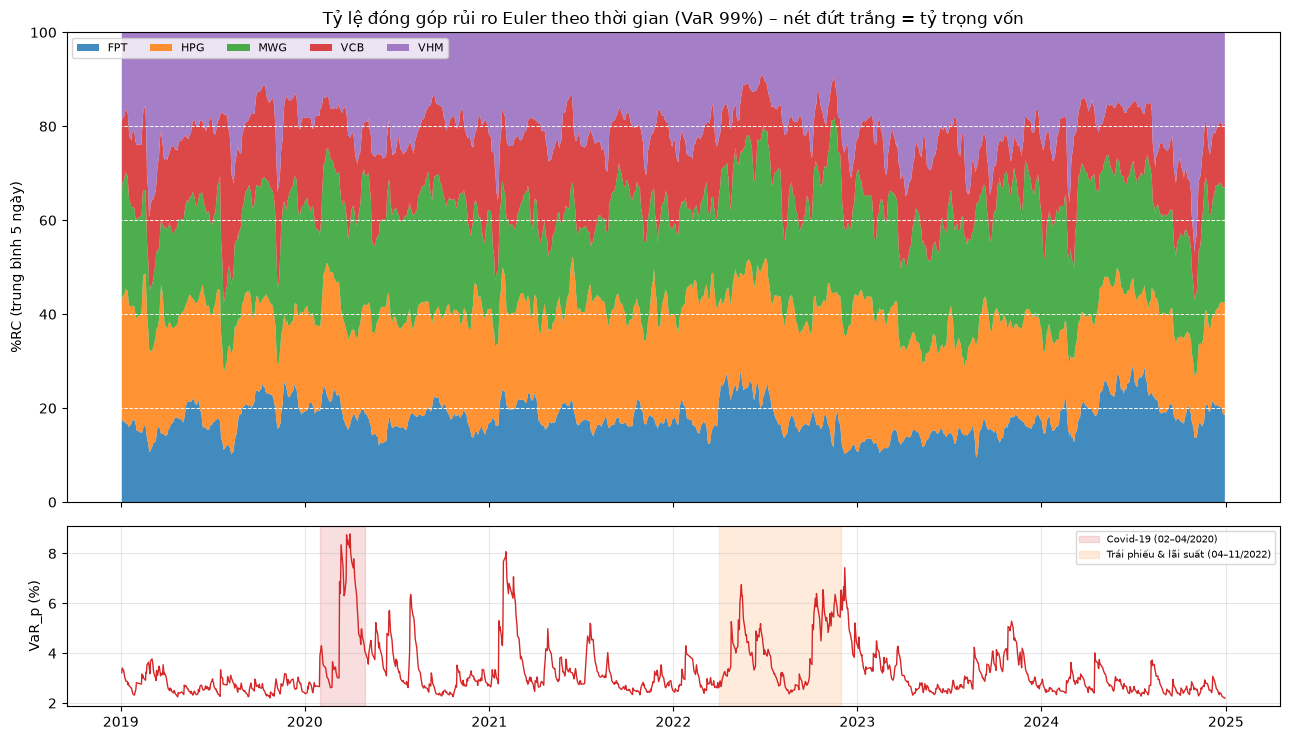

In [38]:
# ===================== 5.1 EULER RC =====================
z_cl = stats.norm.ppf(EULER_CL)


def euler(H, w):
    """Trả về VaR_p, MC-VaR (N), RC (N) cho một ma trận H (N×N)."""
    sp = np.sqrt(w @ H @ w)
    mc = z_cl * (H @ w) / sp
    rc = w * mc
    return z_cl * sp, mc, rc


Hw = np.einsum("tij,j->ti", H_t, w)
VaR_p_ts = z_cl * sigma_p.values
MC_ts = z_cl * Hw / sigma_p.values[:, None]
RC_ts = w * MC_ts
pct_rc = pd.DataFrame(RC_ts / VaR_p_ts[:, None] * 100, index=log_ret.index, columns=tickers)
err = np.abs(RC_ts.sum(axis=1) - VaR_p_ts).max()
print(f"Kiểm chứng tính cộng Euler: max_t |Σ RC_i − VaR_p| = {err:.2e} -> {'ĐẠT' if err < 1e-10 else 'KHÔNG ĐẠT'}")
print(f"Khớp VaR Normal {int(EULER_CL * 100)}% của TV4: "
      f"{np.allclose(VaR_p_ts, var_es[f'VaR_Normal_{int(EULER_CL * 100)}'].values)}")

VaR_f, MC_f, RC_f = euler(H_fcst, w)
tbl_fcst = pd.DataFrame({"w_i (%)": w * 100, "σ_i T+1 (%/ngày)": sigma_fcst.values * 100, "MC-VaR_i": MC_f,
                         "RC_i (%)": RC_f * 100, "%RC_i": RC_f / VaR_f * 100}, index=tickers)
tbl_fcst["%RC_i − w_i (điểm %)"] = tbl_fcst["%RC_i"] - tbl_fcst["w_i (%)"]
tbl_fcst.loc["TỔNG"] = [100, np.nan, np.nan, RC_f.sum() * 100, 100, 0]
print(f"\nDự báo phiên T+1 (sau {log_ret.index[-1].date()}): VaR_p {int(EULER_CL * 100)}% = {VaR_f:.4%} | Σ RC_i = {RC_f.sum():.4%}")
display(tbl_fcst.round(3))

# ---- Xuất chuỗi hàng ngày đầy đủ: MC-VaR, RC, %RC, VaR_p (giữ định dạng file cũ) ----
mc_df = pd.DataFrame(MC_ts, index=log_ret.index, columns=tickers)
rc_df = pd.DataFrame(RC_ts, index=log_ret.index, columns=tickers)
euler_daily = pd.concat({"MC_VaR": mc_df, "RC": rc_df, "PctRC": pct_rc / 100,
                         "Portfolio": pd.DataFrame({"VaR_p": VaR_p_ts}, index=log_ret.index)}, axis=1)
euler_daily.index.name = "Date"
euler_daily.to_csv(OUT["TV5"] / "euler_rc_timeseries.csv", encoding="utf-8-sig")

# ---- Hình: %RC làm mượt 5 ngày (bớt nhiễu); nét đứt trắng = tỷ trọng vốn tích luỹ ----
pct_sm = pct_rc.rolling(5, min_periods=1).mean()
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.6, 1]})
axes[0].stackplot(pct_sm.index, pct_sm.T.values, labels=tickers, alpha=0.85)
for c_ in np.cumsum(w)[:-1] * 100:
    axes[0].axhline(c_, color="white", ls="--", lw=0.7)
axes[0].set_ylim(0, 100); axes[0].set_ylabel("%RC (trung bình 5 ngày)")
axes[0].set_title(f"Tỷ lệ đóng góp rủi ro Euler theo thời gian (VaR {int(EULER_CL * 100)}%) – nét đứt trắng = tỷ trọng vốn")
axes[0].legend(ncol=N, fontsize=8, loc="upper left")
axes[1].plot(log_ret.index, VaR_p_ts * 100, color="tab:red", lw=1)
shade_stress(axes[1], alpha=0.15)
axes[1].set_ylabel("VaR_p (%)"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV5"] / "5_euler_rc_timeseries.png", dpi=150); plt.show()


## 5.2 Phân tích Stress Periods
**Tầng 1:** So sánh giai đoạn bình thường với (1) Covid-19, 02–04/2020 và (2) khủng hoảng trái phiếu doanh nghiệp, thanh khoản & lãi suất, 04–11/2022.
Hệ số đa dạng hoá $DR = \sum_i w_i\sigma_{i,t}/\sigma_{p,t}$ (DR = 1: không còn đa dạng hoá); lợi ích đa dạng hoá $= 1 - 1/DR$.

**Tầng 3:** đọc các câu hỏi của đề ngay trong phần in ra: mã đóng góp lớn nhất, mã tăng đóng góp mạnh nhất, tương quan thay đổi ra sao
và ảnh hưởng tới tổng rủi ro.

Tổng quan danh mục theo giai đoạn (lợi suất tích luỹ phụ thuộc độ dài giai đoạn – so sánh bằng dòng TB ngày):


,Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022)
Số phiên,1224.000,61.000,167.000
Lợi suất DM tích luỹ cả giai đoạn (%),341.643,-18.554,-27.088
Lợi suất DM TB ngày (%),0.121,-0.336,-0.189
Lợi suất DM TB năm hoá (%) – tham khảo,30.580,-84.785,-47.671
σ_p năm hoá (%),21.035,35.726,28.124
VaR_p 99% TB (%),3.083,5.235,4.121
Lỗ lớn nhất 1 ngày (%),7.215,7.212,5.007
Tương quan TB các cặp,0.358,0.459,0.378
Hệ số đa dạng hoá DR,1.434,1.324,1.396
Lợi ích đa dạng hoá 1 − 1/DR (%),30.101,24.236,28.240


Tỷ lệ đóng góp rủi ro %RC_i trung bình theo giai đoạn:


,Tỷ trọng w (%),Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022),Δ%RC Covid-19 (02–04/2020) (điểm %),Δ%RC Trái phiếu & lãi suất (04–11/2022) (điểm %)
FPT,20.0,17.67,20.10,19.60,2.43,1.93
HPG,20.0,22.22,22.15,24.44,-0.07,2.22
MWG,20.0,22.23,24.60,26.18,2.36,3.95
VCB,20.0,15.79,14.45,13.58,-1.33,-2.21
VHM,20.0,22.09,18.70,16.20,-3.39,-5.89


MC-VaR_i trung bình theo giai đoạn (thập phân):


,Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022)
FPT,0.0269,0.0504,0.0405
HPG,0.0347,0.0552,0.0513
MWG,0.0340,0.0644,0.0554
VCB,0.0242,0.0404,0.0266
VHM,0.0344,0.0514,0.0323



[Covid-19 (02–04/2020)]
  • Đóng góp rủi ro lớn nhất: MWG (24.6% VaR, tỷ trọng 20%).
  • Tăng đóng góp mạnh nhất so với bình thường: FPT (+2.4 điểm %); giảm mạnh nhất: VHM (-3.4 điểm %).
  • σ_p năm hoá: 21.0% → 35.7%; tương quan TB: 0.358 → 0.459; lợi ích đa dạng hoá: 30.1% → 24.2%.

[Trái phiếu & lãi suất (04–11/2022)]
  • Đóng góp rủi ro lớn nhất: MWG (26.2% VaR, tỷ trọng 20%).
  • Tăng đóng góp mạnh nhất so với bình thường: MWG (+3.9 điểm %); giảm mạnh nhất: VHM (-5.9 điểm %).
  • σ_p năm hoá: 21.0% → 28.1%; tương quan TB: 0.358 → 0.378; lợi ích đa dạng hoá: 30.1% → 28.2%.


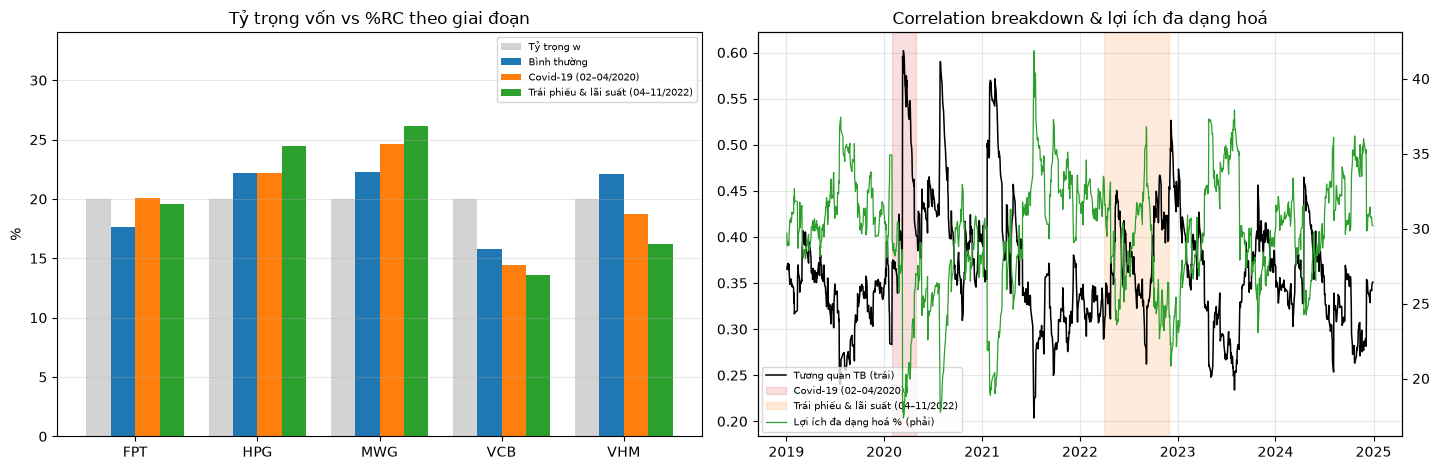

In [39]:
# ===================== 5.2 STRESS PERIODS =====================
ann = np.sqrt(TRADING_DAYS)
hits99 = (-var_es["r_p"] > var_es[f"VaR_Normal_{int(EULER_CL * 100)}"]).where(var_es.index >= bt.index[0])
DR = undiv / sigma_p
stress_summary = pd.DataFrame({name: {
    "Số phiên": int(m.sum()),
    "Lợi suất DM tích luỹ cả giai đoạn (%)": (np.exp(r_p[m].sum()) - 1) * 100,   # thay cho số năm hoá dễ gây hiểu nhầm
    "Lợi suất DM TB ngày (%)": r_p[m].mean() * 100,
    "Lợi suất DM TB năm hoá (%) – tham khảo": r_p[m].mean() * TRADING_DAYS * 100,
    "σ_p năm hoá (%)": sigma_p[m].mean() * ann * 100,
    f"VaR_p {int(EULER_CL * 100)}% TB (%)": VaR_p_ts[m].mean() * 100,
    "Lỗ lớn nhất 1 ngày (%)": -r_p[m].min() * 100,
    "Tương quan TB các cặp": avg_corr[m].mean(),
    "Hệ số đa dạng hoá DR": DR[m].mean(),
    "Lợi ích đa dạng hoá 1 − 1/DR (%)": (1 - 1 / DR[m]).mean() * 100,
    f"Tỷ lệ vi phạm VaR-N {int(EULER_CL * 100)}% (%)": hits99[m].mean() * 100,
} for name, m in masks.items()})
print("Tổng quan danh mục theo giai đoạn (lợi suất tích luỹ phụ thuộc độ dài giai đoạn – so sánh bằng dòng TB ngày):"); display(stress_summary.round(3))

prc_period = pd.DataFrame({name: pct_rc[m].mean() for name, m in masks.items()})
prc_period.insert(0, "Tỷ trọng w (%)", w * 100)
mc_period = pd.DataFrame({name: mc_df[m].mean() for name, m in masks.items()})     # MC-VaR trung bình theo giai đoạn
for name in STRESS:
    prc_period[f"Δ%RC {name} (điểm %)"] = prc_period[name] - prc_period["Bình thường"]
print("Tỷ lệ đóng góp rủi ro %RC_i trung bình theo giai đoạn:"); display(prc_period.round(2))
print("MC-VaR_i trung bình theo giai đoạn (thập phân):"); display(mc_period.round(4))

for name in STRESS:
    m = masks[name]
    top = prc_period[name].idxmax()
    up = prc_period[f"Δ%RC {name} (điểm %)"].idxmax()
    dn = prc_period[f"Δ%RC {name} (điểm %)"].idxmin()
    print(f"\n[{name}]")
    print(f"  • Đóng góp rủi ro lớn nhất: {top} ({prc_period.loc[top, name]:.1f}% VaR, tỷ trọng {w[idx_tk[top]] * 100:.0f}%).")
    print(f"  • Tăng đóng góp mạnh nhất so với bình thường: {up} ({prc_period.loc[up, f'Δ%RC {name} (điểm %)']:+.1f} điểm %); "
          f"giảm mạnh nhất: {dn} ({prc_period.loc[dn, f'Δ%RC {name} (điểm %)']:+.1f} điểm %).")
    print(f"  • σ_p năm hoá: {stress_summary.loc['σ_p năm hoá (%)', 'Bình thường']:.1f}% → {stress_summary.loc['σ_p năm hoá (%)', name]:.1f}%; "
          f"tương quan TB: {stress_summary.loc['Tương quan TB các cặp', 'Bình thường']:.3f} → {stress_summary.loc['Tương quan TB các cặp', name]:.3f}; "
          f"lợi ích đa dạng hoá: {stress_summary.loc['Lợi ích đa dạng hoá 1 − 1/DR (%)', 'Bình thường']:.1f}% → "
          f"{stress_summary.loc['Lợi ích đa dạng hoá 1 − 1/DR (%)', name]:.1f}%.")

cols_p = ["Bình thường"] + list(STRESS)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
xpos, bw = np.arange(N), 0.2
axes[0].bar(xpos - 1.5 * bw, w * 100, bw, color="lightgrey", label="Tỷ trọng w")
for j, (cn, col) in enumerate(zip(cols_p, ["tab:blue", "tab:orange", "tab:green"])):
    axes[0].bar(xpos + (j - 0.5) * bw, prc_period[cn].values, bw, color=col, label=cn)
axes[0].set_xticks(xpos); axes[0].set_xticklabels(tickers); axes[0].set_ylabel("%")
axes[0].set_title("Tỷ trọng vốn vs %RC theo giai đoạn"); axes[0].grid(alpha=0.3, axis="y")
axes[0].set_ylim(0, max(prc_period[cols_p].values.max(), w.max() * 100) * 1.3)
axes[0].legend(fontsize=7, loc="upper right")
l1, = axes[1].plot(avg_corr.index, avg_corr, color="black", lw=1.1, label="Tương quan TB (trái)")
ax2 = axes[1].twinx()
l2, = ax2.plot(DR.index, (1 - 1 / DR) * 100, color="tab:green", lw=0.9, label="Lợi ích đa dạng hoá % (phải)")
shade_stress(axes[1], alpha=0.15)
h_sh, l_sh = axes[1].get_legend_handles_labels()
axes[1].set_title("Correlation breakdown & lợi ích đa dạng hoá"); axes[1].grid(alpha=0.3)
axes[1].legend(h_sh + [l2], l_sh + [l2.get_label()], fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(OUT["TV5"] / "5_stress_periods.png", dpi=150); plt.show()


### 5.2b Kịch bản tương quan (Correlation Breakdown)
Giữ nguyên biến động dự báo hiện tại $\sigma_{T+1}$, thay ma trận tương quan bằng tương quan trung bình của từng giai đoạn và trường hợp xấu nhất ρ = 1
⇒ tách riêng tác động của **tương quan** lên VaR và %RC.

In [40]:
# ===================== 5.2b KỊCH BẢN TƯƠNG QUAN =====================
scen = {"ρ dự báo T+1 (DCC)": R_fcst}
scen.update({f"ρ TB {name}": R_t[m].mean(axis=0) for name, m in masks.items()})
scen["ρ = 1 (tệ nhất)"] = np.ones((N, N))
rows = {}
for name, R in scen.items():
    Hs = R * np.outer(sigma_fcst.values, sigma_fcst.values)
    v, _, rc = euler(Hs, w)
    rows[name] = {"VaR_p (%)": v * 100, **{f"%RC {tk}": rc[i] / v * 100 for i, tk in enumerate(tickers)}}
corr_scen = pd.DataFrame(rows).T
display(corr_scen.round(3))
base_var = corr_scen.iloc[0, 0]
for k in corr_scen.index[1:]:
    v = corr_scen.loc[k, "VaR_p (%)"]
    print(f"• Với {k}: VaR_p = {v:.2f}% ({(v / base_var - 1):+.1%} so với dự báo DCC {base_var:.2f}%)")

,VaR_p (%),%RC FPT,%RC HPG,%RC MWG,%RC VCB,%RC VHM
ρ dự báo T+1 (DCC),2.155,18.299,23.611,25.280,14.099,18.711
ρ TB Bình thường,2.163,18.886,22.895,24.649,14.412,19.157
ρ TB Covid-19 (02–04/2020),2.339,18.212,22.750,25.010,14.665,19.363
ρ TB Trái phiếu & lãi suất (04–11/2022),2.201,18.903,22.330,25.268,14.130,19.369
ρ = 1 (tệ nhất),3.090,18.092,21.843,23.533,16.258,20.274


• Với ρ TB Bình thường: VaR_p = 2.16% (+0.3% so với dự báo DCC 2.16%)
• Với ρ TB Covid-19 (02–04/2020): VaR_p = 2.34% (+8.5% so với dự báo DCC 2.16%)
• Với ρ TB Trái phiếu & lãi suất (04–11/2022): VaR_p = 2.20% (+2.1% so với dự báo DCC 2.16%)
• Với ρ = 1 (tệ nhất): VaR_p = 3.09% (+43.4% so với dự báo DCC 2.16%)


### 5.2c Danh mục cân bằng rủi ro (Equal Risk Contribution) – tham khảo cho khuyến nghị
Tìm w sao cho mọi mã đóng góp như nhau: $RC_i = VaR_p/N$ (thuật toán lặp đơn giản trên $H_{T+1}$).

In [41]:
# ===================== 5.2c RISK PARITY (ERC) =====================
def risk_parity(Hm, n_iter=1000, tol=1e-12):
    wv = np.ones(len(Hm)) / len(Hm)
    for _ in range(n_iter):
        mrc = Hm @ wv
        new = 1 / mrc
        new /= new.sum()
        new = 0.5 * wv + 0.5 * new                      # bước giảm chấn cho hội tụ ổn định
        if np.abs(new - wv).max() < tol:
            break
        wv = new
    return wv


w_erc = risk_parity(H_fcst)
v_erc, _, rc_erc = euler(H_fcst, w_erc)
rp_table = pd.DataFrame({"w hiện tại (%)": w * 100, "%RC hiện tại": RC_f / VaR_f * 100,
                         "w ERC (%)": w_erc * 100, "%RC ERC": rc_erc / v_erc * 100}, index=tickers)
for name, m in masks.items():                           # ERC theo H_t trung bình của từng giai đoạn (stress)
    if name != "Bình thường":
        rp_table[f"ERC theo H TB {name} (%)"] = risk_parity(H_t[m].mean(axis=0)) * 100
display(rp_table.round(2))
print(f"VaR_p {int(EULER_CL * 100)}% (T+1): hiện tại = {VaR_f:.3%} | danh mục ERC = {v_erc:.3%}")

,w hiện tại (%),%RC hiện tại,w ERC (%),%RC ERC,ERC theo H TB Covid-19 (02–04/2020) (%),ERC theo H TB Trái phiếu & lãi suất (04–11/2022) (%)
FPT,20.0,18.30,21.17,20.0,21.21,19.47
HPG,20.0,23.61,16.99,20.0,19.55,15.66
MWG,20.0,25.28,16.13,20.0,16.54,14.61
VCB,20.0,14.10,25.35,20.0,23.39,27.15
VHM,20.0,18.71,20.36,20.0,19.31,23.11


VaR_p 99% (T+1): hiện tại = 2.155% | danh mục ERC = 2.092%


## 5.3 Diễn giải cốt lõi & Khuyến nghị quản trị rủi ro

In [42]:
# ===================== 5.3 KHUYẾN NGHỊ TỰ ĐỘNG =====================
over = tbl_fcst.drop("TỔNG")["%RC_i − w_i (điểm %)"].sort_values(ascending=False)
lines = ["KHUYẾN NGHỊ QUẢN TRỊ RỦI RO (sinh tự động từ kết quả – cần biên tập khi viết báo cáo)", "=" * 80,
         "1. Tập trung rủi ro hiện tại (T+1): " + ", ".join(
             f"{tk} gánh {tbl_fcst.loc[tk, '%RC_i']:.1f}% rủi ro với {tbl_fcst.loc[tk, 'w_i (%)']:.0f}% vốn"
             for tk in over.index[over > 0]) + " -> ứng viên GIẢM tỷ trọng.",
         "   Mã đóng góp rủi ro thấp hơn tỷ trọng (đa dạng hoá tốt): " + ", ".join(over[over <= 0].sort_values().index) + "."]
for i, name in enumerate(STRESS, start=1):
    s = stress_summary[name]; nrm = stress_summary["Bình thường"]
    up = prc_period[f"Δ%RC {name} (điểm %)"].idxmax()
    lines.append(f"2.{i} {name}: σ_p tăng {s['σ_p năm hoá (%)'] / nrm['σ_p năm hoá (%)']:.2f} lần, tương quan TB "
                 f"{nrm['Tương quan TB các cặp']:.2f} → {s['Tương quan TB các cặp']:.2f}, lợi ích đa dạng hoá "
                 f"{nrm['Lợi ích đa dạng hoá 1 − 1/DR (%)']:.1f}% → {s['Lợi ích đa dạng hoá 1 − 1/DR (%)']:.1f}%; "
                 f"{up} tăng đóng góp mạnh nhất ({prc_period.loc[up, f'Δ%RC {name} (điểm %)']:+.1f} điểm %).")
lines += [
    "3. Khi thị trường vào giai đoạn căng thẳng (σ_p hoặc tương quan TB vượt ngưỡng lịch sử): giảm tỷ trọng các mã có %RC − w lớn nhất,"
    " chuyển dần về danh mục ERC (bảng risk parity), và/hoặc giảm TỔNG mức đầu tư thay vì chỉ hoán đổi mã, vì tương quan tăng làm đa dạng hoá giữa cổ phiếu trong nước kém hiệu quả.",
    "4. Đa dạng hoá ngành: nên duy trì (mã khác ngành có tương quan thấp hơn), NHƯNG lợi ích này suy giảm trong khủng hoảng (DR giảm) -> "
    "cần bổ sung tài sản ít tương quan với cổ phiếu (trái phiếu chính phủ, tiền gửi, vàng) cho danh mục lớn.",
    "5. Dùng Euler RC như hạn mức: đặt trần %RC_i (ví dụ ≤ 30% VaR) và cảnh báo sớm khi %RC_i − w_i > 5 điểm %, theo dõi hằng ngày bằng H_t từ DCC; "
    "hạn mức VaR theo mã = %RC_i × VaR tổng; vượt trần -> tái cân bằng. Hiện tại vượt ngưỡng cảnh báo 5 điểm %: "
    + (", ".join(over.index[over > 5]) or "không có") + ".",
    f"6. Backtest TV4 (trong mẫu, VaR 99%): " + "; ".join(f"{r['Phương pháp']}: {r['Vi phạm']}/{r['Kỳ vọng']:.0f} vi phạm ({r['Kết luận']})" for _, r in bt_table.iterrows()
                                                         if r["Mức tin cậy"] == "99%") + ". "
    + "Ngoài mẫu (ước lượng lại mỗi {} ngày): ".format(REFIT)
    + "; ".join(f"VaR {lv}: tốt nhất theo quantile loss = "
                f"{oos_bt[oos_bt['Mức tin cậy'] == lv].set_index('Phương pháp')['Quantile loss (x1e4)'].idxmin()}, "
                f"mô hình bị đánh dấu thổi phồng/đánh giá thấp = "
                f"{', '.join(oos_bt[(oos_bt['Mức tin cậy'] == lv) & oos_bt['Đánh giá'].str.contains('THẤP|THỔI PHỒNG')]['Phương pháp']) or 'không có'}"
                for lv in ['95%', '99%'])
    + ". Chọn mô hình báo cáo dựa trên kết quả ngoài mẫu trước khi dùng cho tính vốn.",
]
rec_text = "\n".join(lines)
print(rec_text)
(OUT["TV5"] / "recommendations.txt").write_text(rec_text, encoding="utf-8")

with pd.ExcelWriter(OUT["TV5"] / "TV5_euler_stress.xlsx", engine="openpyxl") as xw:
    integration.to_excel(xw, sheet_name="Kiem_tra_tich_hop", index=False)
    tbl_fcst.to_excel(xw, sheet_name="Euler_T+1")
    stress_summary.to_excel(xw, sheet_name="Stress_tong_quan")
    prc_period.to_excel(xw, sheet_name="PctRC_theo_giai_doan")
    corr_scen.to_excel(xw, sheet_name="Kich_ban_tuong_quan")
    rp_table.to_excel(xw, sheet_name="Risk_parity")
    mc_period.to_excel(xw, sheet_name="MC_VaR_theo_giai_doan")
    pct_rc.to_excel(xw, sheet_name="PctRC_hang_ngay")
print(f"\n✔ HOÀN TẤT TOÀN BỘ PIPELINE. Kết quả nằm trong: {ROOT_OUT}")

KHUYẾN NGHỊ QUẢN TRỊ RỦI RO (sinh tự động từ kết quả – cần biên tập khi viết báo cáo)
1. Tập trung rủi ro hiện tại (T+1): MWG gánh 25.3% rủi ro với 20% vốn, HPG gánh 23.6% rủi ro với 20% vốn -> ứng viên GIẢM tỷ trọng.
   Mã đóng góp rủi ro thấp hơn tỷ trọng (đa dạng hoá tốt): VCB, FPT, VHM.
2.1 Covid-19 (02–04/2020): σ_p tăng 1.70 lần, tương quan TB 0.36 → 0.46, lợi ích đa dạng hoá 30.1% → 24.2%; FPT tăng đóng góp mạnh nhất (+2.4 điểm %).
2.2 Trái phiếu & lãi suất (04–11/2022): σ_p tăng 1.34 lần, tương quan TB 0.36 → 0.38, lợi ích đa dạng hoá 30.1% → 28.2%; MWG tăng đóng góp mạnh nhất (+3.9 điểm %).
3. Khi thị trường vào giai đoạn căng thẳng (σ_p hoặc tương quan TB vượt ngưỡng lịch sử): giảm tỷ trọng các mã có %RC − w lớn nhất, chuyển dần về danh mục ERC (bảng risk parity), và/hoặc giảm TỔNG mức đầu tư thay vì chỉ hoán đổi mã, vì tương quan tăng làm đa dạng hoá giữa cổ phiếu trong nước kém hiệu quả.
4. Đa dạng hoá ngành: nên duy trì (mã khác ngành có tương quan thấp hơn), NHƯNG lợi ích

### TV5 – Gợi ý trả lời vấn đáp
**Câu 1 – Vì sao mã có tỷ trọng nhỏ vẫn có thể đóng góp rủi ro lớn nhất?** $RC_i = w_i \cdot z\,(H_tw)_i/\sigma_p$ phụ thuộc không chỉ $w_i$ mà còn
**biến động riêng** $\sigma_i$ và **hiệp phương sai với phần còn lại của danh mục** $(H_tw)_i = \sum_j w_j\rho_{ij}\sigma_i\sigma_j$. Một mã rất biến
động và tương quan cao với các mã khác có MC-VaR lớn, nên dù w nhỏ vẫn có thể có RC lớn nhất; ngược lại mã có tương quan thấp/âm đóng góp ít,
thậm chí âm (phòng hộ).

**Câu 2 – Correlation breakdown ảnh hưởng Euler contribution thế nào?** Khi tương quan tăng vọt, $(H_tw)_i$ của mọi mã tăng ⇒ VaR danh mục tăng
(bảng kịch bản: ρ = 1 là trường hợp tệ nhất, VaR = tổng VaR từng mã) và lợi ích đa dạng hoá biến mất. Đóng góp rủi ro dịch chuyển về các mã
**biến động cao nhất**, vì khi ρ → 1 thì %RC_i → $w_i\sigma_i/\sum_j w_j\sigma_j$. Những mã vốn đóng vai trò đa dạng hoá (tương quan thấp lúc bình thường)
mất tác dụng ⇒ hạn mức rủi ro tính trong giai đoạn bình thường sẽ bị vượt.